In [1]:
!pip install medpy monai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.3/156.3 kB 3.9 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 39.9 MB/s eta 0:00:00a 0:00:01
  Created wheel for medpy: filename=MedPy-0.5.2-py3-none-any.whl size=224710 sha256=33c571799a5b439034bc66c1be339223ffa89c439fb10162ebc41750d54651e7
  Stored in directory: /root/.cache/pip/wheels/89/5a/f8/b3def53b9c2133d2f8698ea2173bb5df63bd8e761ce8e9aec9
Successfully built medpy


# segresnet

In [2]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from medpy.metric.binary import dc, jc, hd95
from monai.networks.nets import SegResNet

# ---------------- 0. CONFIGURATION ----------------
# Trỏ thẳng vào thư mục database để có thể lôi cả training và testing ra
BASE_DIR = Path("/kaggle/input/datasets/samdazel/automated-cardiac-diagnosis-challenge-miccai17/database")
TRAIN_DIR = BASE_DIR / "training"
TEST_DIR = BASE_DIR / "testing"

SAVE_DIR = Path("./segresnet3d_acdc_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 16)
NUM_CLASSES = 4
BATCH_SIZE = 2
EPOCHS = 100
LR = 1e-4
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, NUM_CLASSES).permute(0,4,1,2,3).float()
        dims = (0,2,3,4)
        inter = torch.sum(pred[:,1:] * target_oh[:,1:], dims)
        union = torch.sum(pred[:,1:] + target_oh[:,1:], dims)
        return 1 - ((2*inter + self.smooth) / (union + self.smooth)).mean()

# ---------------- 2. DATASET (RESIZE ONLY – NO CROP) ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt  = nib.load(gt_p).get_fdata().astype(np.int64)

        zoom = (
            TARGET_SIZE[0] / img.shape[0],
            TARGET_SIZE[1] / img.shape[1],
            TARGET_SIZE[2] / img.shape[2]
        )
        img = ndi.zoom(img, zoom, order=1)
        gt  = ndi.zoom(gt,  zoom, order=0)

        if self.augment:
            if random.random() > 0.5:
                ax = random.randint(0,2)
                img = np.flip(img, ax).copy()
                gt  = np.flip(gt, ax).copy()

        img = (img - img.mean()) / (img.std() + 1e-6)

        return {
            "image": torch.from_numpy(img[None]).float(),
            "label": torch.from_numpy(gt).long()
        }

# ---------------- 3. METRICS ----------------
def get_metrics(p, g):
    res = {}
    for cl, name in zip([1,2,3], ['RV','MYO','LV']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0:
            res[name] = (0.0, 0.0, 50.0)
            continue
        res[name] = (
            dc(pc, gc),
            jc(pc, gc),
            hd95(pc, gc) if pc.sum()>0 else 50.0
        )
    return res

# ---------------- 4. GỘP DATA 150 BN & CHIA CHUẨN (80-20-50) ----------------
patient_data = {}
for folder_dir in [TRAIN_DIR, TEST_DIR]:
    if not folder_dir.exists(): continue
    for p in sorted(folder_dir.iterdir()):
        if not p.is_dir() or not p.name.startswith("patient"): continue
        
        pid = p.name
        info_file = p / "Info.cfg"
        disease = "NOR" # Mặc định
        
        # Đọc nhãn bệnh để chia tầng (Stratify)
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if line.startswith("Group:"): 
                        disease = line.split(":")[1].strip()
        
        gt_nodes = list(p.glob("*_frame*_gt.nii*"))
        scans = []
        for gt_node in gt_nodes:
            img_node = gt_node.parent / gt_node.name.replace("_gt", "")
            if img_node.exists():
                scans.append((str(img_node), str(gt_node)))
                
        if scans:
            patient_data[pid] = {'disease': disease, 'scans': scans}

p_ids = list(patient_data.keys())
p_labels = [patient_data[pid]['disease'] for pid in p_ids]

# CHIA TẦNG (STRATIFY) ĐỂ ĐỀU BỆNH: 80 Train - 20 Val - 50 Test
# Lấy 70 ca ra khỏi 150 ca => Còn 80 Train
train_ids, temp_ids, train_labels, temp_labels = train_test_split(
    p_ids, p_labels, test_size=70, random_state=SEED, stratify=p_labels
)
# Tách 70 ca Temp thành 50 Test và 20 Val
val_ids, test_ids, val_labels, test_labels = train_test_split(
    temp_ids, temp_labels, test_size=50, random_state=SEED, stratify=temp_labels
)

tr_items = [scan for pid in train_ids for scan in patient_data[pid]['scans']]
va_items = [scan for pid in val_ids for scan in patient_data[pid]['scans']]
te_items = [scan for pid in test_ids for scan in patient_data[pid]['scans']]

print(f"✅ Đã chia tầng xong: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
# Má có thể in thử tỉ lệ bệnh ở tập test để kiểm tra:
print(f"Tỉ lệ bệnh tập Test: {pd.Series(test_labels).value_counts().to_dict()}")

loaders = {
    "train": DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    "val":   DataLoader(VolumeDataset(va_items), 1)
}

print(f"Tổng hợp & Chia Data: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
print("-"*170)

# ---------------- 5. MODEL ----------------
model = SegResNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    init_filters=32,
    dropout_prob=0.2
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, "max", patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler("cuda")

best_dice = 0.0

# ---------------- 6. CSV LOG ----------------
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, "w", newline="") as f:
    csv.writer(f).writerow([
        "epoch","tr_loss","va_loss","tr_dice",
        "va_dice","va_iou","va_hd95",
        "rv_d","myo_d","lv_d","time" 
    ])

# ---------------- 7. TRAINING LOOP ----------------
for ep in range(1, EPOCHS+1):
    t0 = time.time()
    model.train()
    tr_l, tr_d = [], []

    for b in tqdm(loaders["train"], desc=f"Epoch {ep:02d}", leave=False):
        img = b["image"].to(DEVICE)
        lab = b["label"].to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            out = model(img)
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_l.append(loss.item())
        tr_d.append(dc((out.argmax(1)>0).cpu().numpy(), (lab>0).cpu().numpy()))

    # ---------------- VALIDATION ----------------
    model.eval()
    va_l, acc = [], {"RV":[], "MYO":[], "LV":[]}

    with torch.no_grad():
        for b in loaders["val"]:
            img = b["image"].to(DEVICE)
            lab = b["label"].to(DEVICE)

            with torch.amp.autocast("cuda"):
                out = model(img)
                loss = ce_criterion(out, lab) + dice_criterion(out, lab)
            
            va_l.append(loss.item())

            p = out.argmax(1).cpu().numpy()[0]
            g = lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for k in acc: acc[k].append(m[k])

    tr_loss = np.mean(tr_l)
    va_loss = np.mean(va_l)
    tr_dice = np.mean(tr_d)

    stats = {k: np.mean(acc[k],0) for k in acc}
    va_dice = np.mean([stats[k][0] for k in stats])
    va_iou  = np.mean([stats[k][1] for k in stats])
    va_hd95 = np.mean([stats[k][2] for k in stats])

    scheduler.step(va_dice)
    t_total = time.time() - t0

    print(
        f"Ep {ep:02d} | {t_total:5.1f}s | "
        f"Tr.Loss {tr_loss:.4f} | Va.Loss {va_loss:.4f} | "
        f"Tr.Dice {tr_dice:.4f} | Va.Dice {va_dice:.4f} | "
        f"IoU {va_iou:.4f} | HD95 {va_hd95:.2f}"
    )

    with open(CSV_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            ep, tr_loss, va_loss, tr_dice,
            va_dice, va_iou, va_hd95,
            stats["RV"][0], stats["MYO"][0], stats["LV"][0], t_total
        ])

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), SAVE_DIR/"best_model.pth")
        print(f"New Best Model Saved | Dice {best_dice:.4f}")

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
2026-06-11 04:30:51.787597: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781152252.158887      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781152252.268173      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781152253.227794      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781152253.227838      57 computation_placer.cc:1

✅ Đã chia tầng xong: Train 80 BN | Val 20 BN | Test 50 BN
Tỉ lệ bệnh tập Test: {'MINF': 10, 'DCM': 10, 'NOR': 10, 'RV': 10, 'HCM': 10}
Tổng hợp & Chia Data: Train 80 BN | Val 20 BN | Test 50 BN
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Ep 01 |  29.9s | Tr.Loss 1.7038 | Va.Loss 1.5473 | Tr.Dice 0.0014 | Va.Dice 0.0002 | IoU 0.0001 | HD95 49.34
New Best Model Saved | Dice 0.0002


Ep 02 |  21.0s | Tr.Loss 1.4883 | Va.Loss 1.4334 | Tr.Dice 0.1954 | Va.Dice 0.1263 | IoU 0.0935 | HD95 42.08
New Best Model Saved | Dice 0.1263


Ep 03 |  23.7s | Tr.Loss 1.3795 | Va.Loss 1.3246 | Tr.Dice 0.5043 | Va.Dice 0.3185 | IoU 0.2312 | HD95 27.02
New Best Model Saved | Dice 0.3185


Ep 04 |  23.5s | Tr.Loss 1.2729 | Va.Loss 1.2124 | Tr.Dice 0.6074 | Va.Dice 0.3695 | IoU 0.2737 | HD95 24.50
New Best Model Saved | Dice 0.3695


... (92 outputs left out)

Ep 97 |  25.8s | Tr.Loss 0.1179 | Va.Loss 0.1783 | Tr.Dice 0.9533 | Va.Dice 0.8610 | IoU 0.7631 | HD95 1.42


Ep 98 |  25.8s | Tr.Loss 0.1195 | Va.Loss 0.1837 | Tr.Dice 0.9521 | Va.Dice 0.8573 | IoU 0.7590 | HD95 1.48


Ep 99 |  25.8s | Tr.Loss 0.1200 | Va.Loss 0.1942 | Tr.Dice 0.9527 | Va.Dice 0.8472 | IoU 0.7543 | HD95 1.74


Ep 100 |  26.0s | Tr.Loss 0.1145 | Va.Loss 0.1961 | Tr.Dice 0.9549 | Va.Dice 0.8471 | IoU 0.7542 | HD95 1.72


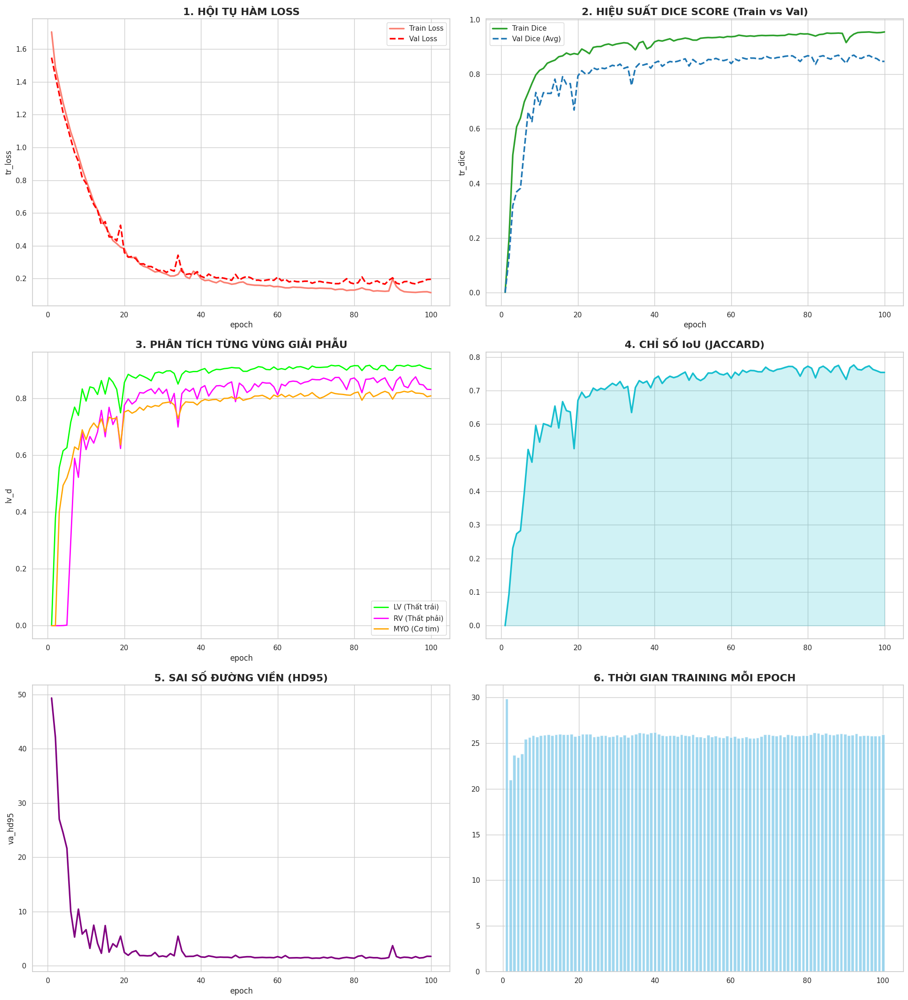


            BÁO CÁO KẾT QUẢ MÔ HÌNH SEGRESNET-3D            
🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: 92
  > Dice Score (Avg)          :     0.8700
  > IoU (Jaccard)             :     0.7764
  > HD95                      :    1.43 mm
  > Dice - LV                 :     0.9151
  > Dice - RV                 :     0.8749
  > Dice - MYO                :     0.8200


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đảm bảo định nghĩa lại đường dẫn nếu chạy cell này độc lập
SAVE_DIR = Path("./segresnet3d_acdc_results")
CSV_PATH = SAVE_DIR / "training_log.csv"

# ================= 8. DASHBOARD & REPORT (MÃ CỦA MÁ) =================
def plot_dashboard_matched(log_path):
    if not log_path.exists():
        print(f"❌ Lỗi: Không tìm thấy file log tại {log_path}")
        return

    df = pd.read_csv(log_path)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.2)

    # --- BIỂU ĐỒ 1: LOSS ---
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='tr_loss', label='Train Loss', color='salmon', linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='va_loss', label='Val Loss', color='red', linewidth=2.5, linestyle='--')
    axes[0, 0].set_title('1. HỘI TỤ HÀM LOSS', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 2: DICE TỔNG QUÁT ---
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='tr_dice', label='Train Dice', color='#2ca02c', linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='va_dice', label='Val Dice (Avg)', color='#1f77b4', linewidth=2.5, linestyle='--')
    axes[0, 1].set_title('2. HIỆU SUẤT DICE SCORE (Train vs Val)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 3: DICE CHI TIẾT ---
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='lv_d', label='LV (Thất trái)', color='lime', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='rv_d', label='RV (Thất phải)', color='magenta', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='myo_d', label='MYO (Cơ tim)', color='orange', linewidth=2)
    axes[1, 0].set_title('3. PHÂN TÍCH TỪNG VÙNG GIẢI PHẪU', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 4: IoU ---
    axes[1, 1].fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
    axes[1, 1].plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Mean IoU')
    axes[1, 1].set_title('4. CHỈ SỐ IoU (JACCARD)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 5: HD95 ---
    sns.lineplot(ax=axes[2, 0], data=df, x='epoch', y='va_hd95', color='purple', linewidth=2.5)
    axes[2, 0].set_title('5. SAI SỐ ĐƯỜNG VIỀN (HD95)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 6: THỜI GIAN ---
    axes[2, 1].bar(df['epoch'], df['time'], color='skyblue', alpha=0.8)
    axes[2, 1].set_title('6. THỜI GIAN TRAINING MỖI EPOCH', fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.savefig(SAVE_DIR / "final_dashboard.png", dpi=300)
    plt.show()

def print_report_matched(log_path):
    if not log_path.exists(): return
    df = pd.read_csv(log_path)
    best_row = df.iloc[df['va_dice'].idxmax()]
    
    print("\n" + "="*60)
    print(f"{'BÁO CÁO KẾT QUẢ MÔ HÌNH SEGRESNET-3D':^60}")
    print("="*60)
    print(f"🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: {int(best_row['epoch'])}")
    for l, v in [["Dice Score (Avg)", f"{best_row['va_dice']:.4f}"], ["IoU (Jaccard)", f"{best_row['va_iou']:.4f}"], 
                 ["HD95", f"{best_row['va_hd95']:.2f} mm"], ["Dice - LV", f"{best_row['lv_d']:.4f}"], 
                 ["Dice - RV", f"{best_row['rv_d']:.4f}"], ["Dice - MYO", f"{best_row['myo_d']:.4f}"]]:
        print(f"  > {l:<25} : {v:>10}")
    print("="*60)

# Thực thi vẽ biểu đồ sau khi train xong
plot_dashboard_matched(CSV_PATH)
print_report_matched(CSV_PATH)

In [4]:
# -------------------------------------------------------------------------
# CELL 9: ĐÁNH GIÁ ĐỊNH LƯỢNG TRÊN TẬP TEST (BẢNG TỔNG KẾT GỌN GÀNG)
# -------------------------------------------------------------------------
from torch.utils.data import DataLoader
from monai.data import Dataset
import numpy as np
import torch
from tqdm.auto import tqdm
from pathlib import Path

# Sửa lại đường dẫn cho chuẩn (Trỏ thẳng vào thư mục input của Kaggle)
model_path = Path("/kaggle/working/segresnet3d_acdc_results/best_model.pth")

if model_path.exists():
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    print(f"✅ Đã load weights từ: {model_path}")
else:
    print(f"❌ Chưa tìm thấy file weights tại {model_path}")

model.eval()

# 2. Tạo Test Loader (Sử dụng đúng VolumeDataset của bạn để Resize chuẩn)
# augment=False để không lật ảnh lung tung
test_dataset = VolumeDataset(te_items, augment=False) 
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# 3. Khởi tạo biến lưu trữ kết quả
metrics_storage = {
    'LV': {'dice': [], 'iou': [], 'hd95': []},
    'RV': {'dice': [], 'iou': [], 'hd95': []},
    'MYO': {'dice': [], 'iou': [], 'hd95': []}
}
overall_metrics = {'dice': [], 'iou': [], 'hd95': []}

print(f"🚀 Đang đánh giá trên {len(te_items)} mẫu tập Test...")

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing"):
        # Lấy dữ liệu và đưa lên GPU
        img = batch["image"].to(DEVICE)
        lab = batch["label"].to(DEVICE)
        
        # Inference (Dự đoán)
        out = model(img)
        
        # Xử lý kết quả
        p = torch.argmax(out, dim=1).cpu().numpy()[0]
        g = lab.cpu().numpy()[0]
        
        # Tính metrics bằng hàm get_metrics của bạn
        m = get_metrics(p, g)
        
        sample_dices = []
        sample_ious = []
        sample_hds = []
        
        # Lưu lại từng lớp
        for cls_name in ['LV', 'RV', 'MYO']:
            d, i, h = m[cls_name]
            
            metrics_storage[cls_name]['dice'].append(d)
            metrics_storage[cls_name]['iou'].append(i)
            metrics_storage[cls_name]['hd95'].append(h)
            
            sample_dices.append(d)
            sample_ious.append(i)
            sample_hds.append(h)
        
        # Tính trung bình cộng (Average) cho mẫu này (Overall)
        overall_metrics['dice'].append(np.mean(sample_dices))
        overall_metrics['iou'].append(np.mean(sample_ious))
        overall_metrics['hd95'].append(np.mean(sample_hds))

# 4. In Báo Cáo Kết Quả Gọn Gàng
print("\n" + "="*65)
print(f"{'KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST':^65}")
print("="*65)

# Tính trung bình toàn bộ tập test
avg_dice = np.mean(overall_metrics['dice'])
avg_iou = np.mean(overall_metrics['iou'])
avg_hd95 = np.mean(overall_metrics['hd95'])

print(f"⭐ Dice Score trung bình (All Classes): {avg_dice:.4f}")
print(f"⭐ IoU trung bình (All Classes):        {avg_iou:.4f}")
print(f"⭐ HD95 trung bình (All Classes):       {avg_hd95:.2f} mm")
print("-" * 65)

# In bảng chi tiết từng lớp
print(f"{'Lớp (Class)':<15} | {'Dice':<10} | {'IoU':<10} | {'HD95 (mm)':<10}")
print("-" * 65)

for cls_name in ['LV', 'RV', 'MYO']:
    d_mean = np.mean(metrics_storage[cls_name]['dice'])
    i_mean = np.mean(metrics_storage[cls_name]['iou'])
    h_mean = np.mean(metrics_storage[cls_name]['hd95'])
    
    print(f"{cls_name:<15} | {d_mean:.4f}     | {i_mean:.4f}     | {h_mean:.2f}")

print("="*65)

✅ Đã load weights từ: /kaggle/working/segresnet3d_acdc_results/best_model.pth
🚀 Đang đánh giá trên 100 mẫu tập Test...


Testing:   0%|          | 0/100 [00:00<?, ?it/s]


            KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST             
⭐ Dice Score trung bình (All Classes): 0.8635
⭐ IoU trung bình (All Classes):        0.7689
⭐ HD95 trung bình (All Classes):       1.42 mm
-----------------------------------------------------------------
Lớp (Class)     | Dice       | IoU        | HD95 (mm) 
-----------------------------------------------------------------
LV              | 0.9093     | 0.8410     | 1.28
RV              | 0.8501     | 0.7502     | 1.75
MYO             | 0.8313     | 0.7155     | 1.23


🚀 Đang khởi tạo XAI Dashboard cho 3 mẫu...


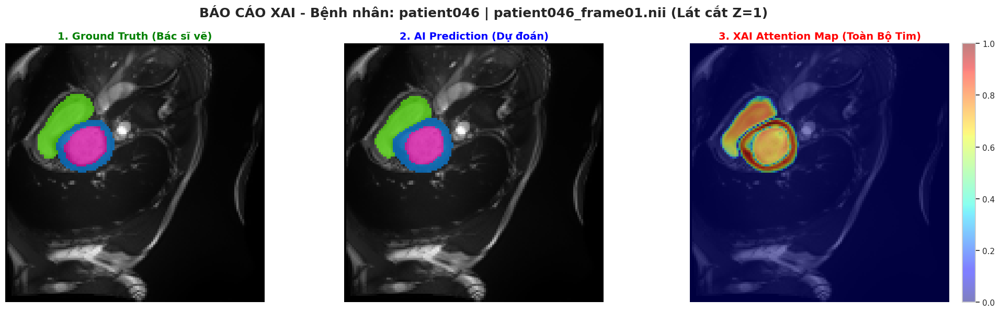

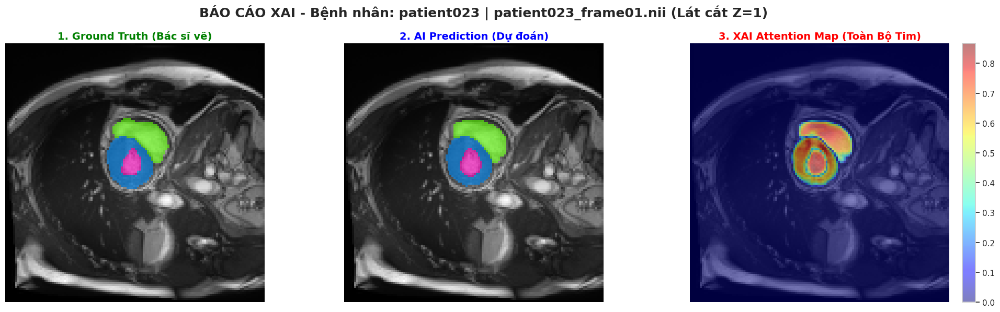

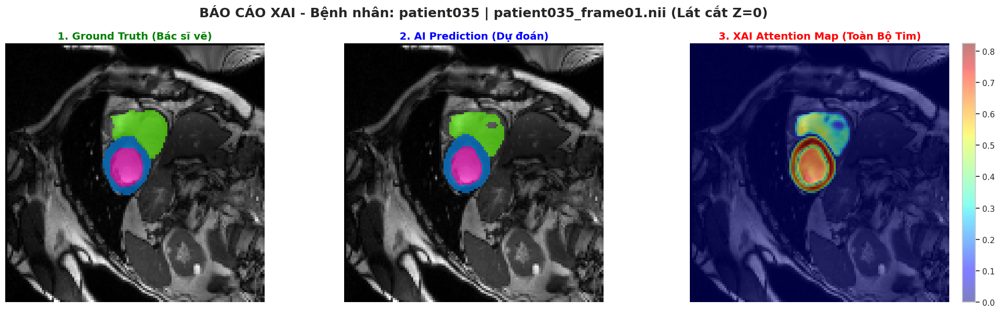

✅ Hoàn tất quá trình trích xuất XAI Dashboard!


In [5]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random

# ==============================================================================
# 1. CLASS GRAD-CAM 3D (CORE ENGINE)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        
        # Đăng ký hook để "nghe lén" dữ liệu khi chạy qua layer này
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        """Quan trọng: Gỡ bỏ hook để giải phóng bộ nhớ"""
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx):
        # Reset gradient cũ
        self.model.zero_grad()
        
        # 1. Forward Pass (Chạy lại forward để tạo đồ thị tính toán mới)
        output = self.model(input_tensor)
        
        # 2. Backward Pass: Chỉ quan tâm đến Class đích (class_idx)
        score = output[0, class_idx].sum()
        # Bỏ retain_graph=True vì ta đã forward lại từ đầu, tránh lỗi tràn bộ nhớ GPU
        score.backward() 

        # 3. Tạo CAM
        # Global Average Pooling trên gradients (trọng số alpha)
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        
        # Nhân trọng số với activation map
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        
        # ReLU: Chỉ lấy các đặc trưng có ảnh hưởng dương tính (tích cực)
        cam = F.relu(cam).detach().cpu().numpy()
        
        # Chuẩn hóa về [0, 1] để hiển thị
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        
        return cam

# ==============================================================================
# 2. DASHBOARD VISUALIZATION FUNCTION
# ==============================================================================
def visualize_xai_prediction_dashboard(model, items, device="cuda", num_samples=6):
    """
    Hàm tổng hợp: Chạy dự đoán + Tính Grad-CAM + Vẽ Dashboard 3 cột
    """
    print(f"🚀 Đang khởi tạo XAI Dashboard cho {num_samples} mẫu...")
    
    model.eval()
    
    # --- A. TỰ ĐỘNG TÌM TARGET LAYER ---
    # Lấy layer Conv3D cuối cùng của SegResNet làm Target Layer
    conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
    if not conv_layers:
        print("❌ Lỗi: Không tìm thấy layer Conv3D nào trong model!")
        return
    target_layer = conv_layers[-1]
    
    # Khởi tạo công cụ Grad-CAM
    cam_extractor = GradCAM3D(model, target_layer)
    
    # Load dataset test (Tắt augment để giữ nguyên gốc ảnh)
    dataset = VolumeDataset(items, augment=False) 
    
    # Chọn mẫu ngẫu nhiên
    sample_indices = random.sample(range(len(items)), min(len(items), num_samples))

    # --- B. VÒNG LẶP XỬ LÝ TỪNG MẪU ---
    for idx in sample_indices:
        try:
            data = dataset[idx]
            
            # Input cần require grad để tính ngược
            img = data['image'].unsqueeze(0).to(device)
            img.requires_grad = True 
            
            label = data['label'].numpy() # Shape: (128, 128, 16)
            
            # 1. Chạy dự đoán (Prediction)
            with torch.no_grad(): # Tắt grad khúc này để tiết kiệm VRAM
                out = model(img)
                pred = torch.argmax(out, 1).detach().cpu().numpy()[0]

            # 2. Tính Grad-CAM tổng hợp (Gộp Heatmap của LV, MYO, RV)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Duyệt qua 3 lớp tim: 1(RV), 2(MYO), 3(LV)
            for c in [1, 2, 3]: 
                try:
                    # Tạo heatmap thô (kích thước nhỏ)
                    h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                    
                    # Tính tỷ lệ phóng to để khớp với ảnh gốc
                    zoom_factor = (
                        label.shape[0] / h_small.shape[0],
                        label.shape[1] / h_small.shape[1],
                        label.shape[2] / h_small.shape[2]
                    )
                    
                    # Phóng to heatmap (Zoom)
                    h_large = zoom(h_small, zoom_factor, order=1)
                    
                    # Cộng dồn vào bản đồ nhiệt tổng (Lấy max để giữ điểm nóng nhất)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except Exception as e:
                    continue

            # 3. Chọn lát cắt (Slice) hiển thị
            img_np = img.detach().cpu().numpy()[0, 0]
            
            # Tìm lát cắt có diện tích tim lớn nhất
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else (label.shape[2] // 2)
            
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name

            # --- C. VẼ ĐỒ THỊ ---
            plt.figure(figsize=(20, 6))
            plt.suptitle(f"BÁO CÁO XAI - Bệnh nhân: {p_name} | {f_name} (Lát cắt Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: Ground Truth
            plt.subplot(1, 3, 1)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Masked array để ẩn phần nền (class 0)
            gt_masked = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
            plt.imshow(gt_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("1. Ground Truth (Bác sĩ vẽ)", fontsize=14, color='green', fontweight='bold')
            plt.axis('off')

            # Ô 2: Prediction
            plt.subplot(1, 3, 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            pred_masked = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
            plt.imshow(pred_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("2. AI Prediction (Dự đoán)", fontsize=14, color='blue', fontweight='bold')
            plt.axis('off')

            # Ô 3: XAI Attention Map (Grad-CAM) 
            plt.subplot(1, 3, 3)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Hiển thị Heatmap đè lên ảnh gốc
            im = plt.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            plt.title("3. XAI Attention Map (Toàn Bộ Tim)", fontsize=14, color='red', fontweight='bold')
            plt.axis('off')
            plt.colorbar(im, fraction=0.046, pad=0.04)

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

    # Dọn dẹp Hook cuối cùng
    cam_extractor.remove_hooks()
    print("✅ Hoàn tất quá trình trích xuất XAI Dashboard!")

# ==============================================================================
# 3. RUN (GỌI HÀM)
# ==============================================================================
visualize_xai_prediction_dashboard(model, te_items, device=DEVICE, num_samples=3)


🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


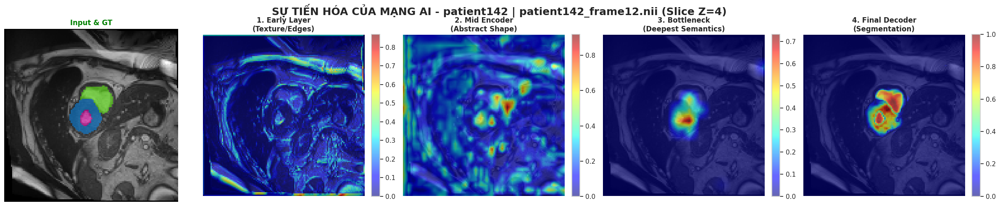

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


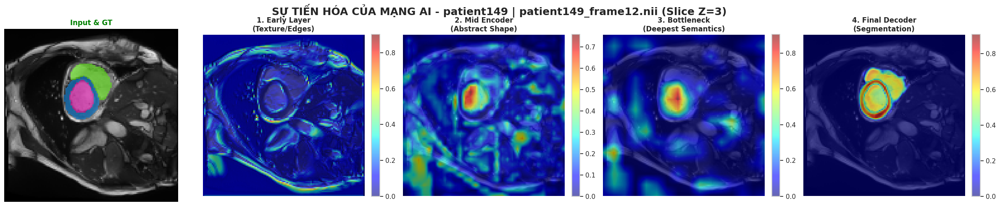

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


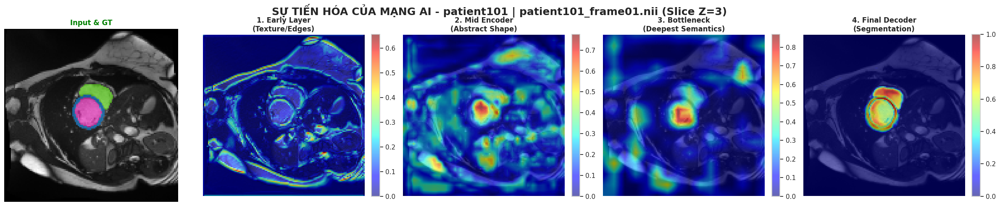

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
from scipy.ndimage import zoom
from pathlib import Path

def visualize_layer_evolution(model, items, device="cuda", sample_idx=None):
    """
    Trực quan hóa sự tiến hóa của vùng chú ý (Attention) qua các tầng mạng.
    (Phiên bản đã tối ưu và đồng bộ bộ hook)
    """
    print("🚀 Đang khởi tạo Layer-wise Visualization...")
    model.eval()
    
    # --- ĐỊNH NGHĨA CÁC TẦNG CẦN SOI TỪ CẠN ĐẾN SÂU ---
    target_layers = {
        "1. Early Layer\n(Texture/Edges)": model.convInit,
        "2. Mid Encoder\n(Abstract Shape)": model.down_layers[2], 
        "3. Bottleneck\n(Deepest Semantics)": model.down_layers[3],
        "4. Final Decoder\n(Segmentation)": model.up_layers[-1] # Sửa thành lớp upsample cuối
    }

    # Chọn mẫu
    if sample_idx is None:
        sample_idx = random.randint(0, len(items)-1)
    
    # Bật augment=False để giữ ảnh gốc không bị lật lung tung
    ds = VolumeDataset([items[sample_idx]], augment=False)
    data = ds[0]
    img = data['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = data['label'].numpy()
    
    # Lấy thông tin ID bệnh nhân để in tiêu đề
    p_name = Path(items[sample_idx][0]).parent.name
    f_name = Path(items[sample_idx][0]).name
    
    # Lấy ảnh gốc để hiển thị
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tìm slice có diện tích tim lớn nhất
    sums = np.sum(label > 0, axis=(0, 1))
    slice_idx = np.argmax(sums) if np.max(sums) > 0 else (label.shape[2] // 2)

    # --- KHỞI TẠO BẢNG ĐIỀU KHIỂN (PLOT) ---
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(24, 5))
    fig.suptitle(f"SỰ TIẾN HÓA CỦA MẠNG AI - {p_name} | {f_name} (Slice Z={slice_idx})", fontsize=18, fontweight='bold')
    
    # Cột 1: Ảnh gốc + Ground Truth (Mặt nạ đáp án)
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    axes[0].set_title(f"Input & GT", fontweight='bold', color='green')
    axes[0].axis('off')

    # --- DUYỆT QUA TỪNG TẦNG ---
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        print(f"  >> Đang phân tích tầng: {layer_name.replace(chr(10), ' ')}...")
        
        # Khởi tạo GradCAM cho tầng hiện tại
        cam_extractor = GradCAM3D(model, layer_module)
        
        # Tính Heatmap tổng hợp cho cả quả tim (LV + MYO + RV)
        combined_heatmap = np.zeros_like(label, dtype=np.float32)
        
        for c in [1, 2, 3]: 
            try:
                # Generate CAM từ class GradCAM3D
                h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                
                # Tính tỷ lệ và zoom lên kích thước gốc
                zoom_factor = (
                    label.shape[0] / h_small.shape[0],
                    label.shape[1] / h_small.shape[1],
                    label.shape[2] / h_small.shape[2]
                )
                h_large = zoom(h_small, zoom_factor, order=1)
                
                # Gộp dồn điểm nóng
                combined_heatmap = np.maximum(combined_heatmap, h_large)
            except Exception as e:
                continue
        
        # Giải phóng Hook ngay lập tức để tiết kiệm VRAM
        cam_extractor.remove_hooks()

        # Render hình ảnh
        ax = axes[i + 1]
        ax.imshow(img_np[:, :, slice_idx], cmap='gray')
        
        # Normalize để màu sắc hiển thị đồng đều giữa các tầng
        if combined_heatmap.max() > 0:
            combined_heatmap /= combined_heatmap.max()
            
        im = ax.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.6)
        ax.set_title(layer_name, fontweight='bold')
        ax.axis('off')
        
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- CHẠY THỬ 3 MẪU ---
print("\n" + "="*50)
for _ in range(3):
    visualize_layer_evolution(model, te_items, device=DEVICE)

🚀 Đang chọn ngẫu nhiên 3 bệnh nhân để nội soi 8 tầng mạng...

>> Tiến hành phân tích Ca số #1...


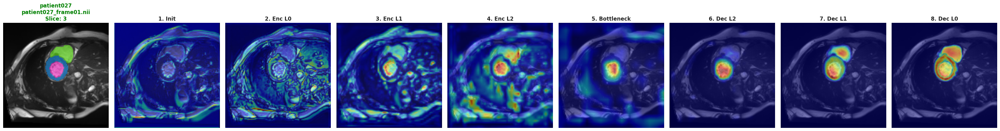


>> Tiến hành phân tích Ca số #2...


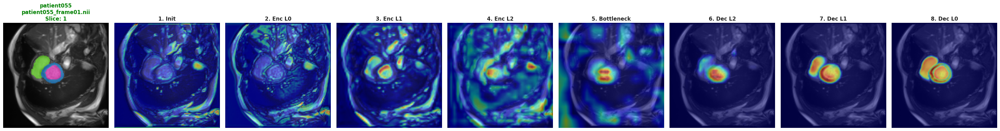


>> Tiến hành phân tích Ca số #3...


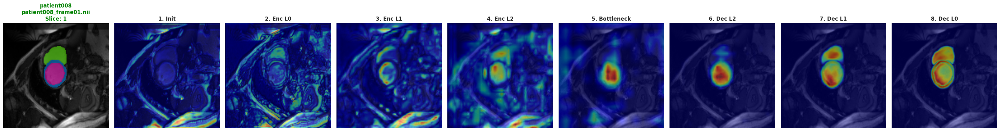


✅ Hoàn tất! Quá trình nội soi đã kết thúc.


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import random
import os
from scipy.ndimage import zoom
from pathlib import Path

# ==============================================================================
# 1. CLASS GRAD-CAM (Giữ nguyên - Rất ổn định)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        if self.gradients is None or self.activations is None: return None
            
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

    def remove_hooks(self):
        for h in self.handles: h.remove()

# ==============================================================================
# 2. HÀM VẼ 1 BỆNH NHÂN (Đã Fix lỗi lấy tên File & Augment)
# ==============================================================================
def visualize_single_patient(model, item, device, patient_idx):
    # Định nghĩa các tầng từ ngoài vào trong, rồi từ trong ra ngoài
    target_layers = {
        "1. Init":         model.convInit,
        "2. Enc L0":       model.down_layers[0],
        "3. Enc L1":       model.down_layers[1],
        "4. Enc L2":       model.down_layers[2],
        "5. Bottleneck":   model.down_layers[3],
        "6. Dec L2":       model.up_layers[0],
        "7. Dec L1":       model.up_layers[1],
        "8. Dec L0":       model.up_layers[2]
    }

    # Prepare Data (Tắt augment để ảnh nằm im)
    ds = VolumeDataset([item], augment=False)
    img = ds[0]['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = ds[0]['label'].numpy()
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tìm slice đẹp nhất (Chứa nhiều thông tin tim nhất)
    sums = np.sum(label > 0, axis=(0, 1))
    slice_idx = np.argmax(sums) if np.max(sums) > 0 else img_np.shape[2] // 2

    # Setup Plot (1 hàng, 9 cột) - Kéo dài khung hình để không bị ép
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(32, 4))
    
    # Cột 1: Input + GT
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    
    # 🌟 SỬA TẠI ĐÂY: Dùng Path để bóc tách chính xác tên Bệnh nhân và Frame
    try:
        p_name = Path(item[0]).parent.name
        f_name = Path(item[0]).name
        title_text = f"{p_name}\n{f_name}\nSlice: {slice_idx}"
    except:
        title_text = f"Patient {patient_idx}\nSlice {slice_idx}"

    axes[0].set_title(title_text, fontweight='bold', color='green', fontsize=12)
    axes[0].axis('off')

    # Vẽ các tầng
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        try:
            cam_extractor = GradCAM3D(model, layer_module)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Quét 3 lớp tim (RV, MYO, LV)
            for c in [1, 2, 3]: 
                try:
                    h = cam_extractor.generate_heatmap(img, class_idx=c)
                    if h is None: continue
                    z_factor = (label.shape[0]/h.shape[0], label.shape[1]/h.shape[1], label.shape[2]/h.shape[2])
                    h_large = zoom(h, z_factor, order=1)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except: continue
            
            cam_extractor.remove_hooks()

            ax = axes[i + 1]
            ax.imshow(img_np[:, :, slice_idx], cmap='gray')
            if combined_heatmap.max() > 0: 
                combined_heatmap /= combined_heatmap.max()
            ax.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            ax.set_title(layer_name, fontweight='bold', fontsize=12)
            ax.axis('off')
        except: continue

    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. HÀM CHẠY 3 BỆNH NHÂN (Wrapper)
# ==============================================================================
def run_3_patients_demo(model, items, device="cuda"):
    print("🚀 Đang chọn ngẫu nhiên 3 bệnh nhân để nội soi 8 tầng mạng...")
    model.eval()
    
    # Lấy 3 chỉ số ngẫu nhiên không trùng nhau
    count = min(3, len(items))
    indices = random.sample(range(len(items)), count)
    
    for i, idx in enumerate(indices):
        print(f"\n>> Tiến hành phân tích Ca số #{i+1}...")
        visualize_single_patient(model, items[idx], device, idx)
    
    print("\n✅ Hoàn tất! Quá trình nội soi đã kết thúc.")

# --- THỰC THI ---
run_3_patients_demo(model, te_items, device=DEVICE)

🚀 Đang tính toán Uncertainty Map (MC Dropout) cho 3 mẫu...
✅ Đã load weights từ: segresnet3d_acdc_results/best_model.pth


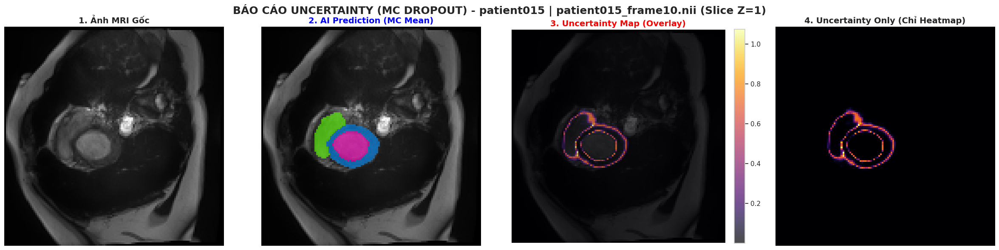

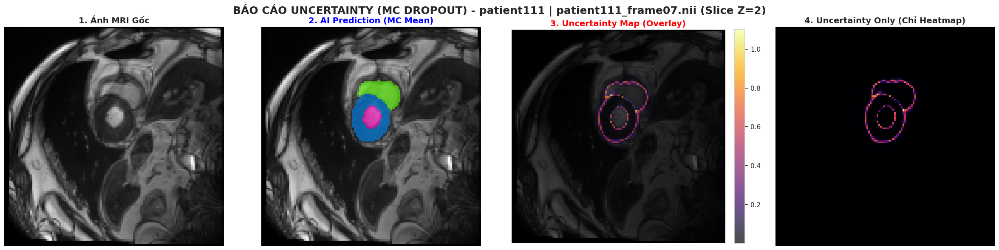

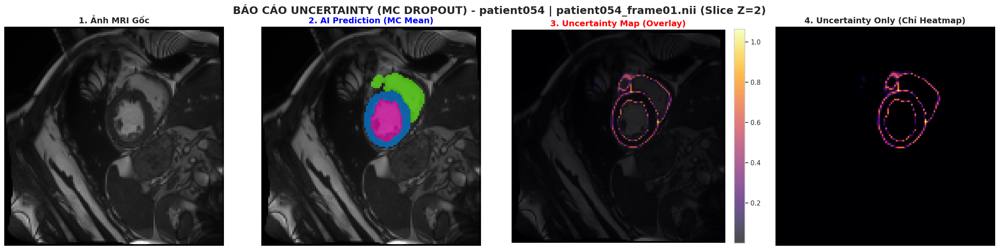

In [8]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random
from pathlib import Path

# ==============================================================================
# 1. HÀM TÍNH ĐỘ BẤT ĐỊNH (UNCERTAINTY BẰNG MC DROPOUT)
# ==============================================================================
def compute_uncertainty_mc_dropout(model, input_tensor, T=15):
    """
    Thực hiện Monte Carlo Dropout để ước lượng độ bất định.
    Input:
        - model: Mô hình SegResNet
        - input_tensor: Ảnh đầu vào (1, 1, D, H, W)
        - T: Số lần chạy lặp lại (sampling). T càng cao bản đồ càng mượt (thường 15-20).
    """
    # [QUAN TRỌNG] Kích hoạt chế độ Train để bật Dropout layer
    model.train() 
    
    outputs = []
    with torch.no_grad():
        for _ in range(T):
            # Forward pass
            logits = model(input_tensor)
            # Chuyển về xác suất (Probability)
            probs = torch.softmax(logits, dim=1)
            outputs.append(probs) # List các tensor (1, C, D, H, W)
            
    # Xếp chồng kết quả: (T, 1, C, D, H, W)
    outputs = torch.stack(outputs)
    
    # 1. Tính Mean Probability (Dự đoán trung bình của T lần chạy)
    mean_prob = torch.mean(outputs, dim=0) # (1, C, D, H, W)
    
    # 2. Tính Predictive Entropy (Độ bất định)
    # Công thức Shannon Entropy: H = - sum( p * log(p) )
    epsilon = 1e-6 # Tránh lỗi log(0)
    uncertainty_map = -torch.sum(mean_prob * torch.log(mean_prob + epsilon), dim=1)
    
    # [QUAN TRỌNG] Trả model về chế độ Eval để không ảnh hưởng các đoạn code khác
    model.eval()
    
    return mean_prob, uncertainty_map

# ==============================================================================
# 2. VISUALIZATION DASHBOARD (UNCERTAINTY XAI)
# ==============================================================================
def visualize_uncertainty_xai(model, items, device="cuda", num_samples=3):
    print(f"🚀 Đang tính toán Uncertainty Map (MC Dropout) cho {num_samples} mẫu...")
    
    # Load lại weight tốt nhất nếu cần thiết
    chk_path = SAVE_DIR / "best_model.pth"
    if not chk_path.exists():
        chk_path = Path("/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth")
    if chk_path.exists():
        model.load_state_dict(torch.load(chk_path, map_location=device))
        print(f"✅ Đã load weights từ: {chk_path}")
    
    # Chọn mẫu ngẫu nhiên từ tập Test
    indices = random.sample(range(len(items)), min(len(items), num_samples))

    for idx in indices:
        try:
            # Load data không augment
            ds = VolumeDataset([items[idx]], augment=False)
            sample = ds[0]
            
            img = sample["image"].unsqueeze(0).to(device) # (1, 1, D, H, W)
            label = sample["label"].numpy()
            
            # --- TÍNH UNCERTAINTY ---
            # Chạy MC Dropout 15 lần
            mean_prob, unc_map = compute_uncertainty_mc_dropout(model, img, T=15)
            
            # Lấy nhãn dự đoán từ mean_prob
            pred_mask = torch.argmax(mean_prob, dim=1).detach().cpu().numpy()[0]
            unc_map_np = unc_map.detach().cpu().numpy()[0] # (D, H, W)
            
            # --- TÌM SLICE ĐẸP NHẤT ---
            img_np = img.detach().cpu().numpy()[0, 0]
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else label.shape[2] // 2
            
            # Bóc tách tên Bệnh nhân & File
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name
            
            # --- VẼ HÌNH ---
            fig, axes = plt.subplots(1, 4, figsize=(24, 6))
            plt.suptitle(f"BÁO CÁO UNCERTAINTY (MC DROPOUT) - {p_name} | {f_name} (Slice Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: MRI Gốc
            axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
            axes[0].set_title("1. Ảnh MRI Gốc", fontsize=14, fontweight='bold')
            axes[0].axis('off')

            # Ô 2: Prediction (Mean)
            axes[1].imshow(img_np[:, :, slice_idx], cmap='gray')
            masked_pred = np.ma.masked_where(pred_mask[:, :, slice_idx] == 0, pred_mask[:, :, slice_idx])
            axes[1].imshow(masked_pred, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            axes[1].set_title("2. AI Prediction (MC Mean)", fontsize=14, fontweight='bold', color='blue')
            axes[1].axis('off')

            # Ô 3: Uncertainty Map (Entropy Heatmap Overlay) 
            axes[2].imshow(img_np[:, :, slice_idx], cmap='gray')
            im_unc = axes[2].imshow(unc_map_np[:, :, slice_idx], cmap='inferno', alpha=0.7) 
            axes[2].set_title("3. Uncertainty Map (Overlay)", fontsize=14, fontweight='bold', color='red')
            axes[2].axis('off')
            plt.colorbar(im_unc, ax=axes[2], fraction=0.046, pad=0.04)

            # Ô 4: Uncertainty Only (Zoom chi tiết)
            axes[3].imshow(unc_map_np[:, :, slice_idx], cmap='inferno')
            axes[3].set_title("4. Uncertainty Only (Chỉ Heatmap)", fontsize=14, fontweight='bold')
            axes[3].axis('off')

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

# --- GỌI HÀM ---
# Cứ truyền thẳng te_items vào đây, hàm tự động xử lý
visualize_uncertainty_xai(model, te_items, device=DEVICE, num_samples=3)

# attention unet

In [2]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from medpy.metric.binary import dc, jc, hd95
# [SỬA IMPORT] Load AttentionUnet từ MONAI
from monai.networks.nets import AttentionUnet

# ---------------- 0. CONFIGURATION ----------------
BASE_DIR = Path("/kaggle/input/datasets/samdazel/automated-cardiac-diagnosis-challenge-miccai17/database")
TRAIN_DIR = BASE_DIR / "training"
TEST_DIR = BASE_DIR / "testing"

SAVE_DIR = Path("./attention_unet3d_acdc_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 16)
NUM_CLASSES = 4
BATCH_SIZE = 2
EPOCHS = 100
LR = 1e-4
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, NUM_CLASSES).permute(0,4,1,2,3).float()
        dims = (0,2,3,4)
        inter = torch.sum(pred[:,1:] * target_oh[:,1:], dims)
        union = torch.sum(pred[:,1:] + target_oh[:,1:], dims)
        return 1 - ((2*inter + self.smooth) / (union + self.smooth)).mean()

# ---------------- 2. DATASET ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt  = nib.load(gt_p).get_fdata().astype(np.int64)

        zoom = (
            TARGET_SIZE[0] / img.shape[0],
            TARGET_SIZE[1] / img.shape[1],
            TARGET_SIZE[2] / img.shape[2]
        )
        img = ndi.zoom(img, zoom, order=1)
        gt  = ndi.zoom(gt,  zoom, order=0)

        if self.augment:
            if random.random() > 0.5:
                ax = random.randint(0,2)
                img = np.flip(img, ax).copy()
                gt  = np.flip(gt, ax).copy()

        img = (img - img.mean()) / (img.std() + 1e-6)

        return {
            "image": torch.from_numpy(img[None]).float(),
            "label": torch.from_numpy(gt).long()
        }

# ---------------- 3. METRICS ----------------
def get_metrics(p, g):
    res = {}
    for cl, name in zip([1,2,3], ['RV','MYO','LV']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0:
            res[name] = (0.0, 0.0, 50.0)
            continue
        res[name] = (
            dc(pc, gc),
            jc(pc, gc),
            hd95(pc, gc) if pc.sum()>0 else 50.0
        )
    return res

# ---------------- 4. GỘP DATA & CHIA TẦNG ----------------
patient_data = {}
for folder_dir in [TRAIN_DIR, TEST_DIR]:
    if not folder_dir.exists(): continue
    for p in sorted(folder_dir.iterdir()):
        if not p.is_dir() or not p.name.startswith("patient"): continue
        
        pid = p.name
        info_file = p / "Info.cfg"
        disease = "NOR" 
        
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if line.startswith("Group:"): 
                        disease = line.split(":")[1].strip()
        
        gt_nodes = list(p.glob("*_frame*_gt.nii*"))
        scans = []
        for gt_node in gt_nodes:
            img_node = gt_node.parent / gt_node.name.replace("_gt", "")
            if img_node.exists():
                scans.append((str(img_node), str(gt_node)))
                
        if scans:
            patient_data[pid] = {'disease': disease, 'scans': scans}

p_ids = list(patient_data.keys())
p_labels = [patient_data[pid]['disease'] for pid in p_ids]

train_ids, temp_ids, train_labels, temp_labels = train_test_split(
    p_ids, p_labels, test_size=70, random_state=SEED, stratify=p_labels
)
val_ids, test_ids, val_labels, test_labels = train_test_split(
    temp_ids, temp_labels, test_size=50, random_state=SEED, stratify=temp_labels
)

tr_items = [scan for pid in train_ids for scan in patient_data[pid]['scans']]
va_items = [scan for pid in val_ids for scan in patient_data[pid]['scans']]
te_items = [scan for pid in test_ids for scan in patient_data[pid]['scans']]

print(f"✅ Đã chia tầng xong: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
print(f"Tỉ lệ bệnh tập Test: {pd.Series(test_labels).value_counts().to_dict()}")

loaders = {
    "train": DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    "val":   DataLoader(VolumeDataset(va_items), 1)
}

print("-"*170)

# ---------------- 5. MODEL ----------------
# [SỬA TẠI ĐÂY] Khởi tạo mô hình Attention U-Net
model = AttentionUnet(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    dropout=0.2
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, "max", patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler("cuda")

best_dice = 0.0

# ---------------- 6. CSV LOG ----------------
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, "w", newline="") as f:
    csv.writer(f).writerow([
        "epoch","tr_loss","va_loss","tr_dice",
        "va_dice","va_iou","va_hd95",
        "rv_d","myo_d","lv_d","time" 
    ])

# ---------------- 7. TRAINING LOOP ----------------
for ep in range(1, EPOCHS+1):
    t0 = time.time()
    model.train()
    tr_l, tr_d = [], []

    for b in tqdm(loaders["train"], desc=f"Epoch {ep:02d}", leave=False):
        img = b["image"].to(DEVICE)
        lab = b["label"].to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            out = model(img)
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_l.append(loss.item())
        tr_d.append(dc((out.argmax(1)>0).cpu().numpy(), (lab>0).cpu().numpy()))

    # ---------------- VALIDATION ----------------
    model.eval()
    va_l, acc = [], {"RV":[], "MYO":[], "LV":[]}

    with torch.no_grad():
        for b in loaders["val"]:
            img = b["image"].to(DEVICE)
            lab = b["label"].to(DEVICE)

            with torch.amp.autocast("cuda"):
                out = model(img)
                loss = ce_criterion(out, lab) + dice_criterion(out, lab)
            
            va_l.append(loss.item())

            p = out.argmax(1).cpu().numpy()[0]
            g = lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for k in acc: acc[k].append(m[k])

    tr_loss = np.mean(tr_l)
    va_loss = np.mean(va_l)
    tr_dice = np.mean(tr_d)

    stats = {k: np.mean(acc[k],0) for k in acc}
    va_dice = np.mean([stats[k][0] for k in stats])
    va_iou  = np.mean([stats[k][1] for k in stats])
    va_hd95 = np.mean([stats[k][2] for k in stats])

    scheduler.step(va_dice)
    t_total = time.time() - t0

    print(
        f"Ep {ep:02d} | {t_total:5.1f}s | "
        f"Tr.Loss {tr_loss:.4f} | Va.Loss {va_loss:.4f} | "
        f"Tr.Dice {tr_dice:.4f} | Va.Dice {va_dice:.4f} | "
        f"IoU {va_iou:.4f} | HD95 {va_hd95:.2f}"
    )

    with open(CSV_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            ep, tr_loss, va_loss, tr_dice,
            va_dice, va_iou, va_hd95,
            stats["RV"][0], stats["MYO"][0], stats["LV"][0], t_total
        ])

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), SAVE_DIR/"best_model.pth")
        print(f"New Best Model Saved | Dice {best_dice:.4f}")

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
2026-05-29 15:31:56.750771: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780068716.971836      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780068717.035574      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780068717.565223      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780068717.565267      57 computation_placer.cc:1

✅ Đã chia tầng xong: Train 80 BN | Val 20 BN | Test 50 BN
Tỉ lệ bệnh tập Test: {'MINF': 10, 'DCM': 10, 'NOR': 10, 'RV': 10, 'HCM': 10}
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Ep 01 |  35.9s | Tr.Loss 2.1767 | Va.Loss 2.0349 | Tr.Dice 0.1537 | Va.Dice 0.2331 | IoU 0.1641 | HD95 45.55
New Best Model Saved | Dice 0.2331


Ep 02 |  21.2s | Tr.Loss 2.0310 | Va.Loss 1.9907 | Tr.Dice 0.2251 | Va.Dice 0.2459 | IoU 0.1636 | HD95 42.41
New Best Model Saved | Dice 0.2459


Ep 03 |  21.2s | Tr.Loss 1.9737 | Va.Loss 1.9397 | Tr.Dice 0.2654 | Va.Dice 0.3104 | IoU 0.2184 | HD95 36.41
New Best Model Saved | Dice 0.3104


Ep 04 |  20.8s | Tr.Loss 1.9250 | Va.Loss 1.8898 | Tr.Dice 0.2963 | Va.Dice 0.3550 | IoU 0.2516 | HD95 40.85
New Best Model Saved | Dice 0.3550


... (92 outputs left out)

Ep 97 |  19.3s | Tr.Loss 0.2427 | Va.Loss 0.2244 | Tr.Dice 0.9055 | Va.Dice 0.8308 | IoU 0.7194 | HD95 1.68


Ep 98 |  19.3s | Tr.Loss 0.2385 | Va.Loss 0.2188 | Tr.Dice 0.9076 | Va.Dice 0.8338 | IoU 0.7231 | HD95 1.71
New Best Model Saved | Dice 0.8338


Ep 99 |  19.2s | Tr.Loss 0.2367 | Va.Loss 0.2173 | Tr.Dice 0.9076 | Va.Dice 0.8349 | IoU 0.7250 | HD95 1.71
New Best Model Saved | Dice 0.8349


Ep 100 |  19.3s | Tr.Loss 0.2322 | Va.Loss 0.2244 | Tr.Dice 0.9114 | Va.Dice 0.8299 | IoU 0.7182 | HD95 1.72


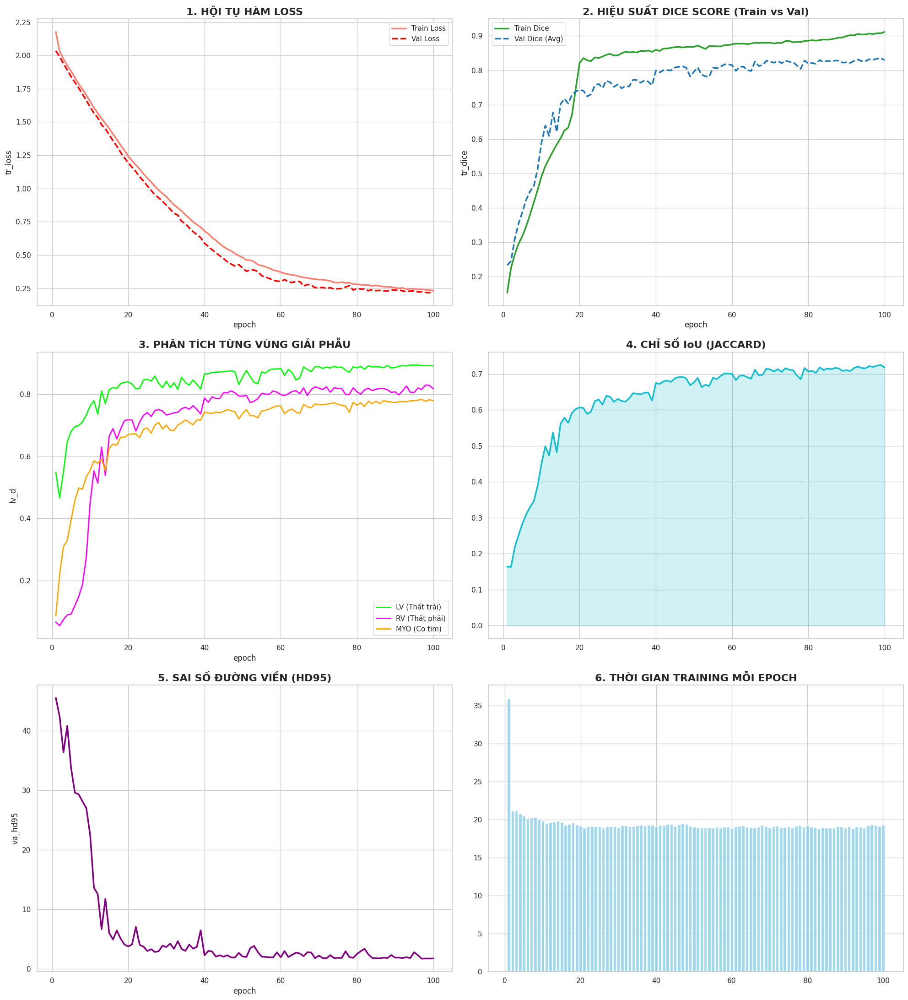


         BÁO CÁO KẾT QUẢ MÔ HÌNH ATTENTION U-NET 3D         
🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: 99
  > Dice Score (Avg)          :     0.8349
  > IoU (Jaccard)             :     0.7250
  > HD95                      :    1.71 mm
  > Dice - LV                 :     0.8931
  > Dice - RV                 :     0.8291
  > Dice - MYO                :     0.7825


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đảm bảo đường dẫn trỏ đúng vào thư mục của Attention U-Net
SAVE_DIR = Path("./attention_unet3d_acdc_results")
CSV_PATH = SAVE_DIR / "training_log.csv"

# ================= 8. DASHBOARD & REPORT =================
def plot_dashboard_matched(log_path):
    if not log_path.exists():
        print(f"❌ Lỗi: Không tìm thấy file log tại {log_path}")
        return

    df = pd.read_csv(log_path)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.2)

    # --- BIỂU ĐỒ 1: LOSS ---
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='tr_loss', label='Train Loss', color='salmon', linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='va_loss', label='Val Loss', color='red', linewidth=2.5, linestyle='--')
    axes[0, 0].set_title('1. HỘI TỤ HÀM LOSS', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 2: DICE TỔNG QUÁT ---
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='tr_dice', label='Train Dice', color='#2ca02c', linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='va_dice', label='Val Dice (Avg)', color='#1f77b4', linewidth=2.5, linestyle='--')
    axes[0, 1].set_title('2. HIỆU SUẤT DICE SCORE (Train vs Val)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 3: DICE CHI TIẾT ---
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='lv_d', label='LV (Thất trái)', color='lime', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='rv_d', label='RV (Thất phải)', color='magenta', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='myo_d', label='MYO (Cơ tim)', color='orange', linewidth=2)
    axes[1, 0].set_title('3. PHÂN TÍCH TỪNG VÙNG GIẢI PHẪU', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 4: IoU ---
    axes[1, 1].fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
    axes[1, 1].plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Mean IoU')
    axes[1, 1].set_title('4. CHỈ SỐ IoU (JACCARD)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 5: HD95 ---
    sns.lineplot(ax=axes[2, 0], data=df, x='epoch', y='va_hd95', color='purple', linewidth=2.5)
    axes[2, 0].set_title('5. SAI SỐ ĐƯỜNG VIỀN (HD95)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 6: THỜI GIAN ---
    axes[2, 1].bar(df['epoch'], df['time'], color='skyblue', alpha=0.8)
    axes[2, 1].set_title('6. THỜI GIAN TRAINING MỖI EPOCH', fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.savefig(SAVE_DIR / "final_dashboard.png", dpi=300)
    plt.show()

def print_report_matched(log_path):
    if not log_path.exists(): return
    df = pd.read_csv(log_path)
    best_row = df.iloc[df['va_dice'].idxmax()]
    
    print("\n" + "="*60)
    print(f"{'BÁO CÁO KẾT QUẢ MÔ HÌNH ATTENTION U-NET 3D':^60}")
    print("="*60)
    print(f"🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: {int(best_row['epoch'])}")
    for l, v in [["Dice Score (Avg)", f"{best_row['va_dice']:.4f}"], ["IoU (Jaccard)", f"{best_row['va_iou']:.4f}"], 
                 ["HD95", f"{best_row['va_hd95']:.2f} mm"], ["Dice - LV", f"{best_row['lv_d']:.4f}"], 
                 ["Dice - RV", f"{best_row['rv_d']:.4f}"], ["Dice - MYO", f"{best_row['myo_d']:.4f}"]]:
        print(f"  > {l:<25} : {v:>10}")
    print("="*60)

# Thực thi
plot_dashboard_matched(CSV_PATH)
print_report_matched(CSV_PATH)

In [3]:
# ==============================================================================
# 🏆 ĐÁNH GIÁ TRÊN TẬP TEST (INFERENCE)
# ==============================================================================
print("\n" + "=" * 80)
print("🏆 BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST (50 BỆNH NHÂN)")
print("=" * 80)

# 1. Tải trọng số mô hình tốt nhất
BEST_MODEL_PATH = SAVE_DIR / "best_model.pth"
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file {BEST_MODEL_PATH}. Vui lòng kiểm tra lại quá trình train.")

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()
print(f"[*] Đã tải thành công mô hình từ: {BEST_MODEL_PATH}")

# 2. Tạo DataLoader cho tập Test
test_dataset = VolumeDataset(te_items, augment=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# 3. Khởi tạo biến lưu trữ kết quả
test_metrics = {"RV": [], "MYO": [], "LV": []}
total_inference_time = 0.0

# 4. Vòng lặp Inference
with torch.no_grad():
    for i, batch in enumerate(tqdm(test_loader, desc="Đang xử lý tập Test")):
        img = batch["image"].to(DEVICE)
        gt = batch["label"].to(DEVICE)
        
        # Đo thời gian dự đoán (không tính thời gian load data)
        start_time = time.time()
        with torch.amp.autocast("cuda"):
            out = model(img)
            pred = out.argmax(dim=1) # Lấy class có xác suất cao nhất
        total_inference_time += (time.time() - start_time)
        
        # Chuyển tensor về numpy array để tính toán với medpy
        p_np = pred.cpu().numpy()[0]
        g_np = gt.cpu().numpy()[0]
        
        # Sử dụng hàm get_metrics đã định nghĩa ở trên
        m = get_metrics(p_np, g_np)
        
        # Lưu kết quả
        for k in test_metrics:
            test_metrics[k].append(m[k])

# 5. Tổng hợp và in kết quả
print("\n📊 KẾT QUẢ ĐÁNH GIÁ TỔNG HỢP (TẬP TEST):")
print("-" * 60)
print(f"{'Cấu trúc':<10} | {'Dice':<10} | {'IoU':<10} | {'HD95 (mm)':<10}")
print("-" * 60)

final_stats = {k: np.mean(test_metrics[k], axis=0) for k in test_metrics}

# In chi tiết từng class
for cl_name in ["RV", "MYO", "LV"]:
    dice_val = final_stats[cl_name][0]
    iou_val = final_stats[cl_name][1]
    hd95_val = final_stats[cl_name][2]
    print(f"{cl_name:<10} | {dice_val:.4f}   | {iou_val:.4f}   | {hd95_val:.4f}")

print("-" * 60)
# In Trung bình toàn bộ
mean_dice = np.mean([final_stats[k][0] for k in final_stats])
mean_iou  = np.mean([final_stats[k][1] for k in final_stats])
mean_hd95 = np.mean([final_stats[k][2] for k in final_stats])

print(f"{'Trung bình':<10} | {mean_dice:.4f}   | {mean_iou:.4f}   | {mean_hd95:.4f}")
print("=" * 60)

avg_time_per_scan = (total_inference_time / len(test_loader)) * 1000
print(f"⏱️ Thời gian dự đoán trung bình: {avg_time_per_scan:.2f} ms / scan 3D")


🏆 BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST (50 BỆNH NHÂN)
[*] Đã tải thành công mô hình từ: attention_unet3d_acdc_results/best_model.pth


Đang xử lý tập Test: 100%|██████████| 100/100 [00:27<00:00,  3.60it/s]


📊 KẾT QUẢ ĐÁNH GIÁ TỔNG HỢP (TẬP TEST):
------------------------------------------------------------
Cấu trúc   | Dice       | IoU        | HD95 (mm) 
------------------------------------------------------------
RV         | 0.8238   | 0.7122   | 2.0395
MYO        | 0.7937   | 0.6655   | 1.7328
LV         | 0.8885   | 0.8077   | 1.6887
------------------------------------------------------------
Trung bình | 0.8353   | 0.7285   | 1.8203
⏱️ Thời gian dự đoán trung bình: 8.75 ms / scan 3D


🚀 Đang khởi tạo XAI Dashboard cho 3 mẫu...


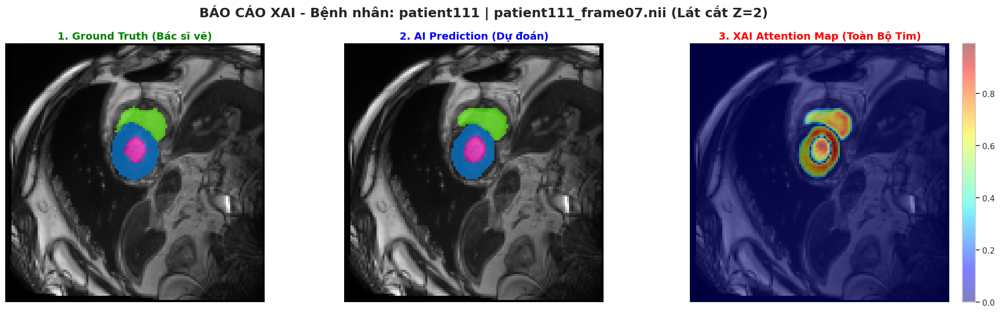

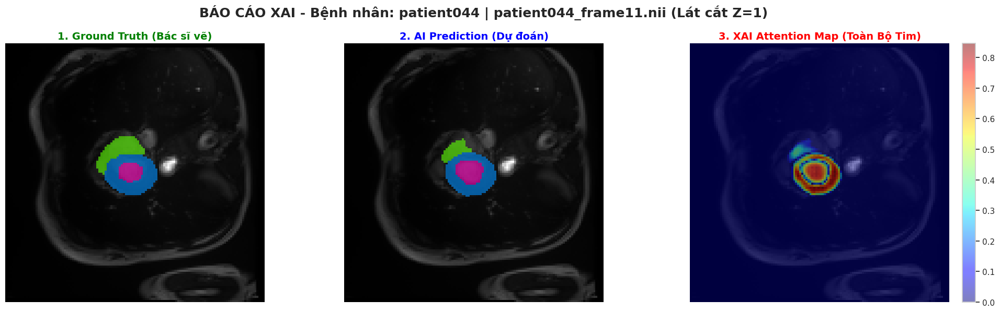

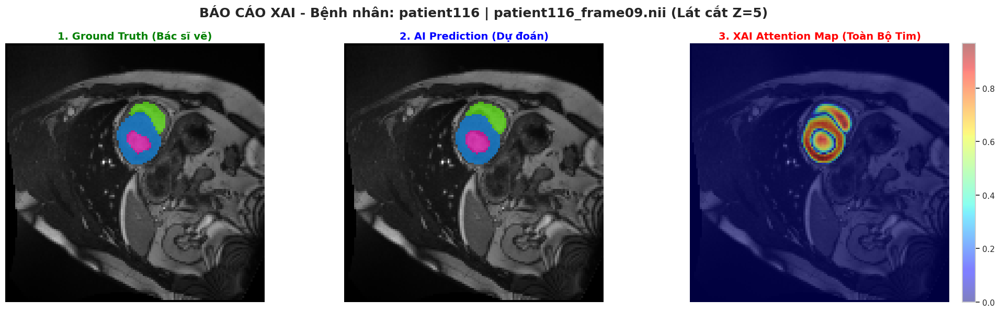

✅ Hoàn tất quá trình trích xuất XAI Dashboard!


In [14]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random

# ==============================================================================
# 1. CLASS GRAD-CAM 3D (CORE ENGINE)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        
        # Đăng ký hook để "nghe lén" dữ liệu khi chạy qua layer này
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        """Quan trọng: Gỡ bỏ hook để giải phóng bộ nhớ"""
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx):
        # Reset gradient cũ
        self.model.zero_grad()
        
        # 1. Forward Pass (Chạy lại forward để tạo đồ thị tính toán mới)
        output = self.model(input_tensor)
        
        # 2. Backward Pass: Chỉ quan tâm đến Class đích (class_idx)
        score = output[0, class_idx].sum()
        # Bỏ retain_graph=True vì ta đã forward lại từ đầu, tránh lỗi tràn bộ nhớ GPU
        score.backward() 

        # 3. Tạo CAM
        # Global Average Pooling trên gradients (trọng số alpha)
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        
        # Nhân trọng số với activation map
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        
        # ReLU: Chỉ lấy các đặc trưng có ảnh hưởng dương tính (tích cực)
        cam = F.relu(cam).detach().cpu().numpy()
        
        # Chuẩn hóa về [0, 1] để hiển thị
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        
        return cam

# ==============================================================================
# 2. DASHBOARD VISUALIZATION FUNCTION
# ==============================================================================
def visualize_xai_prediction_dashboard(model, items, device="cuda", num_samples=6):
    """
    Hàm tổng hợp: Chạy dự đoán + Tính Grad-CAM + Vẽ Dashboard 3 cột
    """
    print(f"🚀 Đang khởi tạo XAI Dashboard cho {num_samples} mẫu...")
    
    model.eval()
    
    # --- A. TỰ ĐỘNG TÌM TARGET LAYER ---
    # Lấy layer Conv3D cuối cùng của SegResNet làm Target Layer
    conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
    if not conv_layers:
        print("❌ Lỗi: Không tìm thấy layer Conv3D nào trong model!")
        return
    target_layer = conv_layers[-1]
    
    # Khởi tạo công cụ Grad-CAM
    cam_extractor = GradCAM3D(model, target_layer)
    
    # Load dataset test (Tắt augment để giữ nguyên gốc ảnh)
    dataset = VolumeDataset(items, augment=False) 
    
    # Chọn mẫu ngẫu nhiên
    sample_indices = random.sample(range(len(items)), min(len(items), num_samples))

    # --- B. VÒNG LẶP XỬ LÝ TỪNG MẪU ---
    for idx in sample_indices:
        try:
            data = dataset[idx]
            
            # Input cần require grad để tính ngược
            img = data['image'].unsqueeze(0).to(device)
            img.requires_grad = True 
            
            label = data['label'].numpy() # Shape: (128, 128, 16)
            
            # 1. Chạy dự đoán (Prediction)
            with torch.no_grad(): # Tắt grad khúc này để tiết kiệm VRAM
                out = model(img)
                pred = torch.argmax(out, 1).detach().cpu().numpy()[0]

            # 2. Tính Grad-CAM tổng hợp (Gộp Heatmap của LV, MYO, RV)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Duyệt qua 3 lớp tim: 1(RV), 2(MYO), 3(LV)
            for c in [1, 2, 3]: 
                try:
                    # Tạo heatmap thô (kích thước nhỏ)
                    h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                    
                    # Tính tỷ lệ phóng to để khớp với ảnh gốc
                    zoom_factor = (
                        label.shape[0] / h_small.shape[0],
                        label.shape[1] / h_small.shape[1],
                        label.shape[2] / h_small.shape[2]
                    )
                    
                    # Phóng to heatmap (Zoom)
                    h_large = zoom(h_small, zoom_factor, order=1)
                    
                    # Cộng dồn vào bản đồ nhiệt tổng (Lấy max để giữ điểm nóng nhất)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except Exception as e:
                    continue

            # 3. Chọn lát cắt (Slice) hiển thị
            img_np = img.detach().cpu().numpy()[0, 0]
            
            # Tìm lát cắt có diện tích tim lớn nhất
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else (label.shape[2] // 2)
            
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name

            # --- C. VẼ ĐỒ THỊ ---
            plt.figure(figsize=(20, 6))
            plt.suptitle(f"BÁO CÁO XAI - Bệnh nhân: {p_name} | {f_name} (Lát cắt Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: Ground Truth
            plt.subplot(1, 3, 1)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Masked array để ẩn phần nền (class 0)
            gt_masked = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
            plt.imshow(gt_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("1. Ground Truth (Bác sĩ vẽ)", fontsize=14, color='green', fontweight='bold')
            plt.axis('off')

            # Ô 2: Prediction
            plt.subplot(1, 3, 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            pred_masked = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
            plt.imshow(pred_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("2. AI Prediction (Dự đoán)", fontsize=14, color='blue', fontweight='bold')
            plt.axis('off')

            # Ô 3: XAI Attention Map (Grad-CAM) 
            plt.subplot(1, 3, 3)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Hiển thị Heatmap đè lên ảnh gốc
            im = plt.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            plt.title("3. XAI Attention Map (Toàn Bộ Tim)", fontsize=14, color='red', fontweight='bold')
            plt.axis('off')
            plt.colorbar(im, fraction=0.046, pad=0.04)

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

    # Dọn dẹp Hook cuối cùng
    cam_extractor.remove_hooks()
    print("✅ Hoàn tất quá trình trích xuất XAI Dashboard!")

# ==============================================================================
# 3. RUN (GỌI HÀM)
# ==============================================================================
visualize_xai_prediction_dashboard(model, te_items, device=DEVICE, num_samples=3)


📊 TIẾN HÀNH TRÍCH XUẤT ĐỒ THỊ TIẾN HÓA LỚP ĐẶC TRƯNG
🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix Lệch Tọa Độ)...
[*] Đã khóa mục tiêu 4 tầng Conv 3x3 thành công!
  >> Đang trích xuất bản đồ nhiệt tầng: 1. Early Encoder (Cạnh/Viền)...
  >> Đang trích xuất bản đồ nhiệt tầng: 2. Bottleneck (Đặc trưng sâu)...
  >> Đang trích xuất bản đồ nhiệt tầng: 3. Decoder Giữa (Hội tụ)...
  >> Đang trích xuất bản đồ nhiệt tầng: 4. Final Decoder (Attention bám sát)...


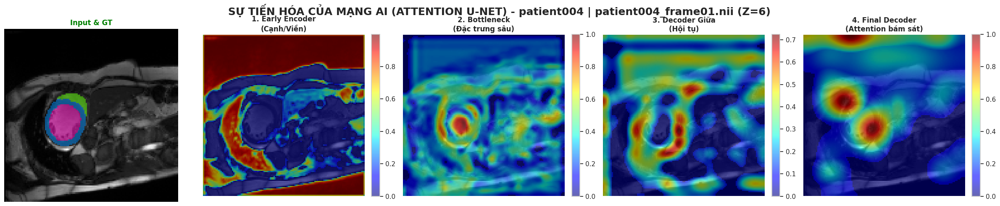

🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix Lệch Tọa Độ)...
[*] Đã khóa mục tiêu 4 tầng Conv 3x3 thành công!
  >> Đang trích xuất bản đồ nhiệt tầng: 1. Early Encoder (Cạnh/Viền)...
  >> Đang trích xuất bản đồ nhiệt tầng: 2. Bottleneck (Đặc trưng sâu)...
  >> Đang trích xuất bản đồ nhiệt tầng: 3. Decoder Giữa (Hội tụ)...
  >> Đang trích xuất bản đồ nhiệt tầng: 4. Final Decoder (Attention bám sát)...


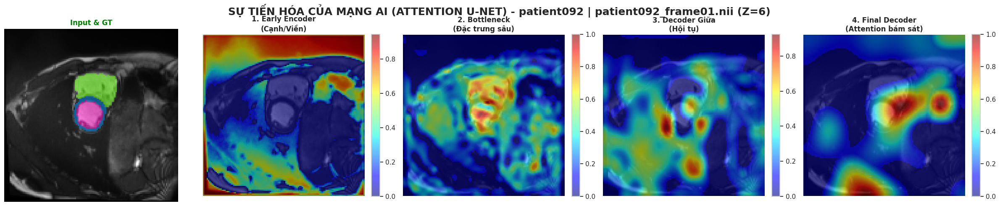

🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix Lệch Tọa Độ)...
[*] Đã khóa mục tiêu 4 tầng Conv 3x3 thành công!
  >> Đang trích xuất bản đồ nhiệt tầng: 1. Early Encoder (Cạnh/Viền)...
  >> Đang trích xuất bản đồ nhiệt tầng: 2. Bottleneck (Đặc trưng sâu)...
  >> Đang trích xuất bản đồ nhiệt tầng: 3. Decoder Giữa (Hội tụ)...
  >> Đang trích xuất bản đồ nhiệt tầng: 4. Final Decoder (Attention bám sát)...


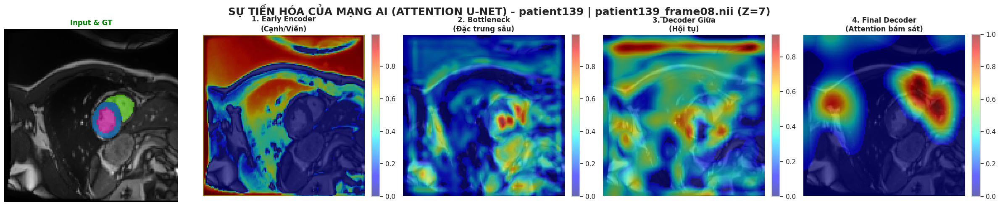

In [17]:
import os, random
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# ==============================================================================
# 📊 LAYER-WISE EVOLUTION (BẢN CHUẨN CHO ATTENTION U-NET)
# ==============================================================================
def visualize_layer_evolution(model, items, device="cuda", sample_idx=None):
    """
    Trực quan hóa sự tiến hóa của vùng chú ý (Attention) qua các tầng mạng Attention U-Net.
    (Đã tích hợp Safe Slice, Per-Class Norm và Tự động quét lớp)
    """
    print("🚀 Đang khởi tạo Layer-wise Evolution cho Attention U-Net...")
    model.eval()
    
    # --- A. TỰ ĐỘNG QUÉT VÀ TÌM CÁC TẦNG QUAN TRỌNG ---
    target_layers = {}
    
    # Thu thập tất cả các module có chứa Convolution (Conv3d)
    conv_modules = [(name, m) for name, m in model.named_modules() if isinstance(m, torch.nn.Conv3d)]
    
    if not conv_modules:
        print("❌ Lỗi: Không tìm thấy lớp Conv3D nào trong mô hình!")
        return

    # 1. Early Encoder (Lớp ngoài cùng, phát hiện cạnh)
    target_layers["1. Early Encoder\n(Cạnh/Viền)"] = conv_modules[0][1]

    # 2. Bottleneck (Lớp sâu nhất, đặc trưng trừu tượng)
    mid_idx = len(conv_modules) // 2
    target_layers["2. Bottleneck\n(Đặc trưng sâu)"] = conv_modules[mid_idx][1]

    # 3. Attention Decoder (Tầng giải mã ở giữa)
    up_modules = [(name, m) for name, m in conv_modules if 'up' in name.lower() or 'att' in name.lower()]
    if len(up_modules) >= 2:
        target_layers["3. Decoder Giữa\n(Hội tụ)"] = up_modules[len(up_modules)//2][1]
        
    # 4. Final Decoder (Lùi lại vài lớp để lấy Feature Map lớn, tránh đốm 1x1)
    target_layer_idx = -4 if len(conv_modules) >= 4 else -1
    target_layers["4. Final Decoder\n(Attention bám sát)"] = conv_modules[target_layer_idx][1]

    print(f"[*] Đã tự động nhận diện {len(target_layers)} tầng đích thành công!")

    # --- B. CHUẨN BỊ DỮ LIỆU & TÌM SLICE AN TOÀN ---
    if sample_idx is None:
        sample_idx = random.randint(0, len(items)-1)
    
    # Bật augment=False để giữ ảnh gốc không bị lật
    ds = VolumeDataset([items[sample_idx]], augment=False)
    data = ds[0]
    img = data['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = data['label'].numpy()
    
    p_name = Path(items[sample_idx][0]).parent.name
    f_name = Path(items[sample_idx][0]).name
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tự động tìm Slice an toàn (Chứa diện tích tim tương đối để tránh rìa)
    sums = np.sum(label > 0, axis=(0, 1))
    valid_slices = np.where(sums > (sums.max() * 0.4))[0] 
    if len(valid_slices) > 0:
        slice_idx = valid_slices[len(valid_slices) // 2] # Tâm quả tim
    else:
        slice_idx = label.shape[2] // 2

    # --- C. VẼ ĐỒ THỊ ---
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(24, 5))
    fig.suptitle(f"SỰ TIẾN HÓA CỦA MẠNG AI (ATTENTION U-NET) - {p_name} | {f_name} (Z={slice_idx})", fontsize=18, fontweight='bold')
    
    # Cột 1: Input & GT
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    axes[0].set_title(f"Input & GT", fontweight='bold', color='green')
    axes[0].axis('off')

    # Các cột tiếp theo: Duyệt qua từng tầng mạng
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        print(f"  >> Đang trích xuất bản đồ nhiệt tầng: {layer_name.replace(chr(10), ' ')}...")
        
        cam_extractor = GradCAM3D(model, layer_module)
        combined_heatmap = np.zeros_like(label, dtype=np.float32)
        
        # Duyệt qua các class: 1 (RV), 2 (MYO), 3 (LV)
        for c in [1, 2, 3]: 
            try:
                h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                
                zoom_factor = (
                    label.shape[0] / h_small.shape[0],
                    label.shape[1] / h_small.shape[1],
                    label.shape[2] / h_small.shape[2]
                )
                h_large = zoom(h_small, zoom_factor, order=1)
                
                # Cân bằng màu: Normalize class riêng biệt trước khi gộp
                if h_large.max() > 0:
                    h_large = h_large / h_large.max()
                    
                combined_heatmap = np.maximum(combined_heatmap, h_large)
            except Exception as e:
                continue
        
        # Giải phóng bộ nhớ Hook
        cam_extractor.remove_hooks()

        # Render hình ảnh
        ax = axes[i + 1]
        ax.imshow(img_np[:, :, slice_idx], cmap='gray')
        
        # Lọc nhiễu nền: Ẩn các vùng Attention quá yếu (< 15%)
        heatmap_slice = combined_heatmap[:, :, slice_idx]
        heatmap_slice[heatmap_slice < 0.15] = 0
            
        im = ax.imshow(heatmap_slice, cmap='jet', alpha=0.6)
        ax.set_title(layer_name, fontweight='bold')
        ax.axis('off')
        
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- CHẠY THỬ 3 MẪU ---
print("\n" + "="*80)
print("📊 TIẾN HÀNH TRÍCH XUẤT ĐỒ THỊ TIẾN HÓA LỚP ĐẶC TRƯNG")
print("="*80)
for _ in range(3):
    visualize_layer_evolution(model, te_items, device=DEVICE)


📊 TIẾN HÀNH TRÍCH XUẤT ĐỒ THỊ TIẾN HÓA LỚP ĐẶC TRƯNG
🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix)...


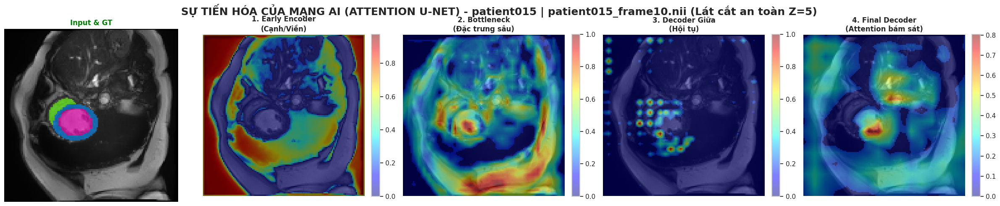

🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix)...


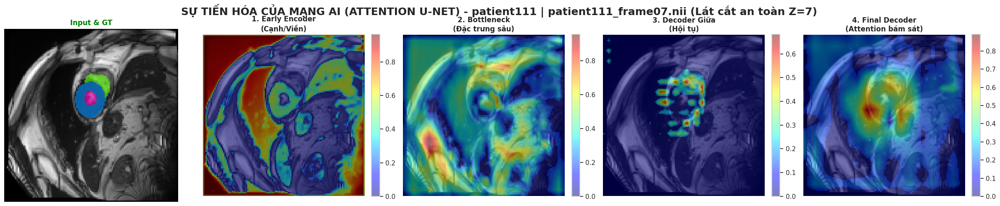

🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix)...


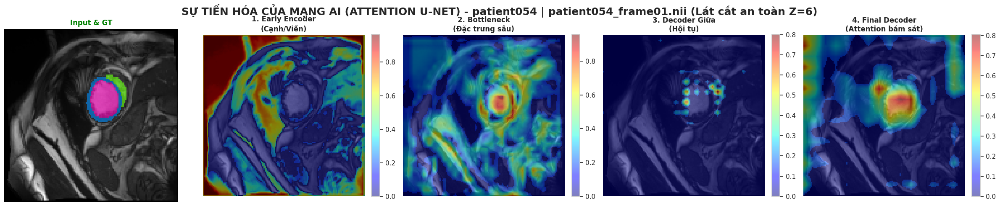

In [11]:
import os, random
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# ==============================================================================
# 📊 LAYER-WISE EVOLUTION (PHIÊN BẢN CHỐNG NHIỄU & CÂN BẰNG MÀU)
# ==============================================================================
def visualize_layer_evolution(model, items, device="cuda", sample_idx=None):
    print("🚀 Đang khởi tạo Layer-wise Evolution (Bản Fix)...")
    model.eval()
    
    # --- A. TỰ ĐỘNG QUÉT VÀ TÌM CÁC TẦNG QUAN TRỌNG ---
    target_layers = {}
    conv_modules = [(name, m) for name, m in model.named_modules() if isinstance(m, torch.nn.Conv3d)]
    
    if not conv_modules:
        print("❌ Lỗi: Không tìm thấy lớp Conv3D nào trong mô hình!")
        return

    # 1. Early Encoder
    target_layers["1. Early Encoder\n(Cạnh/Viền)"] = conv_modules[0][1]

    # 2. Bottleneck
    mid_idx = len(conv_modules) // 2
    target_layers["2. Bottleneck\n(Đặc trưng sâu)"] = conv_modules[mid_idx][1]

    # 3. Attention Decoder (Lấy tầng upsample ở giữa)
    up_modules = [(name, m) for name, m in conv_modules if 'up' in name.lower() or 'att' in name.lower()]
    if len(up_modules) >= 2:
        target_layers["3. Decoder Giữa\n(Hội tụ)"] = up_modules[len(up_modules)//2][1]
        
    # 4. Final Decoder 
    # [FIX]: Lùi lại 4 lớp để né Conv 1x1 cuối cùng gây đốm cục bộ
    target_layer_idx = -4 if len(conv_modules) >= 4 else -1
    target_layers["4. Final Decoder\n(Attention bám sát)"] = conv_modules[target_layer_idx][1]

    # --- B. CHUẨN BỊ DỮ LIỆU & TÌM SLICE AN TOÀN ---
    if sample_idx is None:
        sample_idx = random.randint(0, len(items)-1)
    
    ds = VolumeDataset([items[sample_idx]], augment=False)
    data = ds[0]
    img = data['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = data['label'].numpy()
    
    p_name = Path(items[sample_idx][0]).parent.name
    f_name = Path(items[sample_idx][0]).name
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # [FIX]: Tự động tìm Slice an toàn (Chứa nhiều tim nhất)
    sums = np.sum(label > 0, axis=(0, 1))
    valid_slices = np.where(sums > (sums.max() * 0.5))[0] # Lấy các slice có diện tích tim >= 50% max
    if len(valid_slices) > 0:
        slice_idx = valid_slices[len(valid_slices) // 2] # Lấy lát cắt ngay tâm khối tim
    else:
        slice_idx = label.shape[2] // 2

    # --- C. VẼ ĐỒ THỊ ---
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(24, 5))
    fig.suptitle(f"SỰ TIẾN HÓA CỦA MẠNG AI (ATTENTION U-NET) - {p_name} | {f_name} (Lát cắt an toàn Z={slice_idx})", fontsize=18, fontweight='bold')
    
    # Cột 1: Input & GT
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
    axes[0].set_title(f"Input & GT", fontweight='bold', color='green')
    axes[0].axis('off')

    # Các cột XAI
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        cam_extractor = GradCAM3D(model, layer_module)
        combined_heatmap = np.zeros_like(label, dtype=np.float32)
        
        # [FIX]: Chuẩn hóa công bằng từng class trước khi gộp
        for c in [1, 2, 3]: 
            try:
                h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                
                zoom_factor = (
                    label.shape[0] / h_small.shape[0],
                    label.shape[1] / h_small.shape[1],
                    label.shape[2] / h_small.shape[2]
                )
                h_large = zoom(h_small, zoom_factor, order=1)
                
                # Normalize class riêng rẽ
                if h_large.max() > 0:
                    h_large = h_large / h_large.max()
                    
                combined_heatmap = np.maximum(combined_heatmap, h_large)
            except Exception:
                continue
        
        cam_extractor.remove_hooks()

        # Hiển thị
        ax = axes[i + 1]
        ax.imshow(img_np[:, :, slice_idx], cmap='gray')
        
        # Threshold nhẹ để lọc nhiễu nền
        heatmap_slice = combined_heatmap[:, :, slice_idx]
        heatmap_slice[heatmap_slice < 0.15] = 0 
            
        im = ax.imshow(heatmap_slice, cmap='jet', alpha=0.5)
        ax.set_title(layer_name, fontweight='bold')
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- CHẠY ---
print("\n" + "="*80)
print("📊 TIẾN HÀNH TRÍCH XUẤT ĐỒ THỊ TIẾN HÓA LỚP ĐẶC TRƯNG")
print("="*80)
for _ in range(3):
    visualize_layer_evolution(model, te_items, device=DEVICE)

🚀 Đang tính toán Uncertainty Map (MC Dropout) cho 3 mẫu...
✅ Đã load weights từ: attention_unet3d_acdc_results/best_model.pth


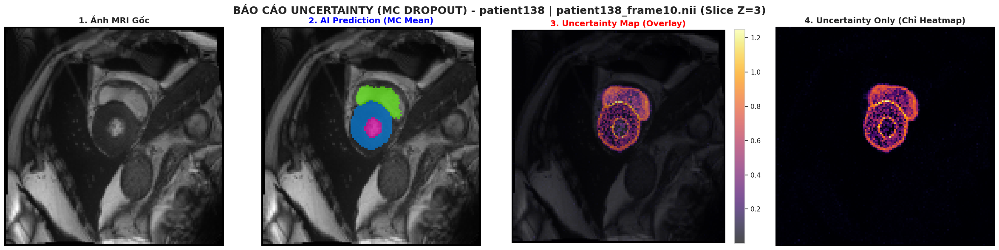

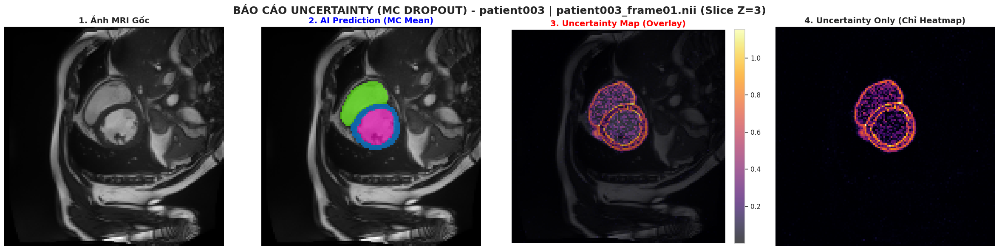

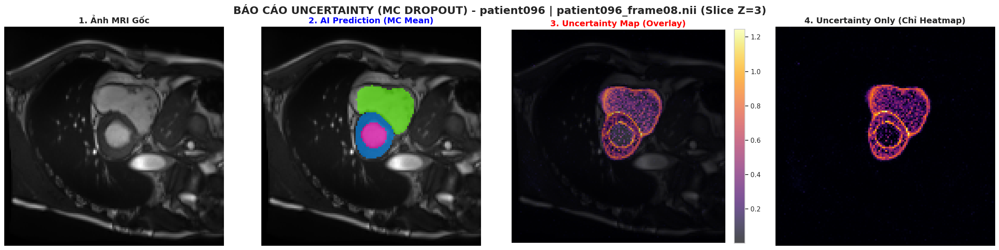

In [12]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random
from pathlib import Path

# ==============================================================================
# 1. HÀM TÍNH ĐỘ BẤT ĐỊNH (UNCERTAINTY BẰNG MC DROPOUT)
# ==============================================================================
def compute_uncertainty_mc_dropout(model, input_tensor, T=15):
    """
    Thực hiện Monte Carlo Dropout để ước lượng độ bất định.
    Input:
        - model: Mô hình SegResNet
        - input_tensor: Ảnh đầu vào (1, 1, D, H, W)
        - T: Số lần chạy lặp lại (sampling). T càng cao bản đồ càng mượt (thường 15-20).
    """
    # [QUAN TRỌNG] Kích hoạt chế độ Train để bật Dropout layer
    model.train() 
    
    outputs = []
    with torch.no_grad():
        for _ in range(T):
            # Forward pass
            logits = model(input_tensor)
            # Chuyển về xác suất (Probability)
            probs = torch.softmax(logits, dim=1)
            outputs.append(probs) # List các tensor (1, C, D, H, W)
            
    # Xếp chồng kết quả: (T, 1, C, D, H, W)
    outputs = torch.stack(outputs)
    
    # 1. Tính Mean Probability (Dự đoán trung bình của T lần chạy)
    mean_prob = torch.mean(outputs, dim=0) # (1, C, D, H, W)
    
    # 2. Tính Predictive Entropy (Độ bất định)
    # Công thức Shannon Entropy: H = - sum( p * log(p) )
    epsilon = 1e-6 # Tránh lỗi log(0)
    uncertainty_map = -torch.sum(mean_prob * torch.log(mean_prob + epsilon), dim=1)
    
    # [QUAN TRỌNG] Trả model về chế độ Eval để không ảnh hưởng các đoạn code khác
    model.eval()
    
    return mean_prob, uncertainty_map

# ==============================================================================
# 2. VISUALIZATION DASHBOARD (UNCERTAINTY XAI)
# ==============================================================================
def visualize_uncertainty_xai(model, items, device="cuda", num_samples=3):
    print(f"🚀 Đang tính toán Uncertainty Map (MC Dropout) cho {num_samples} mẫu...")
    
    # Load lại weight tốt nhất nếu cần thiết
    chk_path = SAVE_DIR / "best_model.pth"
    if not chk_path.exists():
        chk_path = Path("/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth")
    if chk_path.exists():
        model.load_state_dict(torch.load(chk_path, map_location=device))
        print(f"✅ Đã load weights từ: {chk_path}")
    
    # Chọn mẫu ngẫu nhiên từ tập Test
    indices = random.sample(range(len(items)), min(len(items), num_samples))

    for idx in indices:
        try:
            # Load data không augment
            ds = VolumeDataset([items[idx]], augment=False)
            sample = ds[0]
            
            img = sample["image"].unsqueeze(0).to(device) # (1, 1, D, H, W)
            label = sample["label"].numpy()
            
            # --- TÍNH UNCERTAINTY ---
            # Chạy MC Dropout 15 lần
            mean_prob, unc_map = compute_uncertainty_mc_dropout(model, img, T=15)
            
            # Lấy nhãn dự đoán từ mean_prob
            pred_mask = torch.argmax(mean_prob, dim=1).detach().cpu().numpy()[0]
            unc_map_np = unc_map.detach().cpu().numpy()[0] # (D, H, W)
            
            # --- TÌM SLICE ĐẸP NHẤT ---
            img_np = img.detach().cpu().numpy()[0, 0]
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else label.shape[2] // 2
            
            # Bóc tách tên Bệnh nhân & File
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name
            
            # --- VẼ HÌNH ---
            fig, axes = plt.subplots(1, 4, figsize=(24, 6))
            plt.suptitle(f"BÁO CÁO UNCERTAINTY (MC DROPOUT) - {p_name} | {f_name} (Slice Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: MRI Gốc
            axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
            axes[0].set_title("1. Ảnh MRI Gốc", fontsize=14, fontweight='bold')
            axes[0].axis('off')

            # Ô 2: Prediction (Mean)
            axes[1].imshow(img_np[:, :, slice_idx], cmap='gray')
            masked_pred = np.ma.masked_where(pred_mask[:, :, slice_idx] == 0, pred_mask[:, :, slice_idx])
            axes[1].imshow(masked_pred, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            axes[1].set_title("2. AI Prediction (MC Mean)", fontsize=14, fontweight='bold', color='blue')
            axes[1].axis('off')

            # Ô 3: Uncertainty Map (Entropy Heatmap Overlay) 
            axes[2].imshow(img_np[:, :, slice_idx], cmap='gray')
            im_unc = axes[2].imshow(unc_map_np[:, :, slice_idx], cmap='inferno', alpha=0.7) 
            axes[2].set_title("3. Uncertainty Map (Overlay)", fontsize=14, fontweight='bold', color='red')
            axes[2].axis('off')
            plt.colorbar(im_unc, ax=axes[2], fraction=0.046, pad=0.04)

            # Ô 4: Uncertainty Only (Zoom chi tiết)
            axes[3].imshow(unc_map_np[:, :, slice_idx], cmap='inferno')
            axes[3].set_title("4. Uncertainty Only (Chỉ Heatmap)", fontsize=14, fontweight='bold')
            axes[3].axis('off')

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

# --- GỌI HÀM ---
# Cứ truyền thẳng te_items vào đây, hàm tự động xử lý
visualize_uncertainty_xai(model, te_items, device=DEVICE, num_samples=3)

# dynunet

In [2]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from medpy.metric.binary import dc, jc, hd95
from monai.networks.nets import SegResNet

# ---------------- 0. CONFIGURATION ----------------
# Trỏ thẳng vào thư mục database để có thể lôi cả training và testing ra
BASE_DIR = Path("/kaggle/input/datasets/samdazel/automated-cardiac-diagnosis-challenge-miccai17/database")
TRAIN_DIR = BASE_DIR / "training"
TEST_DIR = BASE_DIR / "testing"

SAVE_DIR = Path("./segresnet3d_acdc_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 16)
NUM_CLASSES = 4
BATCH_SIZE = 2
EPOCHS = 100
LR = 1e-4
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, NUM_CLASSES).permute(0,4,1,2,3).float()
        dims = (0,2,3,4)
        inter = torch.sum(pred[:,1:] * target_oh[:,1:], dims)
        union = torch.sum(pred[:,1:] + target_oh[:,1:], dims)
        return 1 - ((2*inter + self.smooth) / (union + self.smooth)).mean()

# ---------------- 2. DATASET (RESIZE ONLY – NO CROP) ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt  = nib.load(gt_p).get_fdata().astype(np.int64)

        zoom = (
            TARGET_SIZE[0] / img.shape[0],
            TARGET_SIZE[1] / img.shape[1],
            TARGET_SIZE[2] / img.shape[2]
        )
        img = ndi.zoom(img, zoom, order=1)
        gt  = ndi.zoom(gt,  zoom, order=0)

        if self.augment:
            if random.random() > 0.5:
                ax = random.randint(0,2)
                img = np.flip(img, ax).copy()
                gt  = np.flip(gt, ax).copy()

        img = (img - img.mean()) / (img.std() + 1e-6)

        return {
            "image": torch.from_numpy(img[None]).float(),
            "label": torch.from_numpy(gt).long()
        }

# ---------------- 3. METRICS ----------------
def get_metrics(p, g):
    res = {}
    for cl, name in zip([1,2,3], ['RV','MYO','LV']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0:
            res[name] = (0.0, 0.0, 50.0)
            continue
        res[name] = (
            dc(pc, gc),
            jc(pc, gc),
            hd95(pc, gc) if pc.sum()>0 else 50.0
        )
    return res

# ---------------- 4. GỘP DATA 150 BN & CHIA CHUẨN (80-20-50) ----------------
patient_data = {}
for folder_dir in [TRAIN_DIR, TEST_DIR]:
    if not folder_dir.exists(): continue
    for p in sorted(folder_dir.iterdir()):
        if not p.is_dir() or not p.name.startswith("patient"): continue
        
        pid = p.name
        info_file = p / "Info.cfg"
        disease = "NOR" # Mặc định
        
        # Đọc nhãn bệnh để chia tầng (Stratify)
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if line.startswith("Group:"): 
                        disease = line.split(":")[1].strip()
        
        gt_nodes = list(p.glob("*_frame*_gt.nii*"))
        scans = []
        for gt_node in gt_nodes:
            img_node = gt_node.parent / gt_node.name.replace("_gt", "")
            if img_node.exists():
                scans.append((str(img_node), str(gt_node)))
                
        if scans:
            patient_data[pid] = {'disease': disease, 'scans': scans}

p_ids = list(patient_data.keys())
p_labels = [patient_data[pid]['disease'] for pid in p_ids]

# CHIA TẦNG (STRATIFY) ĐỂ ĐỀU BỆNH: 80 Train - 20 Val - 50 Test
# Lấy 70 ca ra khỏi 150 ca => Còn 80 Train
train_ids, temp_ids, train_labels, temp_labels = train_test_split(
    p_ids, p_labels, test_size=70, random_state=SEED, stratify=p_labels
)
# Tách 70 ca Temp thành 50 Test và 20 Val
val_ids, test_ids, val_labels, test_labels = train_test_split(
    temp_ids, temp_labels, test_size=50, random_state=SEED, stratify=temp_labels
)

tr_items = [scan for pid in train_ids for scan in patient_data[pid]['scans']]
va_items = [scan for pid in val_ids for scan in patient_data[pid]['scans']]
te_items = [scan for pid in test_ids for scan in patient_data[pid]['scans']]

print(f"✅ Đã chia tầng xong: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
# Má có thể in thử tỉ lệ bệnh ở tập test để kiểm tra:
print(f"Tỉ lệ bệnh tập Test: {pd.Series(test_labels).value_counts().to_dict()}")

loaders = {
    "train": DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    "val":   DataLoader(VolumeDataset(va_items), 1)
}

print(f"Tổng hợp & Chia Data: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
print("-"*170)

# ---------------- 5. MODEL ----------------
model = SegResNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    init_filters=32,
    dropout_prob=0.2
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, "max", patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler("cuda")

best_dice = 0.0

# ---------------- 6. CSV LOG ----------------
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, "w", newline="") as f:
    csv.writer(f).writerow([
        "epoch","tr_loss","va_loss","tr_dice",
        "va_dice","va_iou","va_hd95",
        "rv_d","myo_d","lv_d","time" 
    ])

# ---------------- 7. TRAINING LOOP ----------------
for ep in range(1, EPOCHS+1):
    t0 = time.time()
    model.train()
    tr_l, tr_d = [], []

    for b in tqdm(loaders["train"], desc=f"Epoch {ep:02d}", leave=False):
        img = b["image"].to(DEVICE)
        lab = b["label"].to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            out = model(img)
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_l.append(loss.item())
        tr_d.append(dc((out.argmax(1)>0).cpu().numpy(), (lab>0).cpu().numpy()))

    # ---------------- VALIDATION ----------------
    model.eval()
    va_l, acc = [], {"RV":[], "MYO":[], "LV":[]}

    with torch.no_grad():
        for b in loaders["val"]:
            img = b["image"].to(DEVICE)
            lab = b["label"].to(DEVICE)

            with torch.amp.autocast("cuda"):
                out = model(img)
                loss = ce_criterion(out, lab) + dice_criterion(out, lab)
            
            va_l.append(loss.item())

            p = out.argmax(1).cpu().numpy()[0]
            g = lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for k in acc: acc[k].append(m[k])

    tr_loss = np.mean(tr_l)
    va_loss = np.mean(va_l)
    tr_dice = np.mean(tr_d)

    stats = {k: np.mean(acc[k],0) for k in acc}
    va_dice = np.mean([stats[k][0] for k in stats])
    va_iou  = np.mean([stats[k][1] for k in stats])
    va_hd95 = np.mean([stats[k][2] for k in stats])

    scheduler.step(va_dice)
    t_total = time.time() - t0

    print(
        f"Ep {ep:02d} | {t_total:5.1f}s | "
        f"Tr.Loss {tr_loss:.4f} | Va.Loss {va_loss:.4f} | "
        f"Tr.Dice {tr_dice:.4f} | Va.Dice {va_dice:.4f} | "
        f"IoU {va_iou:.4f} | HD95 {va_hd95:.2f}"
    )

    with open(CSV_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            ep, tr_loss, va_loss, tr_dice,
            va_dice, va_iou, va_hd95,
            stats["RV"][0], stats["MYO"][0], stats["LV"][0], t_total
        ])

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), SAVE_DIR/"best_model.pth")
        print(f"New Best Model Saved | Dice {best_dice:.4f}")

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
2026-05-28 16:30:12.440937: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779985812.677602      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779985812.740466      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779985813.258185      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779985813.258231      57 computation_placer.cc:1

✅ Đã chia tầng xong: Train 80 BN | Val 20 BN | Test 50 BN
Tỉ lệ bệnh tập Test: {'MINF': 10, 'DCM': 10, 'NOR': 10, 'RV': 10, 'HCM': 10}
Tổng hợp & Chia Data: Train 80 BN | Val 20 BN | Test 50 BN
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Ep 01 |  27.1s | Tr.Loss 1.7038 | Va.Loss 1.5474 | Tr.Dice 0.0014 | Va.Dice 0.0002 | IoU 0.0001 | HD95 49.34
New Best Model Saved | Dice 0.0002


Ep 02 |  37.6s | Tr.Loss 1.4882 | Va.Loss 1.4333 | Tr.Dice 0.1963 | Va.Dice 0.1283 | IoU 0.0951 | HD95 42.31
New Best Model Saved | Dice 0.1283


Ep 03 |  35.4s | Tr.Loss 1.3800 | Va.Loss 1.3267 | Tr.Dice 0.5052 | Va.Dice 0.3090 | IoU 0.2225 | HD95 28.11
New Best Model Saved | Dice 0.3090


Ep 04 |  31.1s | Tr.Loss 1.2714 | Va.Loss 1.2155 | Tr.Dice 0.6181 | Va.Dice 0.3604 | IoU 0.2665 | HD95 24.59
New Best Model Saved | Dice 0.3604


... (92 outputs left out)

Ep 97 |  25.9s | Tr.Loss 0.1070 | Va.Loss 0.1697 | Tr.Dice 0.9596 | Va.Dice 0.8698 | IoU 0.7756 | HD95 1.54


Ep 98 |  25.9s | Tr.Loss 0.1070 | Va.Loss 0.1724 | Tr.Dice 0.9594 | Va.Dice 0.8679 | IoU 0.7732 | HD95 1.46


Ep 99 |  26.1s | Tr.Loss 0.1073 | Va.Loss 0.1615 | Tr.Dice 0.9594 | Va.Dice 0.8749 | IoU 0.7831 | HD95 1.51
New Best Model Saved | Dice 0.8749


Ep 100 |  29.5s | Tr.Loss 0.1048 | Va.Loss 0.1663 | Tr.Dice 0.9606 | Va.Dice 0.8720 | IoU 0.7791 | HD95 1.41


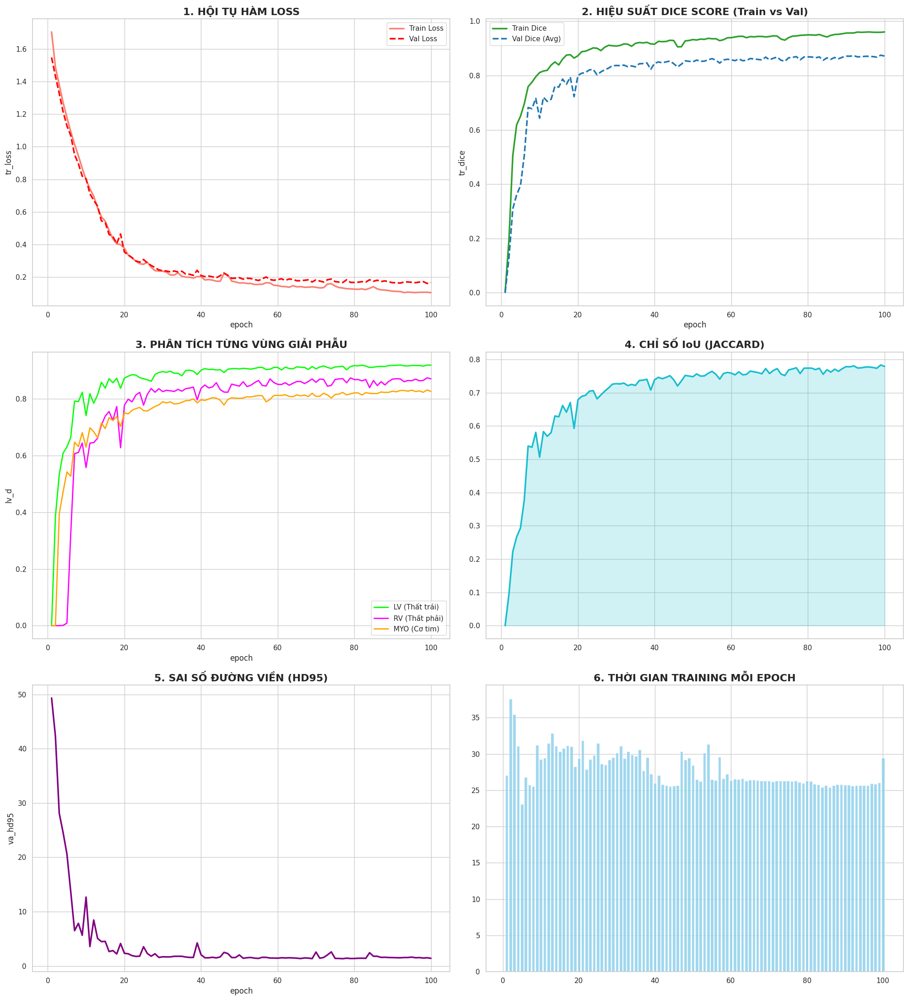


            BÁO CÁO KẾT QUẢ MÔ HÌNH SEGRESNET-3D            
🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: 99
  > Dice Score (Avg)          :     0.8749
  > IoU (Jaccard)             :     0.7831
  > HD95                      :    1.51 mm
  > Dice - LV                 :     0.9191
  > Dice - RV                 :     0.8742
  > Dice - MYO                :     0.8315


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đảm bảo định nghĩa lại đường dẫn nếu chạy cell này độc lập
SAVE_DIR = Path("./segresnet3d_acdc_results")
CSV_PATH = SAVE_DIR / "training_log.csv"

# ================= 8. DASHBOARD & REPORT (MÃ CỦA MÁ) =================
def plot_dashboard_matched(log_path):
    if not log_path.exists():
        print(f"❌ Lỗi: Không tìm thấy file log tại {log_path}")
        return

    df = pd.read_csv(log_path)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.2)

    # --- BIỂU ĐỒ 1: LOSS ---
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='tr_loss', label='Train Loss', color='salmon', linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='va_loss', label='Val Loss', color='red', linewidth=2.5, linestyle='--')
    axes[0, 0].set_title('1. HỘI TỤ HÀM LOSS', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 2: DICE TỔNG QUÁT ---
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='tr_dice', label='Train Dice', color='#2ca02c', linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='va_dice', label='Val Dice (Avg)', color='#1f77b4', linewidth=2.5, linestyle='--')
    axes[0, 1].set_title('2. HIỆU SUẤT DICE SCORE (Train vs Val)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 3: DICE CHI TIẾT ---
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='lv_d', label='LV (Thất trái)', color='lime', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='rv_d', label='RV (Thất phải)', color='magenta', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='myo_d', label='MYO (Cơ tim)', color='orange', linewidth=2)
    axes[1, 0].set_title('3. PHÂN TÍCH TỪNG VÙNG GIẢI PHẪU', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 4: IoU ---
    axes[1, 1].fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
    axes[1, 1].plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Mean IoU')
    axes[1, 1].set_title('4. CHỈ SỐ IoU (JACCARD)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 5: HD95 ---
    sns.lineplot(ax=axes[2, 0], data=df, x='epoch', y='va_hd95', color='purple', linewidth=2.5)
    axes[2, 0].set_title('5. SAI SỐ ĐƯỜNG VIỀN (HD95)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 6: THỜI GIAN ---
    axes[2, 1].bar(df['epoch'], df['time'], color='skyblue', alpha=0.8)
    axes[2, 1].set_title('6. THỜI GIAN TRAINING MỖI EPOCH', fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.savefig(SAVE_DIR / "final_dashboard.png", dpi=300)
    plt.show()

def print_report_matched(log_path):
    if not log_path.exists(): return
    df = pd.read_csv(log_path)
    best_row = df.iloc[df['va_dice'].idxmax()]
    
    print("\n" + "="*60)
    print(f"{'BÁO CÁO KẾT QUẢ MÔ HÌNH SEGRESNET-3D':^60}")
    print("="*60)
    print(f"🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: {int(best_row['epoch'])}")
    for l, v in [["Dice Score (Avg)", f"{best_row['va_dice']:.4f}"], ["IoU (Jaccard)", f"{best_row['va_iou']:.4f}"], 
                 ["HD95", f"{best_row['va_hd95']:.2f} mm"], ["Dice - LV", f"{best_row['lv_d']:.4f}"], 
                 ["Dice - RV", f"{best_row['rv_d']:.4f}"], ["Dice - MYO", f"{best_row['myo_d']:.4f}"]]:
        print(f"  > {l:<25} : {v:>10}")
    print("="*60)

# Thực thi vẽ biểu đồ sau khi train xong
plot_dashboard_matched(CSV_PATH)
print_report_matched(CSV_PATH)

In [4]:
# -------------------------------------------------------------------------
# CELL 9: ĐÁNH GIÁ ĐỊNH LƯỢNG TRÊN TẬP TEST (BẢNG TỔNG KẾT GỌN GÀNG)
# -------------------------------------------------------------------------
from torch.utils.data import DataLoader
from monai.data import Dataset
import numpy as np
import torch
from tqdm.auto import tqdm
from pathlib import Path

# Sửa lại đường dẫn cho chuẩn (Trỏ thẳng vào thư mục input của Kaggle)
model_path = Path("/kaggle/working/segresnet3d_acdc_results/best_model.pth")

if model_path.exists():
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    print(f"✅ Đã load weights từ: {model_path}")
else:
    print(f"❌ Chưa tìm thấy file weights tại {model_path}")

model.eval()

# 2. Tạo Test Loader (Sử dụng đúng VolumeDataset của bạn để Resize chuẩn)
# augment=False để không lật ảnh lung tung
test_dataset = VolumeDataset(te_items, augment=False) 
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# 3. Khởi tạo biến lưu trữ kết quả
metrics_storage = {
    'LV': {'dice': [], 'iou': [], 'hd95': []},
    'RV': {'dice': [], 'iou': [], 'hd95': []},
    'MYO': {'dice': [], 'iou': [], 'hd95': []}
}
overall_metrics = {'dice': [], 'iou': [], 'hd95': []}

print(f"🚀 Đang đánh giá trên {len(te_items)} mẫu tập Test...")

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Testing"):
        # Lấy dữ liệu và đưa lên GPU
        img = batch["image"].to(DEVICE)
        lab = batch["label"].to(DEVICE)
        
        # Inference (Dự đoán)
        out = model(img)
        
        # Xử lý kết quả
        p = torch.argmax(out, dim=1).cpu().numpy()[0]
        g = lab.cpu().numpy()[0]
        
        # Tính metrics bằng hàm get_metrics của bạn
        m = get_metrics(p, g)
        
        sample_dices = []
        sample_ious = []
        sample_hds = []
        
        # Lưu lại từng lớp
        for cls_name in ['LV', 'RV', 'MYO']:
            d, i, h = m[cls_name]
            
            metrics_storage[cls_name]['dice'].append(d)
            metrics_storage[cls_name]['iou'].append(i)
            metrics_storage[cls_name]['hd95'].append(h)
            
            sample_dices.append(d)
            sample_ious.append(i)
            sample_hds.append(h)
        
        # Tính trung bình cộng (Average) cho mẫu này (Overall)
        overall_metrics['dice'].append(np.mean(sample_dices))
        overall_metrics['iou'].append(np.mean(sample_ious))
        overall_metrics['hd95'].append(np.mean(sample_hds))

# 4. In Báo Cáo Kết Quả Gọn Gàng
print("\n" + "="*65)
print(f"{'KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST':^65}")
print("="*65)

# Tính trung bình toàn bộ tập test
avg_dice = np.mean(overall_metrics['dice'])
avg_iou = np.mean(overall_metrics['iou'])
avg_hd95 = np.mean(overall_metrics['hd95'])

print(f"⭐ Dice Score trung bình (All Classes): {avg_dice:.4f}")
print(f"⭐ IoU trung bình (All Classes):        {avg_iou:.4f}")
print(f"⭐ HD95 trung bình (All Classes):       {avg_hd95:.2f} mm")
print("-" * 65)

# In bảng chi tiết từng lớp
print(f"{'Lớp (Class)':<15} | {'Dice':<10} | {'IoU':<10} | {'HD95 (mm)':<10}")
print("-" * 65)

for cls_name in ['LV', 'RV', 'MYO']:
    d_mean = np.mean(metrics_storage[cls_name]['dice'])
    i_mean = np.mean(metrics_storage[cls_name]['iou'])
    h_mean = np.mean(metrics_storage[cls_name]['hd95'])
    
    print(f"{cls_name:<15} | {d_mean:.4f}     | {i_mean:.4f}     | {h_mean:.2f}")

print("="*65)

✅ Đã load weights từ: /kaggle/working/segresnet3d_acdc_results/best_model.pth
🚀 Đang đánh giá trên 100 mẫu tập Test...


Testing:   0%|          | 0/100 [00:00<?, ?it/s]


            KẾT QUẢ ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST             
⭐ Dice Score trung bình (All Classes): 0.8680
⭐ IoU trung bình (All Classes):        0.7758
⭐ HD95 trung bình (All Classes):       1.37 mm
-----------------------------------------------------------------
Lớp (Class)     | Dice       | IoU        | HD95 (mm) 
-----------------------------------------------------------------
LV              | 0.9115     | 0.8457     | 1.27
RV              | 0.8535     | 0.7547     | 1.65
MYO             | 0.8389     | 0.7271     | 1.17


🚀 Đang khởi tạo XAI Dashboard cho 3 mẫu...


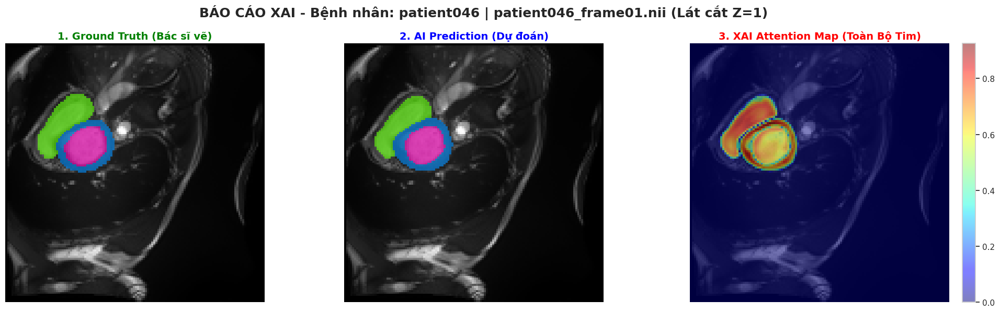

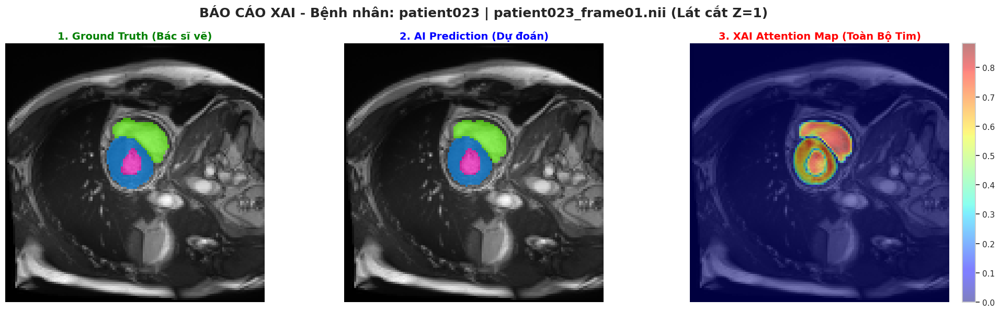

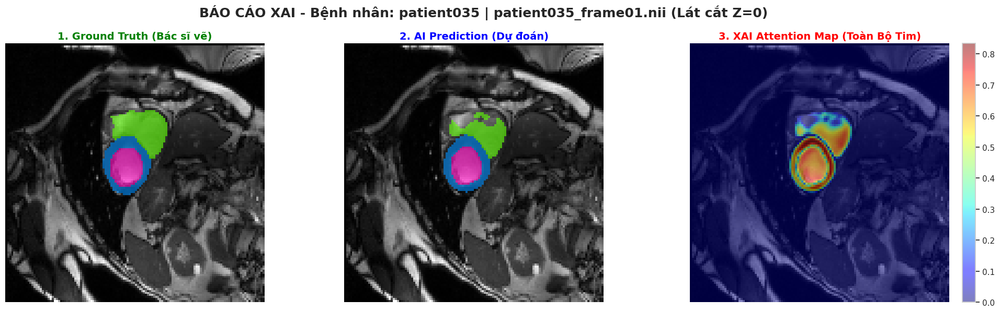

✅ Hoàn tất quá trình trích xuất XAI Dashboard!


In [5]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random

# ==============================================================================
# 1. CLASS GRAD-CAM 3D (CORE ENGINE)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        
        # Đăng ký hook để "nghe lén" dữ liệu khi chạy qua layer này
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        """Quan trọng: Gỡ bỏ hook để giải phóng bộ nhớ"""
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx):
        # Reset gradient cũ
        self.model.zero_grad()
        
        # 1. Forward Pass (Chạy lại forward để tạo đồ thị tính toán mới)
        output = self.model(input_tensor)
        
        # 2. Backward Pass: Chỉ quan tâm đến Class đích (class_idx)
        score = output[0, class_idx].sum()
        # Bỏ retain_graph=True vì ta đã forward lại từ đầu, tránh lỗi tràn bộ nhớ GPU
        score.backward() 

        # 3. Tạo CAM
        # Global Average Pooling trên gradients (trọng số alpha)
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        
        # Nhân trọng số với activation map
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        
        # ReLU: Chỉ lấy các đặc trưng có ảnh hưởng dương tính (tích cực)
        cam = F.relu(cam).detach().cpu().numpy()
        
        # Chuẩn hóa về [0, 1] để hiển thị
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        
        return cam

# ==============================================================================
# 2. DASHBOARD VISUALIZATION FUNCTION
# ==============================================================================
def visualize_xai_prediction_dashboard(model, items, device="cuda", num_samples=6):
    """
    Hàm tổng hợp: Chạy dự đoán + Tính Grad-CAM + Vẽ Dashboard 3 cột
    """
    print(f"🚀 Đang khởi tạo XAI Dashboard cho {num_samples} mẫu...")
    
    model.eval()
    
    # --- A. TỰ ĐỘNG TÌM TARGET LAYER ---
    # Lấy layer Conv3D cuối cùng của SegResNet làm Target Layer
    conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
    if not conv_layers:
        print("❌ Lỗi: Không tìm thấy layer Conv3D nào trong model!")
        return
    target_layer = conv_layers[-1]
    
    # Khởi tạo công cụ Grad-CAM
    cam_extractor = GradCAM3D(model, target_layer)
    
    # Load dataset test (Tắt augment để giữ nguyên gốc ảnh)
    dataset = VolumeDataset(items, augment=False) 
    
    # Chọn mẫu ngẫu nhiên
    sample_indices = random.sample(range(len(items)), min(len(items), num_samples))

    # --- B. VÒNG LẶP XỬ LÝ TỪNG MẪU ---
    for idx in sample_indices:
        try:
            data = dataset[idx]
            
            # Input cần require grad để tính ngược
            img = data['image'].unsqueeze(0).to(device)
            img.requires_grad = True 
            
            label = data['label'].numpy() # Shape: (128, 128, 16)
            
            # 1. Chạy dự đoán (Prediction)
            with torch.no_grad(): # Tắt grad khúc này để tiết kiệm VRAM
                out = model(img)
                pred = torch.argmax(out, 1).detach().cpu().numpy()[0]

            # 2. Tính Grad-CAM tổng hợp (Gộp Heatmap của LV, MYO, RV)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Duyệt qua 3 lớp tim: 1(RV), 2(MYO), 3(LV)
            for c in [1, 2, 3]: 
                try:
                    # Tạo heatmap thô (kích thước nhỏ)
                    h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                    
                    # Tính tỷ lệ phóng to để khớp với ảnh gốc
                    zoom_factor = (
                        label.shape[0] / h_small.shape[0],
                        label.shape[1] / h_small.shape[1],
                        label.shape[2] / h_small.shape[2]
                    )
                    
                    # Phóng to heatmap (Zoom)
                    h_large = zoom(h_small, zoom_factor, order=1)
                    
                    # Cộng dồn vào bản đồ nhiệt tổng (Lấy max để giữ điểm nóng nhất)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except Exception as e:
                    continue

            # 3. Chọn lát cắt (Slice) hiển thị
            img_np = img.detach().cpu().numpy()[0, 0]
            
            # Tìm lát cắt có diện tích tim lớn nhất
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else (label.shape[2] // 2)
            
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name

            # --- C. VẼ ĐỒ THỊ ---
            plt.figure(figsize=(20, 6))
            plt.suptitle(f"BÁO CÁO XAI - Bệnh nhân: {p_name} | {f_name} (Lát cắt Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: Ground Truth
            plt.subplot(1, 3, 1)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Masked array để ẩn phần nền (class 0)
            gt_masked = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
            plt.imshow(gt_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("1. Ground Truth (Bác sĩ vẽ)", fontsize=14, color='green', fontweight='bold')
            plt.axis('off')

            # Ô 2: Prediction
            plt.subplot(1, 3, 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            pred_masked = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
            plt.imshow(pred_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("2. AI Prediction (Dự đoán)", fontsize=14, color='blue', fontweight='bold')
            plt.axis('off')

            # Ô 3: XAI Attention Map (Grad-CAM) 
            plt.subplot(1, 3, 3)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Hiển thị Heatmap đè lên ảnh gốc
            im = plt.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            plt.title("3. XAI Attention Map (Toàn Bộ Tim)", fontsize=14, color='red', fontweight='bold')
            plt.axis('off')
            plt.colorbar(im, fraction=0.046, pad=0.04)

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

    # Dọn dẹp Hook cuối cùng
    cam_extractor.remove_hooks()
    print("✅ Hoàn tất quá trình trích xuất XAI Dashboard!")

# ==============================================================================
# 3. RUN (GỌI HÀM)
# ==============================================================================
visualize_xai_prediction_dashboard(model, te_items, device=DEVICE, num_samples=3)


🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


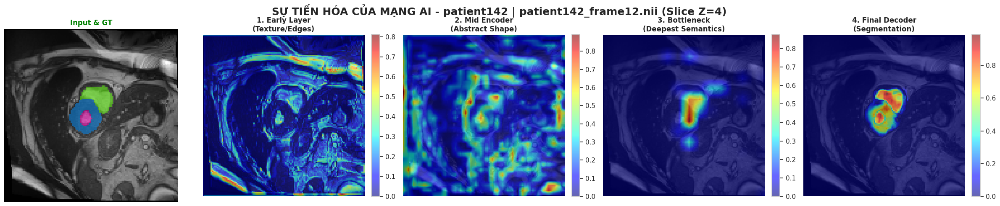

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


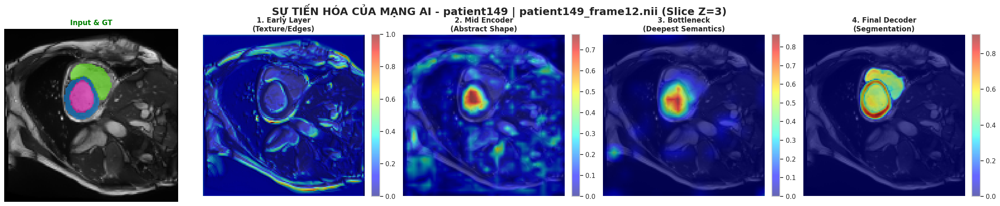

🚀 Đang khởi tạo Layer-wise Visualization...
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)...
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)...
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)...
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)...


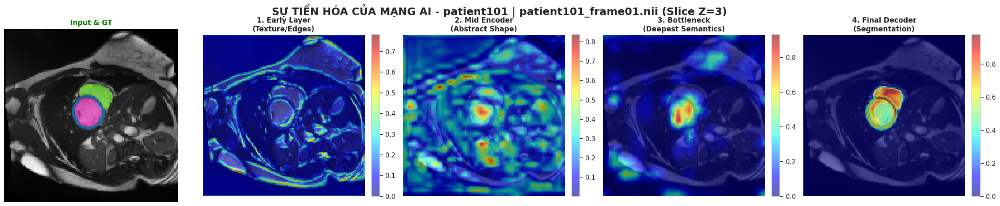

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
from scipy.ndimage import zoom
from pathlib import Path

def visualize_layer_evolution(model, items, device="cuda", sample_idx=None):
    """
    Trực quan hóa sự tiến hóa của vùng chú ý (Attention) qua các tầng mạng.
    (Phiên bản đã tối ưu và đồng bộ bộ hook)
    """
    print("🚀 Đang khởi tạo Layer-wise Visualization...")
    model.eval()
    
    # --- ĐỊNH NGHĨA CÁC TẦNG CẦN SOI TỪ CẠN ĐẾN SÂU ---
    target_layers = {
        "1. Early Layer\n(Texture/Edges)": model.convInit,
        "2. Mid Encoder\n(Abstract Shape)": model.down_layers[2], 
        "3. Bottleneck\n(Deepest Semantics)": model.down_layers[3],
        "4. Final Decoder\n(Segmentation)": model.up_layers[-1] # Sửa thành lớp upsample cuối
    }

    # Chọn mẫu
    if sample_idx is None:
        sample_idx = random.randint(0, len(items)-1)
    
    # Bật augment=False để giữ ảnh gốc không bị lật lung tung
    ds = VolumeDataset([items[sample_idx]], augment=False)
    data = ds[0]
    img = data['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = data['label'].numpy()
    
    # Lấy thông tin ID bệnh nhân để in tiêu đề
    p_name = Path(items[sample_idx][0]).parent.name
    f_name = Path(items[sample_idx][0]).name
    
    # Lấy ảnh gốc để hiển thị
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tìm slice có diện tích tim lớn nhất
    sums = np.sum(label > 0, axis=(0, 1))
    slice_idx = np.argmax(sums) if np.max(sums) > 0 else (label.shape[2] // 2)

    # --- KHỞI TẠO BẢNG ĐIỀU KHIỂN (PLOT) ---
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(24, 5))
    fig.suptitle(f"SỰ TIẾN HÓA CỦA MẠNG AI - {p_name} | {f_name} (Slice Z={slice_idx})", fontsize=18, fontweight='bold')
    
    # Cột 1: Ảnh gốc + Ground Truth (Mặt nạ đáp án)
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    axes[0].set_title(f"Input & GT", fontweight='bold', color='green')
    axes[0].axis('off')

    # --- DUYỆT QUA TỪNG TẦNG ---
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        print(f"  >> Đang phân tích tầng: {layer_name.replace(chr(10), ' ')}...")
        
        # Khởi tạo GradCAM cho tầng hiện tại
        cam_extractor = GradCAM3D(model, layer_module)
        
        # Tính Heatmap tổng hợp cho cả quả tim (LV + MYO + RV)
        combined_heatmap = np.zeros_like(label, dtype=np.float32)
        
        for c in [1, 2, 3]: 
            try:
                # Generate CAM từ class GradCAM3D
                h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                
                # Tính tỷ lệ và zoom lên kích thước gốc
                zoom_factor = (
                    label.shape[0] / h_small.shape[0],
                    label.shape[1] / h_small.shape[1],
                    label.shape[2] / h_small.shape[2]
                )
                h_large = zoom(h_small, zoom_factor, order=1)
                
                # Gộp dồn điểm nóng
                combined_heatmap = np.maximum(combined_heatmap, h_large)
            except Exception as e:
                continue
        
        # Giải phóng Hook ngay lập tức để tiết kiệm VRAM
        cam_extractor.remove_hooks()

        # Render hình ảnh
        ax = axes[i + 1]
        ax.imshow(img_np[:, :, slice_idx], cmap='gray')
        
        # Normalize để màu sắc hiển thị đồng đều giữa các tầng
        if combined_heatmap.max() > 0:
            combined_heatmap /= combined_heatmap.max()
            
        im = ax.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.6)
        ax.set_title(layer_name, fontweight='bold')
        ax.axis('off')
        
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- CHẠY THỬ 3 MẪU ---
print("\n" + "="*50)
for _ in range(3):
    visualize_layer_evolution(model, te_items, device=DEVICE)

🚀 Đang chọn ngẫu nhiên 3 bệnh nhân để nội soi 8 tầng mạng...

>> Tiến hành phân tích Ca số #1...


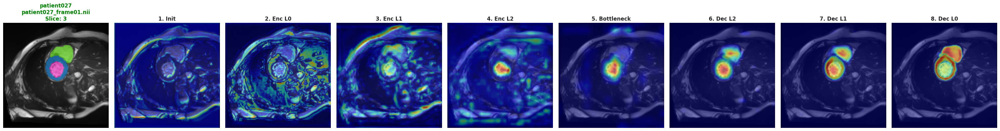


>> Tiến hành phân tích Ca số #2...


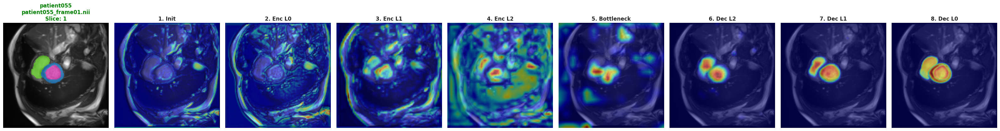


>> Tiến hành phân tích Ca số #3...


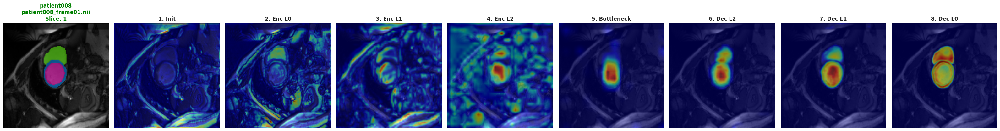


✅ Hoàn tất! Quá trình nội soi đã kết thúc.


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import random
import os
from scipy.ndimage import zoom
from pathlib import Path

# ==============================================================================
# 1. CLASS GRAD-CAM (Giữ nguyên - Rất ổn định)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmap(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        loss = output[0, class_idx].sum()
        loss.backward(retain_graph=True)
        
        if self.gradients is None or self.activations is None: return None
            
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

    def remove_hooks(self):
        for h in self.handles: h.remove()

# ==============================================================================
# 2. HÀM VẼ 1 BỆNH NHÂN (Đã Fix lỗi lấy tên File & Augment)
# ==============================================================================
def visualize_single_patient(model, item, device, patient_idx):
    # Định nghĩa các tầng từ ngoài vào trong, rồi từ trong ra ngoài
    target_layers = {
        "1. Init":         model.convInit,
        "2. Enc L0":       model.down_layers[0],
        "3. Enc L1":       model.down_layers[1],
        "4. Enc L2":       model.down_layers[2],
        "5. Bottleneck":   model.down_layers[3],
        "6. Dec L2":       model.up_layers[0],
        "7. Dec L1":       model.up_layers[1],
        "8. Dec L0":       model.up_layers[2]
    }

    # Prepare Data (Tắt augment để ảnh nằm im)
    ds = VolumeDataset([item], augment=False)
    img = ds[0]['image'].unsqueeze(0).to(device)
    img.requires_grad = True
    label = ds[0]['label'].numpy()
    img_np = img.detach().cpu().numpy()[0, 0]
    
    # Tìm slice đẹp nhất (Chứa nhiều thông tin tim nhất)
    sums = np.sum(label > 0, axis=(0, 1))
    slice_idx = np.argmax(sums) if np.max(sums) > 0 else img_np.shape[2] // 2

    # Setup Plot (1 hàng, 9 cột) - Kéo dài khung hình để không bị ép
    fig, axes = plt.subplots(1, len(target_layers) + 1, figsize=(32, 4))
    
    # Cột 1: Input + GT
    axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
    gt_mask = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
    axes[0].imshow(gt_mask, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
    
    # 🌟 SỬA TẠI ĐÂY: Dùng Path để bóc tách chính xác tên Bệnh nhân và Frame
    try:
        p_name = Path(item[0]).parent.name
        f_name = Path(item[0]).name
        title_text = f"{p_name}\n{f_name}\nSlice: {slice_idx}"
    except:
        title_text = f"Patient {patient_idx}\nSlice {slice_idx}"

    axes[0].set_title(title_text, fontweight='bold', color='green', fontsize=12)
    axes[0].axis('off')

    # Vẽ các tầng
    for i, (layer_name, layer_module) in enumerate(target_layers.items()):
        try:
            cam_extractor = GradCAM3D(model, layer_module)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Quét 3 lớp tim (RV, MYO, LV)
            for c in [1, 2, 3]: 
                try:
                    h = cam_extractor.generate_heatmap(img, class_idx=c)
                    if h is None: continue
                    z_factor = (label.shape[0]/h.shape[0], label.shape[1]/h.shape[1], label.shape[2]/h.shape[2])
                    h_large = zoom(h, z_factor, order=1)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except: continue
            
            cam_extractor.remove_hooks()

            ax = axes[i + 1]
            ax.imshow(img_np[:, :, slice_idx], cmap='gray')
            if combined_heatmap.max() > 0: 
                combined_heatmap /= combined_heatmap.max()
            ax.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5)
            ax.set_title(layer_name, fontweight='bold', fontsize=12)
            ax.axis('off')
        except: continue

    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. HÀM CHẠY 3 BỆNH NHÂN (Wrapper)
# ==============================================================================
def run_3_patients_demo(model, items, device="cuda"):
    print("🚀 Đang chọn ngẫu nhiên 3 bệnh nhân để nội soi 8 tầng mạng...")
    model.eval()
    
    # Lấy 3 chỉ số ngẫu nhiên không trùng nhau
    count = min(3, len(items))
    indices = random.sample(range(len(items)), count)
    
    for i, idx in enumerate(indices):
        print(f"\n>> Tiến hành phân tích Ca số #{i+1}...")
        visualize_single_patient(model, items[idx], device, idx)
    
    print("\n✅ Hoàn tất! Quá trình nội soi đã kết thúc.")

# --- THỰC THI ---
run_3_patients_demo(model, te_items, device=DEVICE)

🚀 Đang tính toán Uncertainty Map (MC Dropout) cho 3 mẫu...
✅ Đã load weights từ: segresnet3d_acdc_results/best_model.pth


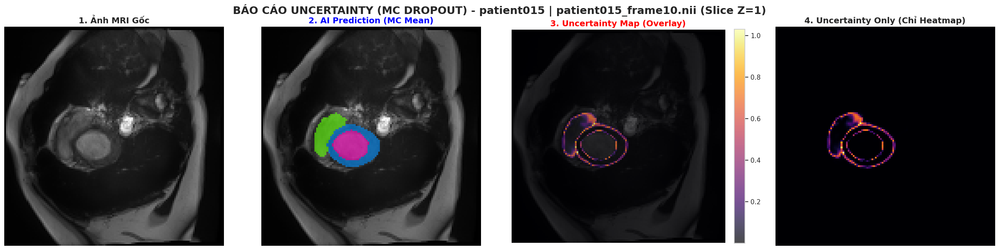

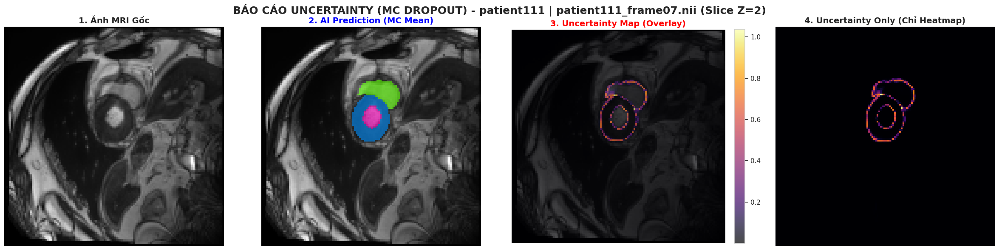

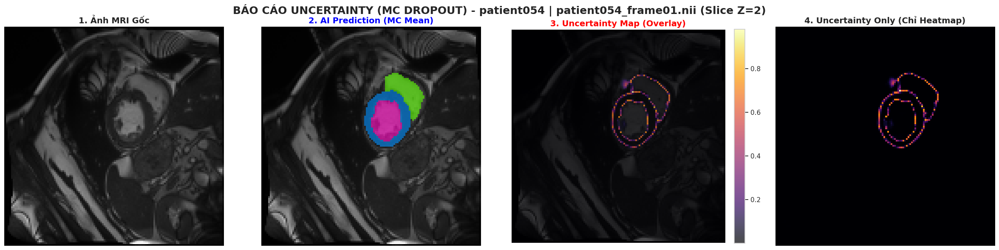

In [8]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random
from pathlib import Path

# ==============================================================================
# 1. HÀM TÍNH ĐỘ BẤT ĐỊNH (UNCERTAINTY BẰNG MC DROPOUT)
# ==============================================================================
def compute_uncertainty_mc_dropout(model, input_tensor, T=15):
    """
    Thực hiện Monte Carlo Dropout để ước lượng độ bất định.
    Input:
        - model: Mô hình SegResNet
        - input_tensor: Ảnh đầu vào (1, 1, D, H, W)
        - T: Số lần chạy lặp lại (sampling). T càng cao bản đồ càng mượt (thường 15-20).
    """
    # [QUAN TRỌNG] Kích hoạt chế độ Train để bật Dropout layer
    model.train() 
    
    outputs = []
    with torch.no_grad():
        for _ in range(T):
            # Forward pass
            logits = model(input_tensor)
            # Chuyển về xác suất (Probability)
            probs = torch.softmax(logits, dim=1)
            outputs.append(probs) # List các tensor (1, C, D, H, W)
            
    # Xếp chồng kết quả: (T, 1, C, D, H, W)
    outputs = torch.stack(outputs)
    
    # 1. Tính Mean Probability (Dự đoán trung bình của T lần chạy)
    mean_prob = torch.mean(outputs, dim=0) # (1, C, D, H, W)
    
    # 2. Tính Predictive Entropy (Độ bất định)
    # Công thức Shannon Entropy: H = - sum( p * log(p) )
    epsilon = 1e-6 # Tránh lỗi log(0)
    uncertainty_map = -torch.sum(mean_prob * torch.log(mean_prob + epsilon), dim=1)
    
    # [QUAN TRỌNG] Trả model về chế độ Eval để không ảnh hưởng các đoạn code khác
    model.eval()
    
    return mean_prob, uncertainty_map

# ==============================================================================
# 2. VISUALIZATION DASHBOARD (UNCERTAINTY XAI)
# ==============================================================================
def visualize_uncertainty_xai(model, items, device="cuda", num_samples=3):
    print(f"🚀 Đang tính toán Uncertainty Map (MC Dropout) cho {num_samples} mẫu...")
    
    # Load lại weight tốt nhất nếu cần thiết
    chk_path = SAVE_DIR / "best_model.pth"
    if not chk_path.exists():
        chk_path = Path("/kaggle/input/seg-khcrop/segresnet3d_final_results/best_model.pth")
    if chk_path.exists():
        model.load_state_dict(torch.load(chk_path, map_location=device))
        print(f"✅ Đã load weights từ: {chk_path}")
    
    # Chọn mẫu ngẫu nhiên từ tập Test
    indices = random.sample(range(len(items)), min(len(items), num_samples))

    for idx in indices:
        try:
            # Load data không augment
            ds = VolumeDataset([items[idx]], augment=False)
            sample = ds[0]
            
            img = sample["image"].unsqueeze(0).to(device) # (1, 1, D, H, W)
            label = sample["label"].numpy()
            
            # --- TÍNH UNCERTAINTY ---
            # Chạy MC Dropout 15 lần
            mean_prob, unc_map = compute_uncertainty_mc_dropout(model, img, T=15)
            
            # Lấy nhãn dự đoán từ mean_prob
            pred_mask = torch.argmax(mean_prob, dim=1).detach().cpu().numpy()[0]
            unc_map_np = unc_map.detach().cpu().numpy()[0] # (D, H, W)
            
            # --- TÌM SLICE ĐẸP NHẤT ---
            img_np = img.detach().cpu().numpy()[0, 0]
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else label.shape[2] // 2
            
            # Bóc tách tên Bệnh nhân & File
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name
            
            # --- VẼ HÌNH ---
            fig, axes = plt.subplots(1, 4, figsize=(24, 6))
            plt.suptitle(f"BÁO CÁO UNCERTAINTY (MC DROPOUT) - {p_name} | {f_name} (Slice Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: MRI Gốc
            axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
            axes[0].set_title("1. Ảnh MRI Gốc", fontsize=14, fontweight='bold')
            axes[0].axis('off')

            # Ô 2: Prediction (Mean)
            axes[1].imshow(img_np[:, :, slice_idx], cmap='gray')
            masked_pred = np.ma.masked_where(pred_mask[:, :, slice_idx] == 0, pred_mask[:, :, slice_idx])
            axes[1].imshow(masked_pred, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            axes[1].set_title("2. AI Prediction (MC Mean)", fontsize=14, fontweight='bold', color='blue')
            axes[1].axis('off')

            # Ô 3: Uncertainty Map (Entropy Heatmap Overlay) 
            axes[2].imshow(img_np[:, :, slice_idx], cmap='gray')
            im_unc = axes[2].imshow(unc_map_np[:, :, slice_idx], cmap='inferno', alpha=0.7) 
            axes[2].set_title("3. Uncertainty Map (Overlay)", fontsize=14, fontweight='bold', color='red')
            axes[2].axis('off')
            plt.colorbar(im_unc, ax=axes[2], fraction=0.046, pad=0.04)

            # Ô 4: Uncertainty Only (Zoom chi tiết)
            axes[3].imshow(unc_map_np[:, :, slice_idx], cmap='inferno')
            axes[3].set_title("4. Uncertainty Only (Chỉ Heatmap)", fontsize=14, fontweight='bold')
            axes[3].axis('off')

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

# --- GỌI HÀM ---
# Cứ truyền thẳng te_items vào đây, hàm tự động xử lý
visualize_uncertainty_xai(model, te_items, device=DEVICE, num_samples=3)

# unetpp

In [2]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from medpy.metric.binary import dc, jc, hd95
# [SỬA IMPORT] Load BasicUNetPlusPlus (U-Net++) từ MONAI
from monai.networks.nets import BasicUNetPlusPlus

# ---------------- 0. CONFIGURATION ----------------
BASE_DIR = Path("/kaggle/input/datasets/samdazel/automated-cardiac-diagnosis-challenge-miccai17/database")
TRAIN_DIR = BASE_DIR / "training"
TEST_DIR = BASE_DIR / "testing"

# Đổi tên thư mục lưu kết quả để không đè lên cái cũ
SAVE_DIR = Path("./unetplusplus3d_acdc_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 16)
NUM_CLASSES = 4
BATCH_SIZE = 2
EPOCHS = 100
LR = 1e-4
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, NUM_CLASSES).permute(0,4,1,2,3).float()
        dims = (0,2,3,4)
        inter = torch.sum(pred[:,1:] * target_oh[:,1:], dims)
        union = torch.sum(pred[:,1:] + target_oh[:,1:], dims)
        return 1 - ((2*inter + self.smooth) / (union + self.smooth)).mean()

# ---------------- 2. DATASET ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt  = nib.load(gt_p).get_fdata().astype(np.int64)

        zoom = (
            TARGET_SIZE[0] / img.shape[0],
            TARGET_SIZE[1] / img.shape[1],
            TARGET_SIZE[2] / img.shape[2]
        )
        img = ndi.zoom(img, zoom, order=1)
        gt  = ndi.zoom(gt,  zoom, order=0)

        if self.augment:
            if random.random() > 0.5:
                ax = random.randint(0,2)
                img = np.flip(img, ax).copy()
                gt  = np.flip(gt, ax).copy()

        img = (img - img.mean()) / (img.std() + 1e-6)

        return {
            "image": torch.from_numpy(img[None]).float(),
            "label": torch.from_numpy(gt).long()
        }

# ---------------- 3. METRICS ----------------
def get_metrics(p, g):
    res = {}
    for cl, name in zip([1,2,3], ['RV','MYO','LV']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0:
            res[name] = (0.0, 0.0, 50.0)
            continue
        res[name] = (
            dc(pc, gc),
            jc(pc, gc),
            hd95(pc, gc) if pc.sum()>0 else 50.0
        )
    return res

# ---------------- 4. GỘP DATA & CHIA TẦNG ----------------
patient_data = {}
for folder_dir in [TRAIN_DIR, TEST_DIR]:
    if not folder_dir.exists(): continue
    for p in sorted(folder_dir.iterdir()):
        if not p.is_dir() or not p.name.startswith("patient"): continue
        
        pid = p.name
        info_file = p / "Info.cfg"
        disease = "NOR" 
        
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if line.startswith("Group:"): 
                        disease = line.split(":")[1].strip()
        
        gt_nodes = list(p.glob("*_frame*_gt.nii*"))
        scans = []
        for gt_node in gt_nodes:
            img_node = gt_node.parent / gt_node.name.replace("_gt", "")
            if img_node.exists():
                scans.append((str(img_node), str(gt_node)))
                
        if scans:
            patient_data[pid] = {'disease': disease, 'scans': scans}

p_ids = list(patient_data.keys())
p_labels = [patient_data[pid]['disease'] for pid in p_ids]

train_ids, temp_ids, train_labels, temp_labels = train_test_split(
    p_ids, p_labels, test_size=70, random_state=SEED, stratify=p_labels
)
val_ids, test_ids, val_labels, test_labels = train_test_split(
    temp_ids, temp_labels, test_size=50, random_state=SEED, stratify=temp_labels
)

tr_items = [scan for pid in train_ids for scan in patient_data[pid]['scans']]
va_items = [scan for pid in val_ids for scan in patient_data[pid]['scans']]
te_items = [scan for pid in test_ids for scan in patient_data[pid]['scans']]

print(f"✅ Đã chia tầng xong: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
print(f"Tỉ lệ bệnh tập Test: {pd.Series(test_labels).value_counts().to_dict()}")

loaders = {
    "train": DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    "val":   DataLoader(VolumeDataset(va_items), 1)
}

print("-"*170)

# ---------------- 5. MODEL ----------------
# [SỬA TẠI ĐÂY] Khởi tạo mô hình UNet++ (BasicUNetPlusPlus)
model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    features=(16, 32, 64, 128, 256, 16), # Cấu hình số kênh (5 tầng encoder + 1 tầng upsample cuối)
    dropout=0.2
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, "max", patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler("cuda")

best_dice = 0.0

# ---------------- 6. CSV LOG ----------------
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, "w", newline="") as f:
    csv.writer(f).writerow([
        "epoch","tr_loss","va_loss","tr_dice",
        "va_dice","va_iou","va_hd95",
        "rv_d","myo_d","lv_d","time" 
    ])

# ---------------- 7. TRAINING LOOP ----------------
for ep in range(1, EPOCHS+1):
    t0 = time.time()
    model.train()
    tr_l, tr_d = [], []

    for b in tqdm(loaders["train"], desc=f"Epoch {ep:02d}", leave=False):
        img = b["image"].to(DEVICE)
        lab = b["label"].to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            out = model(img)
            
            # [BẢO MẬT TYPE] UNet++ có thể trả về tuple/list nếu bật deep supervision.
            # Lấy tensor cuối cùng để đồng bộ với cấu trúc Loss cũ.
            if isinstance(out, (list, tuple)):
                out = out[0] if len(out) == 1 else out[-1]
                
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_l.append(loss.item())
        tr_d.append(dc((out.argmax(1)>0).cpu().numpy(), (lab>0).cpu().numpy()))

    # ---------------- VALIDATION ----------------
    model.eval()
    va_l, acc = [], {"RV":[], "MYO":[], "LV":[]}

    with torch.no_grad():
        for b in loaders["val"]:
            img = b["image"].to(DEVICE)
            lab = b["label"].to(DEVICE)

            with torch.amp.autocast("cuda"):
                out = model(img)
                if isinstance(out, (list, tuple)):
                    out = out[0] if len(out) == 1 else out[-1]
                    
                loss = ce_criterion(out, lab) + dice_criterion(out, lab)
            
            va_l.append(loss.item())

            p = out.argmax(1).cpu().numpy()[0]
            g = lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for k in acc: acc[k].append(m[k])

    tr_loss = np.mean(tr_l)
    va_loss = np.mean(va_l)
    tr_dice = np.mean(tr_d)

    stats = {k: np.mean(acc[k],0) for k in acc}
    va_dice = np.mean([stats[k][0] for k in stats])
    va_iou  = np.mean([stats[k][1] for k in stats])
    va_hd95 = np.mean([stats[k][2] for k in stats])

    scheduler.step(va_dice)
    t_total = time.time() - t0

    print(
        f"Ep {ep:02d} | {t_total:5.1f}s | "
        f"Tr.Loss {tr_loss:.4f} | Va.Loss {va_loss:.4f} | "
        f"Tr.Dice {tr_dice:.4f} | Va.Dice {va_dice:.4f} | "
        f"IoU {va_iou:.4f} | HD95 {va_hd95:.2f}"
    )

    with open(CSV_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            ep, tr_loss, va_loss, tr_dice,
            va_dice, va_iou, va_hd95,
            stats["RV"][0], stats["MYO"][0], stats["LV"][0], t_total
        ])

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), SAVE_DIR/"best_model.pth")
        print(f"New Best Model Saved | Dice {best_dice:.4f}")

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
2026-06-04 02:31:15.603640: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780540275.814864      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780540275.876237      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780540276.364638      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780540276.364683      57 computation_placer.cc:1

✅ Đã chia tầng xong: Train 80 BN | Val 20 BN | Test 50 BN
Tỉ lệ bệnh tập Test: {'MINF': 10, 'DCM': 10, 'NOR': 10, 'RV': 10, 'HCM': 10}
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).


Ep 01 |  39.5s | Tr.Loss 2.3676 | Va.Loss 2.1926 | Tr.Dice 0.1113 | Va.Dice 0.0684 | IoU 0.0365 | HD95 48.49
New Best Model Saved | Dice 0.0684


Ep 02 |  29.9s | Tr.Loss 2.1737 | Va.Loss 2.1001 | Tr.Dice 0.1361 | Va.Dice 0.0425 | IoU 0.0221 | HD95 48.82


Ep 03 |  29.3s | Tr.Loss 2.0862 | Va.Loss 2.0161 | Tr.Dice 0.1625 | Va.Dice 0.0676 | IoU 0.0360 | HD95 48.32


Ep 04 |  27.2s | Tr.Loss 1.9983 | Va.Loss 1.9351 | Tr.Dice 0.2169 | Va.Dice 0.1562 | IoU 0.0914 | HD95 54.13
New Best Model Saved | Dice 0.1562


... (92 outputs left out)

Ep 97 |  28.5s | Tr.Loss 0.1747 | Va.Loss 0.1644 | Tr.Dice 0.9346 | Va.Dice 0.8711 | IoU 0.7773 | HD95 1.30
New Best Model Saved | Dice 0.8711


Ep 98 |  28.2s | Tr.Loss 0.1713 | Va.Loss 0.1662 | Tr.Dice 0.9371 | Va.Dice 0.8692 | IoU 0.7750 | HD95 1.30


Ep 99 |  28.2s | Tr.Loss 0.1683 | Va.Loss 0.1659 | Tr.Dice 0.9388 | Va.Dice 0.8702 | IoU 0.7763 | HD95 1.33


Ep 100 |  28.3s | Tr.Loss 0.1682 | Va.Loss 0.1635 | Tr.Dice 0.9378 | Va.Dice 0.8718 | IoU 0.7784 | HD95 1.36
New Best Model Saved | Dice 0.8718


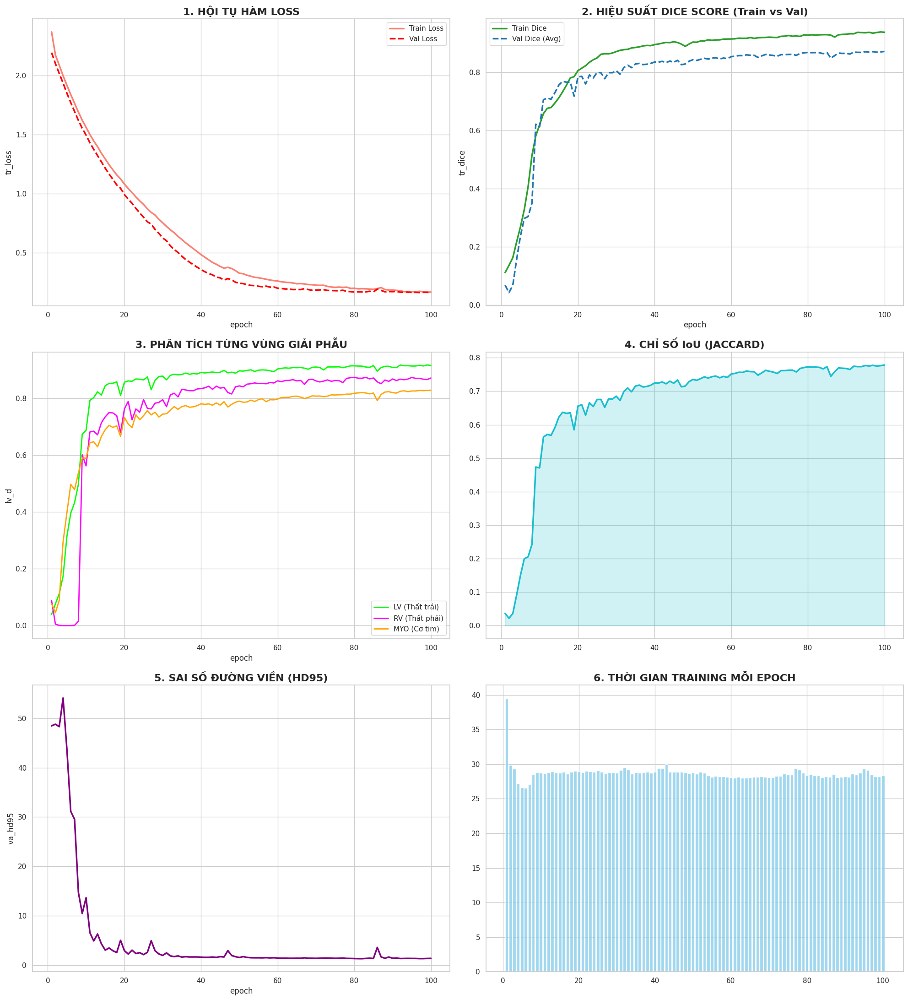


             BÁO CÁO KẾT QUẢ MÔ HÌNH U-NET++ 3D             
🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: 100
  > Dice Score (Avg)          :     0.8718
  > IoU (Jaccard)             :     0.7784
  > HD95                      :    1.36 mm
  > Dice - LV                 :     0.9157
  > Dice - RV                 :     0.8713
  > Dice - MYO                :     0.8285


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đảm bảo đường dẫn trỏ đúng vào thư mục của U-Net++
SAVE_DIR = Path("./unetplusplus3d_acdc_results")
CSV_PATH = SAVE_DIR / "training_log.csv"

# ================= 8. DASHBOARD & REPORT =================
def plot_dashboard_matched(log_path):
    if not log_path.exists():
        print(f"❌ Lỗi: Không tìm thấy file log tại {log_path}. Bạn đã train xong chưa?")
        return

    df = pd.read_csv(log_path)
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 2, figsize=(20, 22))
    plt.subplots_adjust(hspace=0.35, wspace=0.2)

    # --- BIỂU ĐỒ 1: LOSS ---
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='tr_loss', label='Train Loss', color='salmon', linewidth=2.5)
    sns.lineplot(ax=axes[0, 0], data=df, x='epoch', y='va_loss', label='Val Loss', color='red', linewidth=2.5, linestyle='--')
    axes[0, 0].set_title('1. HỘI TỤ HÀM LOSS', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 2: DICE TỔNG QUÁT ---
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='tr_dice', label='Train Dice', color='#2ca02c', linewidth=2.5)
    sns.lineplot(ax=axes[0, 1], data=df, x='epoch', y='va_dice', label='Val Dice (Avg)', color='#1f77b4', linewidth=2.5, linestyle='--')
    axes[0, 1].set_title('2. HIỆU SUẤT DICE SCORE (Train vs Val)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 3: DICE CHI TIẾT ---
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='lv_d', label='LV (Thất trái)', color='lime', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='rv_d', label='RV (Thất phải)', color='magenta', linewidth=2)
    sns.lineplot(ax=axes[1, 0], data=df, x='epoch', y='myo_d', label='MYO (Cơ tim)', color='orange', linewidth=2)
    axes[1, 0].set_title('3. PHÂN TÍCH TỪNG VÙNG GIẢI PHẪU', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 4: IoU ---
    axes[1, 1].fill_between(df['epoch'], df['va_iou'], color='#17becf', alpha=0.2)
    axes[1, 1].plot(df['epoch'], df['va_iou'], color='#17becf', linewidth=2.5, label='Mean IoU')
    axes[1, 1].set_title('4. CHỈ SỐ IoU (JACCARD)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 5: HD95 ---
    sns.lineplot(ax=axes[2, 0], data=df, x='epoch', y='va_hd95', color='purple', linewidth=2.5)
    axes[2, 0].set_title('5. SAI SỐ ĐƯỜNG VIỀN (HD95)', fontsize=16, fontweight='bold')

    # --- BIỂU ĐỒ 6: THỜI GIAN ---
    axes[2, 1].bar(df['epoch'], df['time'], color='skyblue', alpha=0.8)
    axes[2, 1].set_title('6. THỜI GIAN TRAINING MỖI EPOCH', fontsize=16, fontweight='bold')

    plt.tight_layout()
    plt.savefig(SAVE_DIR / "final_dashboard.png", dpi=300)
    plt.show()

def print_report_matched(log_path):
    if not log_path.exists(): return
    df = pd.read_csv(log_path)
    best_row = df.iloc[df['va_dice'].idxmax()]
    
    print("\n" + "="*60)
    print(f"{'BÁO CÁO KẾT QUẢ MÔ HÌNH U-NET++ 3D':^60}")
    print("="*60)
    print(f"🏆 KẾT QUẢ TỐT NHẤT TẠI EPOCH: {int(best_row['epoch'])}")
    for l, v in [["Dice Score (Avg)", f"{best_row['va_dice']:.4f}"], ["IoU (Jaccard)", f"{best_row['va_iou']:.4f}"], 
                 ["HD95", f"{best_row['va_hd95']:.2f} mm"], ["Dice - LV", f"{best_row['lv_d']:.4f}"], 
                 ["Dice - RV", f"{best_row['rv_d']:.4f}"], ["Dice - MYO", f"{best_row['myo_d']:.4f}"]]:
        print(f"  > {l:<25} : {v:>10}")
    print("="*60)

# Thực thi vẽ biểu đồ sau khi train xong
plot_dashboard_matched(CSV_PATH)
print_report_matched(CSV_PATH)

In [4]:
# ==============================================================================
# 🏆 ĐÁNH GIÁ TRÊN TẬP TEST (U-NET++)
# ==============================================================================
print("\n" + "=" * 80)
print("🏆 BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST (50 BỆNH NHÂN) - U-NET++")
print("=" * 80)

# 1. Tải trọng số mô hình tốt nhất
BEST_MODEL_PATH = SAVE_DIR / "best_model.pth"
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file {BEST_MODEL_PATH}. Vui lòng kiểm tra lại quá trình train.")

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()
print(f"[*] Đã tải thành công mô hình từ: {BEST_MODEL_PATH}")

# 2. Tạo DataLoader cho tập Test (Dùng te_items đã chia ở trên)
test_dataset = VolumeDataset(te_items, augment=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# 3. Khởi tạo biến lưu trữ kết quả
test_metrics = {"RV": [], "MYO": [], "LV": []}
total_inference_time = 0.0

# 4. Vòng lặp Inference
with torch.no_grad():
    for i, batch in enumerate(tqdm(test_loader, desc="Đang xử lý tập Test")):
        img = batch["image"].to(DEVICE)
        gt = batch["label"].to(DEVICE)
        
        # Đo thời gian dự đoán
        start_time = time.time()
        with torch.amp.autocast("cuda"):
            out = model(img)
            
            # [QUAN TRỌNG] Xử lý output của U-Net++ (có thể là tuple/list)
            if isinstance(out, (list, tuple)):
                out = out[0] if len(out) == 1 else out[-1]
                
            pred = out.argmax(dim=1) # Lấy class có xác suất cao nhất
            
        total_inference_time += (time.time() - start_time)
        
        # Chuyển tensor về numpy array để tính toán với medpy
        p_np = pred.cpu().numpy()[0]
        g_np = gt.cpu().numpy()[0]
        
        # Sử dụng hàm get_metrics đã định nghĩa ở phần trước
        m = get_metrics(p_np, g_np)
        
        # Lưu kết quả
        for k in test_metrics:
            test_metrics[k].append(m[k])

# 5. Tổng hợp và in kết quả
print("\n📊 KẾT QUẢ ĐÁNH GIÁ TỔNG HỢP (U-NET++ TRÊN TẬP TEST):")
print("-" * 60)
print(f"{'Cấu trúc':<10} | {'Dice':<10} | {'IoU':<10} | {'HD95 (mm)':<10}")
print("-" * 60)

final_stats = {k: np.mean(test_metrics[k], axis=0) for k in test_metrics}

# In chi tiết từng class
for cl_name in ["RV", "MYO", "LV"]:
    dice_val = final_stats[cl_name][0]
    iou_val = final_stats[cl_name][1]
    hd95_val = final_stats[cl_name][2]
    print(f"{cl_name:<10} | {dice_val:.4f}   | {iou_val:.4f}   | {hd95_val:.4f}")

print("-" * 60)
# In Trung bình toàn bộ (Macro-average)
mean_dice = np.mean([final_stats[k][0] for k in final_stats])
mean_iou  = np.mean([final_stats[k][1] for k in final_stats])
mean_hd95 = np.mean([final_stats[k][2] for k in final_stats])

print(f"{'Trung bình':<10} | {mean_dice:.4f}   | {mean_iou:.4f}   | {mean_hd95:.4f}")
print("=" * 60)

avg_time_per_scan = (total_inference_time / len(test_loader)) * 1000
print(f"⏱️ Thời gian dự đoán trung bình: {avg_time_per_scan:.2f} ms / scan 3D")


🏆 BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST (50 BỆNH NHÂN) - U-NET++
[*] Đã tải thành công mô hình từ: unetplusplus3d_acdc_results/best_model.pth


Đang xử lý tập Test: 100%|██████████| 100/100 [00:30<00:00,  3.33it/s]


📊 KẾT QUẢ ĐÁNH GIÁ TỔNG HỢP (U-NET++ TRÊN TẬP TEST):
------------------------------------------------------------
Cấu trúc   | Dice       | IoU        | HD95 (mm) 
------------------------------------------------------------
RV         | 0.8587   | 0.7607   | 1.5922
MYO        | 0.8342   | 0.7191   | 1.1631
LV         | 0.9120   | 0.8433   | 1.2809
------------------------------------------------------------
Trung bình | 0.8683   | 0.7744   | 1.3454
⏱️ Thời gian dự đoán trung bình: 14.87 ms / scan 3D


🚀 Đang khởi tạo XAI Dashboard (Bản nguyên gốc) cho 6 mẫu...


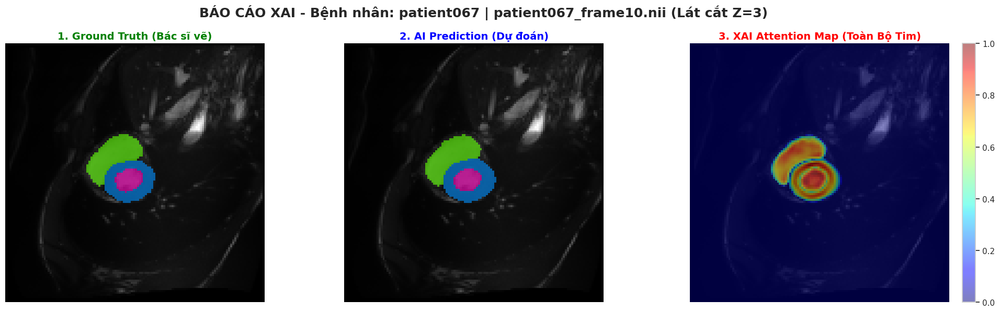

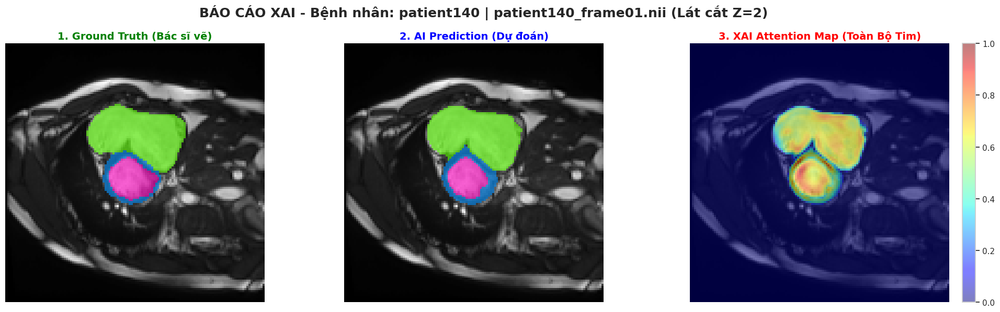

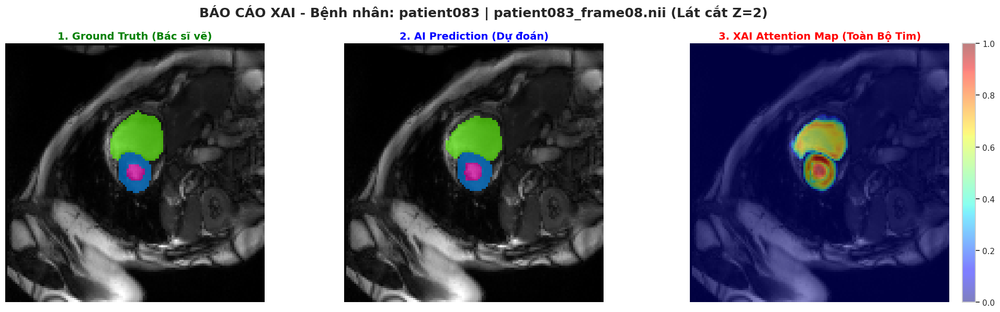

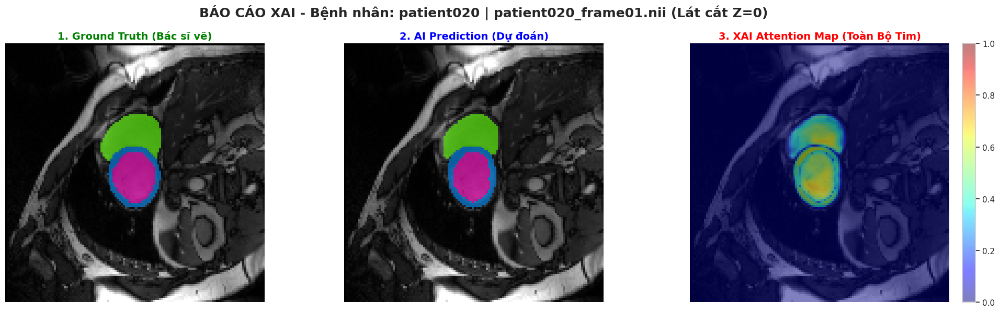

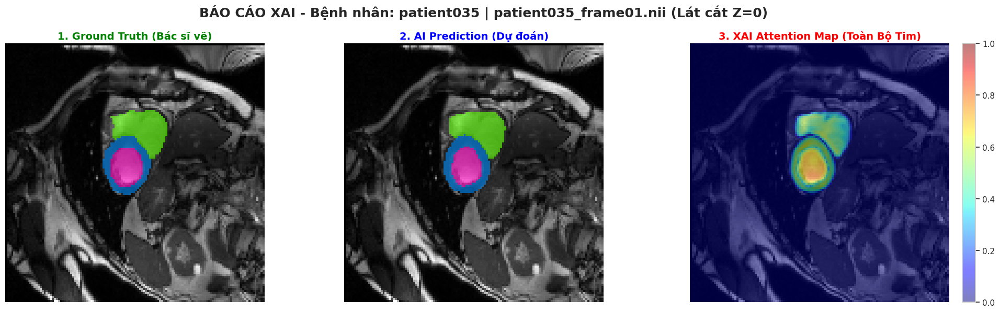

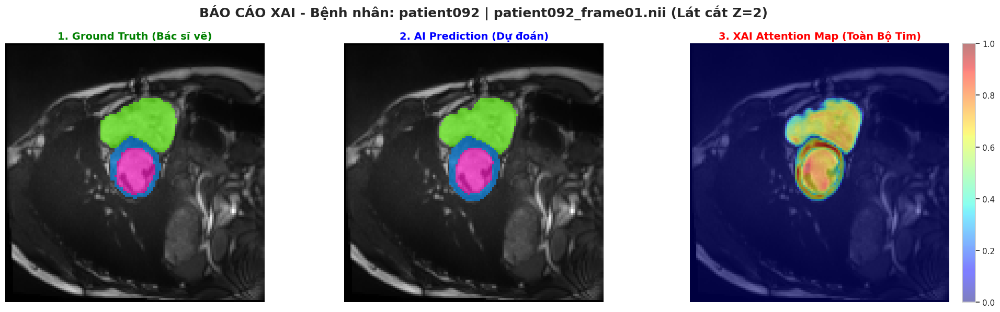

✅ Hoàn tất quá trình trích xuất XAI Dashboard!


In [17]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import random
from pathlib import Path

# ==============================================================================
# 1. CLASS GRAD-CAM 3D (GIỮ NGUYÊN BẢN CODE GỐC CỦA BẠN 100%)
# ==============================================================================
class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.handles = []
        
        # Đăng ký hook để "nghe lén" dữ liệu khi chạy qua layer này
        self.handles.append(self.target_layer.register_forward_hook(self.save_activation))
        self.handles.append(self.target_layer.register_full_backward_hook(self.save_gradient))

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        """Quan trọng: Gỡ bỏ hook để giải phóng bộ nhớ"""
        for handle in self.handles:
            handle.remove()

    def generate_heatmap(self, input_tensor, class_idx):
        # Reset gradient cũ
        self.model.zero_grad()
        
        # 1. Forward Pass
        output = self.model(input_tensor)
        
        # [SỬA NHẸ DUY NHẤT] Hỗ trợ U-Net++ trả về Tuple khi bật Deep Supervision
        if isinstance(output, (list, tuple)): 
            output = output[0] if len(output) == 1 else output[-1]
            
        # 2. Backward Pass: Chỉ quan tâm đến Class đích (class_idx)
        score = output[0, class_idx].sum()
        score.backward() 

        # Đề phòng hook lỗi (Bảo vệ chống màn hình xanh)
        if self.gradients is None or self.activations is None:
            return np.zeros(input_tensor.shape[2:], dtype=np.float32)

        # 3. Tạo CAM
        weights = torch.mean(self.gradients, dim=(2, 3, 4), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).detach().cpu().numpy()
        
        # Chuẩn hóa về [0, 1]
        if cam.max() - cam.min() > 0:
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        
        return cam

# ==============================================================================
# 2. DASHBOARD VISUALIZATION FUNCTION (TÍCH HỢP CHO U-NET++)
# ==============================================================================
def visualize_xai_prediction_dashboard(model, items, device="cuda", num_samples=6):
    print(f"🚀 Đang khởi tạo XAI Dashboard (Bản nguyên gốc) cho {num_samples} mẫu...")
    model.eval()
    
    # --- A. TỰ ĐỘNG TÌM TARGET LAYER CHO U-NET++ ---
    # Thay vì lấy bừa Conv3D cuối cùng, ta lấy LỚP TÍCH CHẬP CHÍNH (conv.conv) 
    # của tầng giải mã cuối cùng. Lớp này chứa lượng ngữ nghĩa dồi dào và đẹp nhất.
    decoder_blocks = [m for name, m in model.named_modules() if 'up_convs' in name or 'up_layers' in name or ('out' not in name and len(name) > 10 and isinstance(m, torch.nn.Conv3d))]
    if not decoder_blocks:
        conv_layers = [m for m in model.modules() if isinstance(m, torch.nn.Conv3d)]
        target_layer = conv_layers[-4] if len(conv_layers) >= 4 else conv_layers[-1]
    else:
        target_layer = decoder_blocks[-1]
    
    # Khởi tạo công cụ Grad-CAM
    cam_extractor = GradCAM3D(model, target_layer)
    
    # Load dataset test (Tắt augment để giữ nguyên gốc ảnh)
    dataset = VolumeDataset(items, augment=False) 
    
    # Chọn mẫu ngẫu nhiên
    sample_indices = random.sample(range(len(items)), min(len(items), num_samples))

    # --- B. VÒNG LẶP XỬ LÝ TỪNG MẪU ---
    for idx in sample_indices:
        try:
            data = dataset[idx]
            
            # Input cần require grad để tính ngược
            img = data['image'].unsqueeze(0).to(device)
            img.requires_grad = True 
            
            label = data['label'].numpy() # Shape: (128, 128, 16)
            
            # 1. Chạy dự đoán (Prediction)
            with torch.no_grad(): # Tắt grad khúc này để tiết kiệm VRAM
                out = model(img)
                if isinstance(out, (list, tuple)): out = out[0] if len(out) == 1 else out[-1]
                pred = torch.argmax(out, 1).detach().cpu().numpy()[0]

            # 2. Tính Grad-CAM tổng hợp (Gộp Heatmap của LV, MYO, RV)
            combined_heatmap = np.zeros_like(label, dtype=np.float32)
            
            # Duyệt qua 3 lớp tim: 1(RV), 2(MYO), 3(LV)
            for c in [1, 2, 3]: 
                try:
                    # Tạo heatmap thô (kích thước nhỏ)
                    h_small = cam_extractor.generate_heatmap(img, class_idx=c)
                    
                    # Tính tỷ lệ phóng to để khớp với ảnh gốc
                    zoom_factor = (
                        label.shape[0] / h_small.shape[0],
                        label.shape[1] / h_small.shape[1],
                        label.shape[2] / h_small.shape[2]
                    )
                    
                    # Phóng to heatmap (Zoom)
                    h_large = zoom(h_small, zoom_factor, order=1)
                    
                    # Cộng dồn vào bản đồ nhiệt tổng (Lấy max để giữ điểm nóng nhất)
                    combined_heatmap = np.maximum(combined_heatmap, h_large)
                except Exception:
                    continue

            # Tái chuẩn hóa tổng hợp để màu sắc lên max đỉnh
            if combined_heatmap.max() > 0:
                combined_heatmap /= combined_heatmap.max()

            # 3. Chọn lát cắt (Slice) hiển thị
            img_np = img.detach().cpu().numpy()[0, 0]
            
            # Tìm lát cắt có diện tích tim lớn nhất
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else (label.shape[2] // 2)
            
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name

            # --- C. VẼ ĐỒ THỊ ---
            plt.figure(figsize=(20, 6))
            plt.suptitle(f"BÁO CÁO XAI - Bệnh nhân: {p_name} | {f_name} (Lát cắt Z={slice_idx})", fontsize=18, fontweight='bold')
            
            # Ô 1: Ground Truth
            plt.subplot(1, 3, 1)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            # Masked array để ẩn phần nền (class 0)
            gt_masked = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
            plt.imshow(gt_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("1. Ground Truth (Bác sĩ vẽ)", fontsize=14, color='green', fontweight='bold')
            plt.axis('off')

            # Ô 2: Prediction
            plt.subplot(1, 3, 2)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            pred_masked = np.ma.masked_where(pred[:, :, slice_idx] == 0, pred[:, :, slice_idx])
            plt.imshow(pred_masked, cmap='gist_rainbow', alpha=0.6, vmin=0, vmax=3)
            plt.title("2. AI Prediction (Dự đoán)", fontsize=14, color='blue', fontweight='bold')
            plt.axis('off')

            # Ô 3: XAI Attention Map (Grad-CAM) 
            plt.subplot(1, 3, 3)
            plt.imshow(img_np[:, :, slice_idx], cmap='gray')
            
            # Ép chặt biên độ nhiệt về vmin=0, vmax=1 để dẹp sạch sương mù và lỗi màn hình xanh!
            im = plt.imshow(combined_heatmap[:, :, slice_idx], cmap='jet', alpha=0.5, vmin=0, vmax=1)
            
            plt.title("3. XAI Attention Map (Toàn Bộ Tim)", fontsize=14, color='red', fontweight='bold')
            plt.axis('off')
            plt.colorbar(im, fraction=0.046, pad=0.04)

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

    # Dọn dẹp Hook cuối cùng
    cam_extractor.remove_hooks()
    print("✅ Hoàn tất quá trình trích xuất XAI Dashboard!")

# ==============================================================================
# 3. RUN (GỌI HÀM)
# ==============================================================================
visualize_xai_prediction_dashboard(model, te_items, device=DEVICE, num_samples=6)

BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).

🚀 Đang khởi tạo Layer-wise Visualization...
Tổng số Conv3D layers: 34
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)


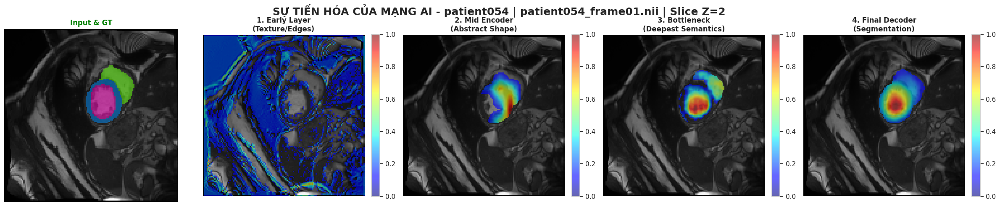

🚀 Đang khởi tạo Layer-wise Visualization...
Tổng số Conv3D layers: 34
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)


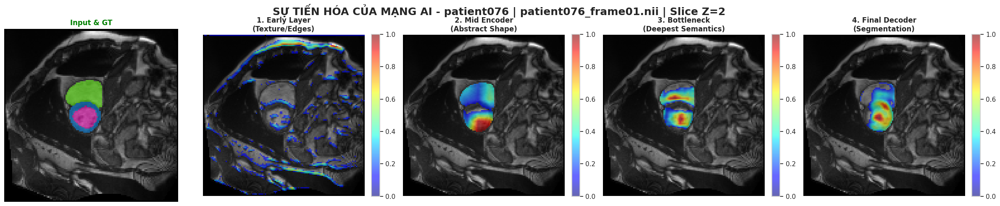

🚀 Đang khởi tạo Layer-wise Visualization...
Tổng số Conv3D layers: 34
  >> Đang phân tích tầng: 1. Early Layer (Texture/Edges)
  >> Đang phân tích tầng: 2. Mid Encoder (Abstract Shape)
  >> Đang phân tích tầng: 3. Bottleneck (Deepest Semantics)
  >> Đang phân tích tầng: 4. Final Decoder (Segmentation)


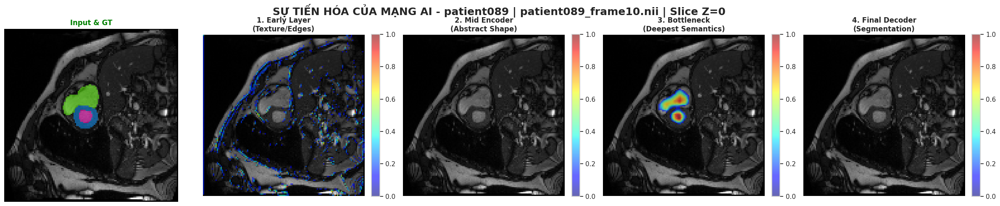

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import random
from scipy.ndimage import zoom
from pathlib import Path


# =========================================================
# CUSTOM GRADCAM 3D CHO UNET++ ACDC
# score = toàn bộ vùng tim: RV + MYO + LV
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, inp, out):
        self.activations = out.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, x):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        out = self.model(x)

        if isinstance(out, (list, tuple)):
            out = out[0] if len(out) == 1 else out[-1]

        # ACDC: 1=RV, 2=MYO, 3=LV
        score = out[:, 1:].sum()
        score.backward(retain_graph=True)

        if self.gradients is None or self.activations is None:
            raise RuntimeError("Không lấy được gradient ở layer này.")

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        return cam


# =========================================================
# VISUALIZE LAYER EVOLUTION - UNET++ ACDC
# =========================================================

def visualize_layer_evolution_unetpp_acdc(
    model,
    items,
    device="cuda",
    sample_idx=None
):
    print("🚀 Đang khởi tạo Layer-wise Visualization...")

    model.eval()

    conv_layers = [
        m for m in model.modules()
        if isinstance(m, torch.nn.Conv3d)
    ]

    print(f"Tổng số Conv3D layers: {len(conv_layers)}")

    candidate_layers = [
        m for m in conv_layers
        if not (
            m.out_channels == NUM_CLASSES or
            m.kernel_size == (1, 1, 1)
        )
    ]

    if len(candidate_layers) < 8:
        candidate_layers = conv_layers

    n = len(candidate_layers)

    target_layers = {
        "1. Early Layer\n(Texture/Edges)": candidate_layers[0],
        "2. Mid Encoder\n(Abstract Shape)": candidate_layers[min(6, n - 1)],
        "3. Bottleneck\n(Deepest Semantics)": candidate_layers[min(12, n - 1)],
        "4. Final Decoder\n(Segmentation)": candidate_layers[-4] if n >= 4 else candidate_layers[-1],
    }

    if sample_idx is None:
        sample_idx = random.randint(0, len(items) - 1)

    ds = VolumeDataset(
        [items[sample_idx]],
        augment=False
    )

    data = ds[0]

    img = data["image"].unsqueeze(0).to(device).float()
    img.requires_grad_(True)

    label = data["label"].numpy()

    p_name = Path(items[sample_idx][0]).parent.name
    f_name = Path(items[sample_idx][0]).name

    img_np = img.detach().cpu().numpy()[0, 0]

    sums = np.sum(label > 0, axis=(0, 1))

    if np.max(sums) > 0:
        slice_idx = int(np.argmax(sums))
    else:
        slice_idx = label.shape[2] // 2

    heart_mask_3d = (label > 0).astype(np.float32)
    heart_mask_slice = heart_mask_3d[:, :, slice_idx]

    fig, axes = plt.subplots(
        1,
        len(target_layers) + 1,
        figsize=(24, 5)
    )

    fig.suptitle(
        f"SỰ TIẾN HÓA CỦA MẠNG AI - {p_name} | {f_name} | Slice Z={slice_idx}",
        fontsize=18,
        fontweight="bold"
    )

    # =====================================================
    # INPUT + GT
    # =====================================================

    axes[0].imshow(
        img_np[:, :, slice_idx],
        cmap="gray"
    )

    gt_mask = np.ma.masked_where(
        label[:, :, slice_idx] == 0,
        label[:, :, slice_idx]
    )

    axes[0].imshow(
        gt_mask,
        cmap="gist_rainbow",
        alpha=0.5,
        vmin=0,
        vmax=3
    )

    axes[0].set_title(
        "Input & GT",
        fontweight="bold",
        color="green"
    )

    axes[0].axis("off")

    # =====================================================
    # LAYER-WISE CAM
    # =====================================================

    for i, (layer_name, layer_module) in enumerate(target_layers.items()):

        print(f"  >> Đang phân tích tầng: {layer_name.replace(chr(10), ' ')}")

        cam_extractor = None
        heat_large = np.zeros_like(label, dtype=np.float32)

        try:
            cam_extractor = GradCAM3D(
                model=model,
                target_layer=layer_module
            )

            img_grad = img.clone().detach().requires_grad_(True)

            h_small = cam_extractor.generate_heatmap(
                img_grad
            )

            zoom_factor = (
                label.shape[0] / h_small.shape[0],
                label.shape[1] / h_small.shape[1],
                label.shape[2] / h_small.shape[2],
            )

            heat_large = zoom(
                h_small,
                zoom_factor,
                order=1
            )

            if heat_large.max() > 0:
                heat_large = heat_large / heat_large.max()

        except Exception as e:
            print(f"  ❌ Lỗi layer {layer_name}: {e}")

        finally:
            if cam_extractor is not None:
                try:
                    cam_extractor.remove_hooks()
                except:
                    pass

        ax = axes[i + 1]

        ax.imshow(
            img_np[:, :, slice_idx],
            cmap="gray"
        )

        heat_slice = heat_large[:, :, slice_idx]

        # =================================================
        # QUAN TRỌNG: lọc vùng chú ý trong vùng tim GT
        # tránh bị cháy nền ngoài tim
        # =================================================

        if i >= 1:
            heat_slice = heat_slice * heart_mask_slice

        if heat_slice.max() > 0:
            heat_slice = heat_slice / heat_slice.max()

        heat_masked = np.ma.masked_where(
            heat_slice < 0.10,
            heat_slice
        )

        im = ax.imshow(
            heat_masked,
            cmap="jet",
            alpha=0.6,
            vmin=0,
            vmax=1
        )

        ax.set_title(
            layer_name,
            fontweight="bold"
        )

        ax.axis("off")

        plt.colorbar(
            im,
            ax=ax,
            fraction=0.046,
            pad=0.04
        )

    plt.tight_layout()
    plt.show()


# =========================================================
# LOAD BEST MODEL
# =========================================================

model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    features=(16, 32, 64, 128, 256, 16),
    dropout=0.2,
).to(DEVICE)

model.load_state_dict(
    torch.load(
        SAVE_DIR / "best_model.pth",
        map_location=DEVICE
    )
)

model.eval()


# =========================================================
# CHẠY THỬ 3 MẪU TEST
# =========================================================

print("\n" + "=" * 50)

for _ in range(3):
    visualize_layer_evolution_unetpp_acdc(
        model=model,
        items=te_items,
        device=DEVICE
    )

🚀 Đang visualize 1 bệnh nhân: index 38
>> Đang phân tích tầng 1. Init
Lỗi layer 1. Init: CUDA out of memory. Tried to allocate 16.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 9.81 MiB is free. Including non-PyTorch memory, this process has 14.55 GiB memory in use. Of the allocated memory 14.39 GiB is allocated by PyTorch, and 31.42 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)
>> Đang phân tích tầng 2. Enc L0
Lỗi layer 2. Enc L0: CUDA out of memory. Tried to allocate 16.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 9.81 MiB is free. Including non-PyTorch memory, this process has 14.55 GiB memory in use. Of the allocated memory 14.39 GiB is allocated by PyTorch, and 30.42 MiB is reserved by PyTorch but unallocated. If reserved but u

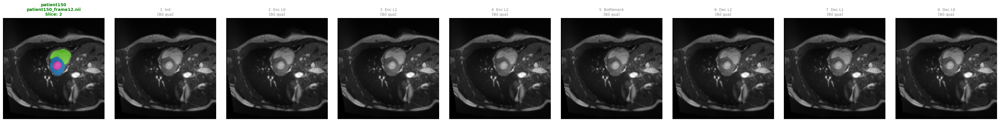

In [30]:
# =========================================================
# UNET++ ACDC - 8 LAYER GRAD-CAM
# FIX CUDA OUT OF MEMORY
# Chạy 1 bệnh nhân/lần, xóa cache sau từng layer
# =========================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import random
import gc
from scipy.ndimage import zoom
from pathlib import Path


# =========================================================
# CLEAR MEMORY
# =========================================================

def clear_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


clear_memory()


# =========================================================
# GRADCAM 3D
# =========================================================

class GradCAM3D:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self.handle = self.target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, inp, out):
        self.activations = out.clone()

        if self.activations.requires_grad:
            self.activations.register_hook(self.save_gradient)

        return self.activations

    def save_gradient(self, grad):
        self.gradients = grad.clone()

    def remove_hooks(self):
        self.handle.remove()

    def generate_heatmap(self, input_tensor):
        self.model.zero_grad(set_to_none=True)
        self.gradients = None
        self.activations = None

        output = self.model(input_tensor)

        if isinstance(output, (list, tuple)):
            output = output[0] if len(output) == 1 else output[-1]

        score = output[:, 1:].sum()
        score.backward()

        if self.gradients is None or self.activations is None:
            return None

        weights = torch.mean(
            self.gradients,
            dim=(2, 3, 4),
            keepdim=True
        )

        cam = torch.sum(
            weights * self.activations,
            dim=1
        ).squeeze(0)

        cam = F.relu(cam).detach().cpu().numpy()

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        del output, score, weights
        clear_memory()

        return cam


# =========================================================
# GET 8 LAYERS
# =========================================================

def get_unetplusplus_8_layers(model):
    conv_layers = [
        m for m in model.modules()
        if isinstance(m, torch.nn.Conv3d)
    ]

    candidate_layers = [
        m for m in conv_layers
        if not (
            m.out_channels == NUM_CLASSES
            or m.kernel_size == (1, 1, 1)
        )
    ]

    if len(candidate_layers) < 8:
        candidate_layers = conv_layers

    n = len(candidate_layers)

    idxs = [
        0,
        min(3, n - 1),
        min(6, n - 1),
        min(9, n - 1),
        min(12, n - 1),
        min(15, n - 1),
        min(18, n - 1),
        n - 1
    ]

    return {
        "1. Init": candidate_layers[idxs[0]],
        "2. Enc L0": candidate_layers[idxs[1]],
        "3. Enc L1": candidate_layers[idxs[2]],
        "4. Enc L2": candidate_layers[idxs[3]],
        "5. Bottleneck": candidate_layers[idxs[4]],
        "6. Dec L2": candidate_layers[idxs[5]],
        "7. Dec L1": candidate_layers[idxs[6]],
        "8. Dec L0": candidate_layers[idxs[7]],
    }


# =========================================================
# VISUALIZE 1 PATIENT ONLY
# =========================================================

def visualize_single_patient_8layers_safe(
    model,
    item,
    device,
    patient_idx,
):
    clear_memory()

    model.eval()

    target_layers = get_unetplusplus_8_layers(model)

    ds = VolumeDataset([item], augment=False)
    data = ds[0]

    img = data["image"].unsqueeze(0).to(device).float()
    label = data["label"].numpy()

    img_np = img.detach().cpu().numpy()[0, 0]

    sums = np.sum(label > 0, axis=(0, 1))

    if np.max(sums) > 0:
        slice_idx = int(np.argmax(sums))
    else:
        slice_idx = label.shape[2] // 2

    heart_mask_slice = (label[:, :, slice_idx] > 0).astype(np.float32)

    try:
        p_name = Path(item[0]).parent.name
        f_name = Path(item[0]).name
        title_text = f"{p_name}\n{f_name}\nSlice: {slice_idx}"
    except:
        title_text = f"Patient {patient_idx}\nSlice {slice_idx}"

    fig, axes = plt.subplots(
        1,
        len(target_layers) + 1,
        figsize=(34, 4)
    )

    axes[0].imshow(
        img_np[:, :, slice_idx],
        cmap="gray"
    )

    gt_mask = np.ma.masked_where(
        label[:, :, slice_idx] == 0,
        label[:, :, slice_idx]
    )

    axes[0].imshow(
        gt_mask,
        cmap="gist_rainbow",
        alpha=0.5,
        vmin=0,
        vmax=3
    )

    axes[0].set_title(
        title_text,
        fontweight="bold",
        color="green",
        fontsize=10
    )

    axes[0].axis("off")

    for i, (layer_name, layer_module) in enumerate(target_layers.items()):

        print(f">> Đang phân tích tầng {layer_name}")

        ax = axes[i + 1]
        cam_extractor = None

        try:
            clear_memory()

            cam_extractor = GradCAM3D(
                model=model,
                target_layer=layer_module
            )

            img_grad = img.clone().detach().requires_grad_(True)

            h_small = cam_extractor.generate_heatmap(
                img_grad
            )

            cam_extractor.remove_hooks()

            del img_grad
            clear_memory()

            if h_small is None:
                raise RuntimeError("Không lấy được heatmap.")

            z_factor = (
                label.shape[0] / h_small.shape[0],
                label.shape[1] / h_small.shape[1],
                label.shape[2] / h_small.shape[2],
            )

            h_large = zoom(
                h_small,
                z_factor,
                order=1
            )

            del h_small
            clear_memory()

            if h_large.max() > 0:
                h_large = h_large / h_large.max()

            heat_slice = h_large[:, :, slice_idx]

            if i >= 2:
                heat_slice = heat_slice * heart_mask_slice

            if heat_slice.max() > 0:
                heat_slice = heat_slice / heat_slice.max()

            threshold = 0.08 if i <= 1 else 0.12

            heat_masked = np.ma.masked_where(
                heat_slice < threshold,
                heat_slice
            )

            ax.imshow(
                img_np[:, :, slice_idx],
                cmap="gray"
            )

            ax.imshow(
                heat_masked,
                cmap="jet",
                alpha=0.55,
                vmin=0,
                vmax=1
            )

            ax.set_title(
                layer_name,
                fontweight="bold",
                fontsize=10
            )

            ax.axis("off")

            del h_large, heat_slice, heat_masked
            clear_memory()

        except Exception as e:
            print(f"Lỗi layer {layer_name}: {e}")

            try:
                if cam_extractor is not None:
                    cam_extractor.remove_hooks()
            except:
                pass

            ax.imshow(
                img_np[:, :, slice_idx],
                cmap="gray"
            )

            ax.set_title(
                f"{layer_name}\n[Bỏ qua]",
                color="gray",
                fontsize=9
            )

            ax.axis("off")

            clear_memory()

    plt.tight_layout()
    plt.show()

    del img, data, ds
    clear_memory()


# =========================================================
# RUN 1 PATIENT
# =========================================================

def run_1_patient_demo_8layers_safe(
    model,
    items,
    device="cuda",
    sample_idx=None
):
    clear_memory()

    model.eval()

    if sample_idx is None:
        sample_idx = random.randint(0, len(items) - 1)

    print(f"🚀 Đang visualize 1 bệnh nhân: index {sample_idx}")

    visualize_single_patient_8layers_safe(
        model=model,
        item=items[sample_idx],
        device=device,
        patient_idx=sample_idx,
    )

    clear_memory()


# =========================================================
# THỰC THI
# =========================================================

run_1_patient_demo_8layers_safe(
    model=model,
    items=te_items,
    device=DEVICE
)

🚀 Đang tính toán Bản đồ Bất định (MC Dropout) cho 3 mẫu ACDC...


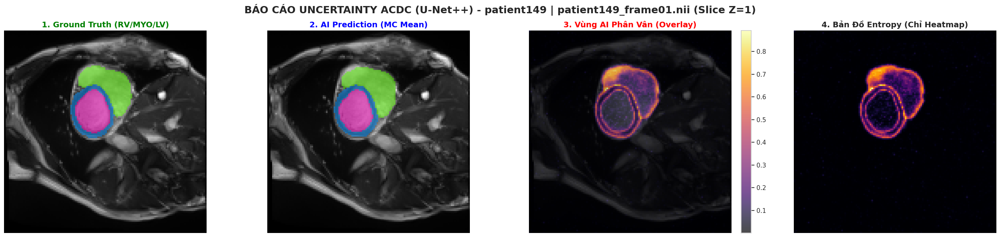

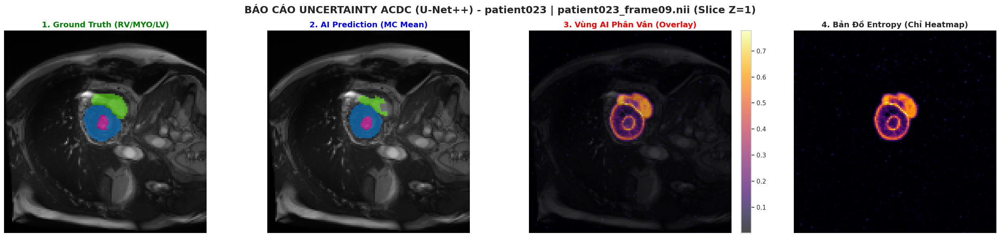

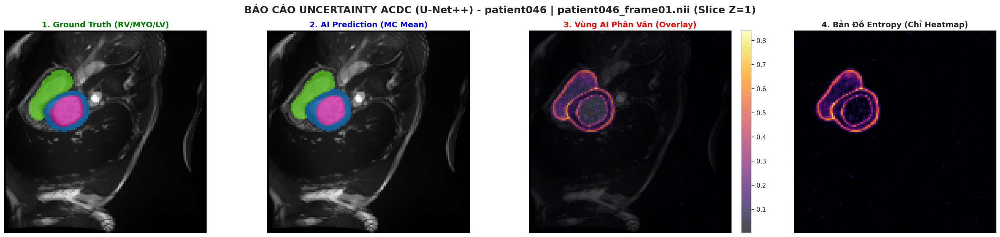

✅ Hoàn tất quá trình trích xuất!


In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import random
from pathlib import Path

# ==============================================================================
# 1. HÀM TÍNH ĐỘ BẤT ĐỊNH (UNCERTAINTY BẰNG MC DROPOUT CHO U-NET++)
# ==============================================================================
def compute_uncertainty_mc_dropout(model, input_tensor, T=15):
    """
    Thực hiện Monte Carlo Dropout để ước lượng độ bất định trên ACDC.
    """
    # Kích hoạt chế độ Train để các lớp Dropout hoạt động
    model.train() 
    
    outputs = []
    with torch.no_grad():
        for _ in range(T):
            logits = model(input_tensor)
            
            # Xử lý trường hợp U-Net++ trả về Tuple/List (Deep Supervision)
            if isinstance(logits, (list, tuple)):
                logits = logits[0] if len(logits) == 1 else logits[-1]
                
            # Chuyển đổi thành xác suất
            probs = torch.softmax(logits, dim=1)
            outputs.append(probs) 
            
    # Xếp chồng: (T, 1, C, D, H, W)
    outputs = torch.stack(outputs)
    
    # 1. Tính Dự đoán trung bình (MC Mean Probability)
    mean_prob = torch.mean(outputs, dim=0)
    
    # 2. Tính Predictive Entropy (Độ bất định)
    epsilon = 1e-7 
    uncertainty_map = -torch.sum(mean_prob * torch.log(mean_prob + epsilon), dim=1)
    
    # Trả mô hình về chế độ Eval an toàn
    model.eval()
    
    return mean_prob, uncertainty_map

# ==============================================================================
# 2. VISUALIZATION DASHBOARD (ACDC UNCERTAINTY)
# ==============================================================================
def visualize_uncertainty_acdc(model, items, device="cuda", num_samples=3):
    print(f"🚀 Đang tính toán Bản đồ Bất định (MC Dropout) cho {num_samples} mẫu ACDC...")
    
    # Đảm bảo model ở chế độ eval trước (chỉ bật train bên trong hàm tính)
    model.eval()

    # Chọn ngẫu nhiên vài ca từ tập Test (te_items)
    indices = random.sample(range(len(items)), min(len(items), num_samples))

    for idx in indices:
        try:
            # Load data không augment qua class VolumeDataset của bạn
            ds = VolumeDataset([items[idx]], augment=False)
            sample = ds[0]
            
            img = sample["image"].unsqueeze(0).to(device) # (1, 1, D, H, W)
            label = sample["label"].numpy()
            
            # --- TÍNH UNCERTAINTY ---
            mean_prob, unc_map = compute_uncertainty_mc_dropout(model, img, T=15)
            
            pred_mask = torch.argmax(mean_prob, dim=1).detach().cpu().numpy()[0]
            unc_map_np = unc_map.detach().cpu().numpy()[0] 
            
            # Làm mịn quầng nhiệt để hiển thị chuyên nghiệp hơn
            unc_map_smooth = gaussian_filter(unc_map_np, sigma=0.5)
            
            # --- TÌM SLICE CÓ NHIỀU THÔNG TIN NHẤT ---
            img_np = img.detach().cpu().numpy()[0, 0]
            sums = np.sum(label > 0, axis=(0, 1))
            slice_idx = np.argmax(sums) if np.max(sums) > 0 else label.shape[2] // 2
            
            # Bóc tách tên Bệnh nhân
            p_name = Path(items[idx][0]).parent.name
            f_name = Path(items[idx][0]).name
            
            # --- VẼ HÌNH ---
            fig, axes = plt.subplots(1, 4, figsize=(26, 6))
            plt.suptitle(f"BÁO CÁO UNCERTAINTY ACDC (U-Net++) - {p_name} | {f_name} (Slice Z={slice_idx})", 
                         fontsize=18, fontweight='bold')
            
            # Ô 1: Ground Truth (ACDC có 3 màu: RV, MYO, LV)
            axes[0].imshow(img_np[:, :, slice_idx], cmap='gray')
            gt_masked = np.ma.masked_where(label[:, :, slice_idx] == 0, label[:, :, slice_idx])
            axes[0].imshow(gt_masked, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
            axes[0].set_title("1. Ground Truth (RV/MYO/LV)", fontsize=14, color='green', fontweight='bold')
            axes[0].axis('off')

            # Ô 2: AI MC Prediction
            axes[1].imshow(img_np[:, :, slice_idx], cmap='gray')
            pred_masked = np.ma.masked_where(pred_mask[:, :, slice_idx] == 0, pred_mask[:, :, slice_idx])
            axes[1].imshow(pred_masked, cmap='gist_rainbow', alpha=0.5, vmin=0, vmax=3)
            axes[1].set_title("2. AI Prediction (MC Mean)", fontsize=14, color='blue', fontweight='bold')
            axes[1].axis('off')

            # Ô 3: Uncertainty Overlay
            axes[2].imshow(img_np[:, :, slice_idx], cmap='gray')
            im_unc = axes[2].imshow(unc_map_smooth[:, :, slice_idx], cmap='inferno', alpha=0.7) 
            axes[2].set_title("3. Vùng AI Phân Vân (Overlay)", fontsize=14, color='red', fontweight='bold')
            axes[2].axis('off')
            plt.colorbar(im_unc, ax=axes[2], fraction=0.046, pad=0.04)

            # Ô 4: Uncertainty Only
            axes[3].imshow(unc_map_smooth[:, :, slice_idx], cmap='inferno')
            axes[3].set_title("4. Bản Đồ Entropy (Chỉ Heatmap)", fontsize=14, fontweight='bold')
            axes[3].axis('off')

            plt.tight_layout()
            plt.show()
            
        except Exception as e:
            print(f"❌ Lỗi khi xử lý mẫu {idx}: {e}")
            continue

    print("✅ Hoàn tất quá trình trích xuất!")

# --- GỌI HÀM THỰC THI ---
visualize_uncertainty_acdc(model, te_items, device=DEVICE, num_samples=3)

# random

BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
✅ Đã load thành công model!


Extracting:   0%|          | 0/80 [00:00<?, ?it/s]

Extracting:   0%|          | 0/20 [00:00<?, ?it/s]

Extracting:   0%|          | 0/50 [00:00<?, ?it/s]


🎯 ĐỘ CHÍNH XÁC PHÂN LOẠI CUỐI CÙNG: 86.00%


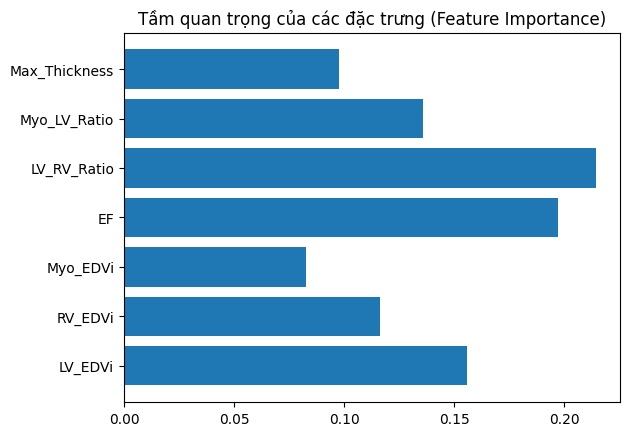

In [4]:
import os, random, csv, time, math
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from monai.networks.nets import BasicUNetPlusPlus

# ---------------- 0. CẤU HÌNH ----------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_SIZE = (128, 128, 16)
NUM_CLASSES = 4
SEED = 42

# ---------------- 1. LOAD MODEL (U-NET++) ----------------
model = BasicUNetPlusPlus(
    spatial_dims=3, in_channels=1, out_channels=NUM_CLASSES,
    features=(16, 32, 64, 128, 256, 16), dropout=0.2
).to(DEVICE)

model_path = "/kaggle/input/models/chaumaituanlam/unet-/pytorch/default/1/best_model (6).pth"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=DEVICE), strict=False)
    print("✅ Đã load thành công model!")
else:
    print("❌ CẢNH BÁO: Không tìm thấy file model!")

# ---------------- 2. HÀM TRÍCH XUẤT ĐẶC TRƯNG ----------------
# Đảm bảo label_encoder đã được fit từ trước khi chạy hàm này
all_diseases = [patient_data[pid]['disease'] for pid in patient_data]
label_encoder = LabelEncoder()
label_encoder.fit(all_diseases)

def get_clinical_features(patient_list, model, device):
    all_features = []
    model.eval()
    for pid in tqdm(patient_list, desc="Extracting"):
        data = patient_data[pid]
        scans = data['scans']
        p_dir = Path(scans[0][0]).parent
        info_file = p_dir / "Info.cfg"
        height, weight = 170.0, 70.0
        ed_f, es_f = 1, 1
        
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if "Height:" in line: height = float(line.split(":")[1])
                    elif "Weight:" in line: weight = float(line.split(":")[1])
                    elif "ED:" in line: ed_f = int(line.split(":")[1])
                    elif "ES:" in line: es_f = int(line.split(":")[1])
        
        bsa = math.sqrt((height * weight) / 3600.0)
        vols = {}
        for phase, f_idx in [("ED", ed_f), ("ES", es_f)]:
            img_path = next((s[0] for s in scans if f"frame{f_idx:02d}" in s[0]), scans[0][0])
            img_data = nib.load(img_path).get_fdata().astype(np.float32)
            dx, dy, dz = nib.load(img_path).header.get_zooms()
            voxel_vol = (dx * dy * dz) / 1000.0
            
            img_in = ndi.zoom(img_data, (TARGET_SIZE[0]/img_data.shape[0], TARGET_SIZE[1]/img_data.shape[1], TARGET_SIZE[2]/img_data.shape[2]), order=1)
            img_in = (img_in - img_in.mean()) / (img_in.std() + 1e-6)
            
            with torch.no_grad():
                out = model(torch.from_numpy(img_in[None, None]).to(device).float())
                if isinstance(out, (list, tuple)): out = out[0]
                pred = torch.argmax(out, 1).squeeze().cpu().numpy()
            
            mask = ndi.zoom(pred, (img_data.shape[0]/TARGET_SIZE[0], img_data.shape[1]/TARGET_SIZE[1], img_data.shape[2]/TARGET_SIZE[2]), order=0)
            vols[phase] = {
                'RV': np.sum(mask == 1) * voxel_vol,
                'Myo': np.sum(mask == 2) * voxel_vol,
                'LV': np.sum(mask == 3) * voxel_vol,
                'mask': mask, 'zooms': [dx, dy, dz]
            }

        lv_edv = vols['ED']['LV']
        lv_esv = vols['ES']['LV']
        ef = ((lv_edv - lv_esv) / (lv_edv + 1e-6)) * 100
        lv_mask = (vols['ED']['mask'] == 3)
        myo_mask = (vols['ED']['mask'] == 2)
        lv_dist = ndi.distance_transform_edt(~lv_mask, sampling=vols['ED']['zooms'])
        max_thick = np.max(lv_dist * myo_mask) if np.sum(myo_mask)>0 else 0

        all_features.append({
            'LV_EDVi': lv_edv / bsa, 'RV_EDVi': vols['ED']['RV'] / bsa,
            'Myo_EDVi': vols['ED']['Myo'] / bsa, 'EF': ef,
            'LV_RV_Ratio': lv_edv / (vols['ED']['RV'] + 1e-6),
            'Myo_LV_Ratio': vols['ED']['Myo'] / (lv_edv + 1e-6),
            'Max_Thickness': max_thick,
            'Label': label_encoder.transform([data['disease']])[0]
        })
    return pd.DataFrame(all_features)

# ---------------- 3. HUẤN LUYỆN RANDOM FOREST ----------------
df_train = get_clinical_features(train_ids, model, DEVICE) 
df_val   = get_clinical_features(val_ids, model, DEVICE)   
df_test  = get_clinical_features(test_ids, model, DEVICE)  

scaler = StandardScaler()
X_train_full = scaler.fit_transform(pd.concat([df_train, df_val]).drop('Label', axis=1).values)
y_train_full = pd.concat([df_train, df_val])['Label'].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ensemble_models = []

for tr_idx, _ in skf.split(X_train_full, y_train_full):
    # Cân bằng nhãn để tránh con số 40%
    m = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=SEED, n_jobs=-1)
    m.fit(X_train_full[tr_idx], y_train_full[tr_idx])
    ensemble_models.append(m)

# ---------------- 4. ĐÁNH GIÁ ----------------
X_test = scaler.transform(df_test.drop('Label', axis=1).values)
y_test = df_test['Label'].values
test_probs = np.zeros((len(X_test), len(label_encoder.classes_)))
for m in ensemble_models: test_probs += m.predict_proba(X_test)

final_preds = np.argmax(test_probs, axis=1)
acc = (final_preds == y_test).mean()

print(f"\n🎯 ĐỘ CHÍNH XÁC PHÂN LOẠI CUỐI CÙNG: {acc*100:.2f}%")

# Vẽ Feature Importance để check xem AI có đang học đúng không
importances = np.mean([m.feature_importances_ for m in ensemble_models], axis=0)
plt.barh(df_train.drop('Label', axis=1).columns, importances)
plt.title("Tầm quan trọng của các đặc trưng (Feature Importance)")
plt.show()

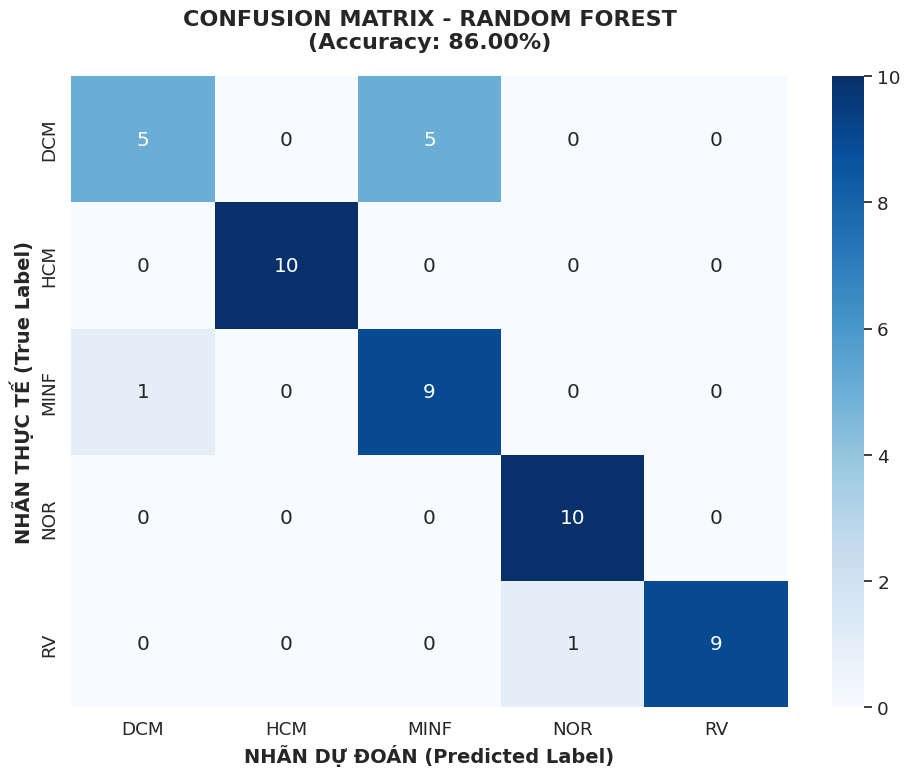


         CHI TIẾT CHỈ SỐ PHÂN LOẠI (RANDOM FOREST)          
              precision    recall  f1-score   support

         DCM       0.83      0.50      0.62        10
         HCM       1.00      1.00      1.00        10
        MINF       0.64      0.90      0.75        10
         NOR       0.91      1.00      0.95        10
          RV       1.00      0.90      0.95        10

    accuracy                           0.86        50
   macro avg       0.88      0.86      0.85        50
weighted avg       0.88      0.86      0.85        50



In [5]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lấy tên các lớp bệnh từ label_encoder để hiển thị lên trục tọa độ
class_names = label_encoder.classes_

# 2. Tính toán ma trận nhầm lẫn
# final_preds: Dự đoán cuối cùng từ hội đồng Random Forest
# y_test: Nhãn thật của 50 bệnh nhân tập Test
cm = confusion_matrix(y_test, final_preds)

# 3. Vẽ biểu đồ bằng Seaborn
plt.figure(figsize=(10, 8))
sns.set_theme(font_scale=1.2) # Chỉnh kích thước chữ cho dễ đọc
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

# Đổi tiêu đề cho chuẩn với thuật toán Random Forest
plt.title(f'CONFUSION MATRIX - RANDOM FOREST\n(Accuracy: {acc*100:.2f}%)', 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('NHÃN THỰC TẾ (True Label)', fontsize=14, fontweight='bold')
plt.xlabel('NHÃN DỰ ĐOÁN (Predicted Label)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. In thêm bảng báo cáo chi tiết (Precision, Recall, F1-Score)
print("\n" + "="*60)
print(f"{'CHI TIẾT CHỈ SỐ PHÂN LOẠI (RANDOM FOREST)':^60}")
print("="*60)
print(classification_report(y_test, final_preds, target_names=class_names))
print("="*60)

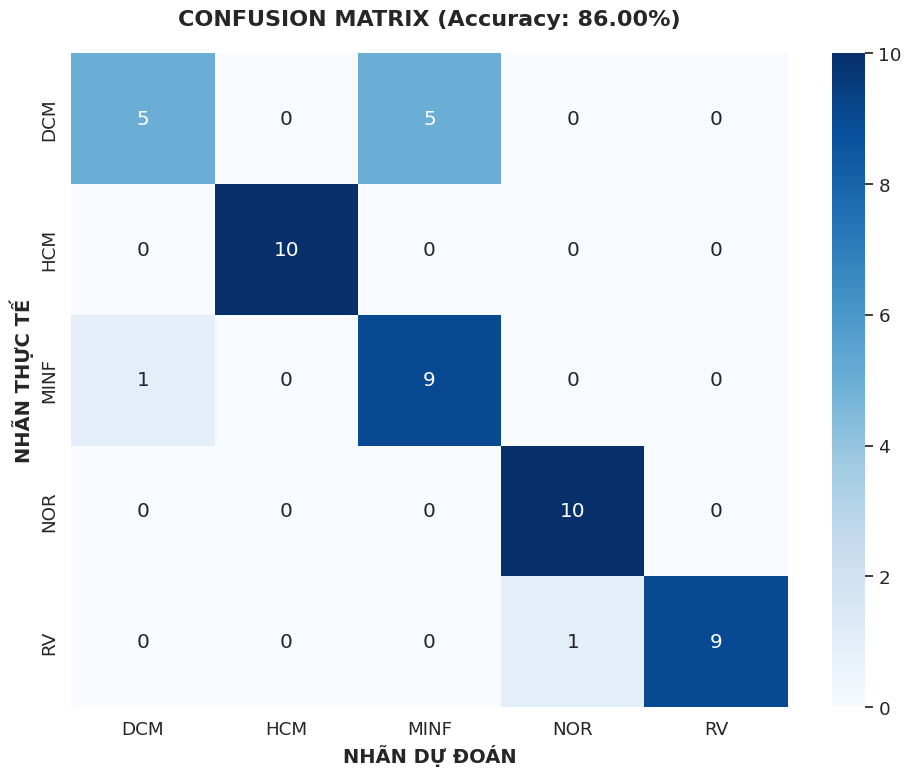


                 CHI TIẾT CHỈ SỐ PHÂN LOẠI                  
              precision    recall  f1-score   support

         DCM       0.83      0.50      0.62        10
         HCM       1.00      1.00      1.00        10
        MINF       0.64      0.90      0.75        10
         NOR       0.91      1.00      0.95        10
          RV       1.00      0.90      0.95        10

    accuracy                           0.86        50
   macro avg       0.88      0.86      0.85        50
weighted avg       0.88      0.86      0.85        50



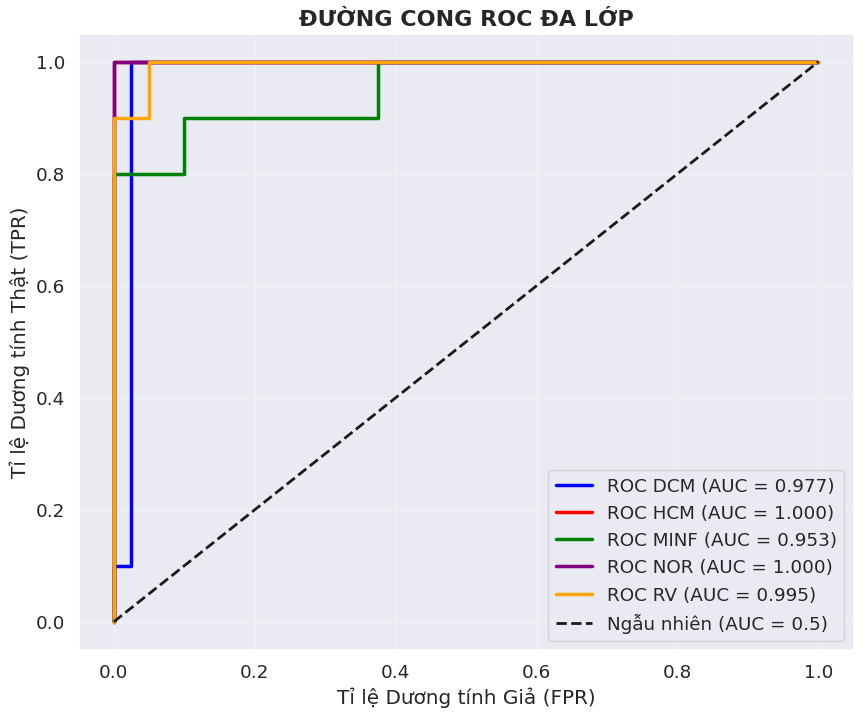

In [8]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns

# ---------------- 5. CONFUSION MATRIX ----------------
# Lấy tên các lớp bệnh từ label_encoder
class_names = label_encoder.classes_
cm = confusion_matrix(y_test, final_preds)

plt.figure(figsize=(10, 8))
sns.set_theme(font_scale=1.2)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'CONFUSION MATRIX (Accuracy: {acc*100:.2f}%)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('NHÃN THỰC TẾ', fontsize=14, fontweight='bold')
plt.xlabel('NHÃN DỰ ĐOÁN', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# In báo cáo chi tiết
print("\n" + "="*60)
print(f"{'CHI TIẾT CHỈ SỐ PHÂN LOẠI':^60}")
print("="*60)
print(classification_report(y_test, final_preds, target_names=class_names))

# ---------------- 6. ĐƯỜNG CONG ROC ĐA LỚP ----------------
n_classes = len(class_names)
y_test_bin = label_binarize(y_test, classes=range(n_classes))
test_probs_avg = test_probs / len(ensemble_models)

plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'purple', 'orange']

for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], test_probs_avg[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5, 
             label=f'ROC {class_names[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Ngẫu nhiên (AUC = 0.5)')
plt.xlabel('Tỉ lệ Dương tính Giả (FPR)')
plt.ylabel('Tỉ lệ Dương tính Thật (TPR)')
plt.title('ĐƯỜNG CONG ROC ĐA LỚP', fontsize=16, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

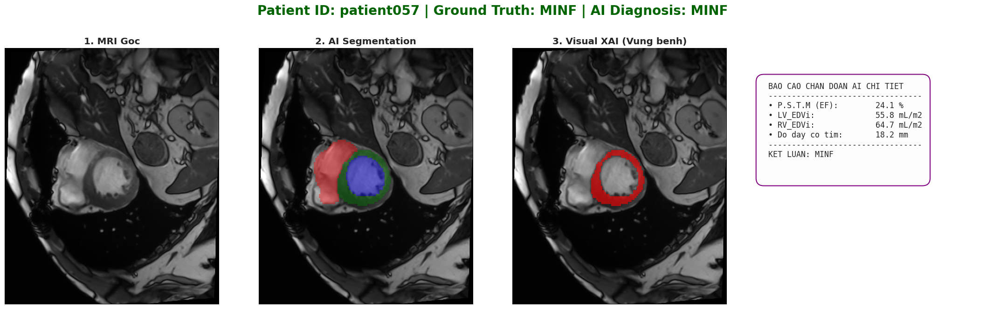

In [9]:
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy.ndimage as ndi
from matplotlib import rcParams
import nibabel as nib
import torch
from pathlib import Path

# Cấu hình phông chữ
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['DejaVu Sans']

# 1. HÀM TẠO BÁO CÁO
def generate_detailed_report(metrics, pred_disease):
    ef = metrics.get('EF', 0.0)
    lv_edvi = metrics.get('LV_EDVi', 0.0)
    rv_edvi = metrics.get('RV_EDVi', 0.0)
    m_thick = metrics.get('Max_Thickness', 0.0)
    text =  " BAO CAO CHAN DOAN AI CHI TIET\n"
    text += " ---------------------------------\n"
    text += f" • P.S.T.M (EF):      {ef:>6.1f} %\n"
    text += f" • LV_EDVi:           {lv_edvi:>6.1f} mL/m2\n"
    text += f" • RV_EDVi:           {rv_edvi:>6.1f} mL/m2\n"
    text += f" • Do day co tim:     {m_thick:>6.1f} mm\n"
    text += " ---------------------------------\n"
    text += f" KET LUAN: {pred_disease}\n\n"
    return text

# 2. HÀM TẠO MASK BỆNH LÝ
def generate_abnormal_heatmap(mask, disease):
    heatmap = np.zeros_like(mask, dtype=np.float32)
    if disease == "DCM": heatmap[mask == 3] = 1.0 
    elif disease in ["HCM", "MINF"]: heatmap[mask == 2] = 1.0 
    elif disease == "RV": heatmap[mask == 1] = 1.0 
    return heatmap

# 3. DASHBOARD ĐÃ ĐỒNG BỘ CHỈ SỐ (FIX LỖI LỆCH PID)
def visualize_xai_dashboard_full(model, patient_data, test_idx, df_test, label_encoder, device):
    # ĐỒNG BỘ PID VỚI TẬP TEST
    pid = test_ids[test_idx]
    data = patient_data[pid]
    img_path = data['scans'][0][0]
    img_np = nib.load(img_path).get_fdata().astype(np.float32)
    
    # Inference Segmentation
    zoom_in = (TARGET_SIZE[0]/img_np.shape[0], TARGET_SIZE[1]/img_np.shape[1], TARGET_SIZE[2]/img_np.shape[2])
    img_input = torch.from_numpy(ndi.zoom(img_np, zoom_in, order=1)[None, None]).to(device).float()
    
    model.eval()
    with torch.no_grad():
        out = model(img_input)
        if isinstance(out, (list, tuple)): out = out[0]
        pred_small = torch.argmax(out, dim=1).squeeze().cpu().numpy()
        
    mask_full = ndi.zoom(pred_small, (img_np.shape[0]/TARGET_SIZE[0], img_np.shape[1]/TARGET_SIZE[1], img_np.shape[2]/TARGET_SIZE[2]), order=0)
    
    # ĐỒNG BỘ NHÃN DỰ ĐOÁN VỚI TẬP TEST
    predicted_disease = label_encoder.inverse_transform([final_preds[test_idx]])[0]
    true_disease = data['disease']
    color_title = 'darkgreen' if predicted_disease == true_disease else 'darkred'
    
    # Tạo báo cáo và mask
    metrics = df_test.iloc[test_idx].to_dict()
    clinical_text = generate_detailed_report(metrics, predicted_disease)
    abnormal_heatmap = generate_abnormal_heatmap(mask_full, predicted_disease)
    
    # Vẽ
    best_z = np.argmax(np.sum(mask_full > 0, axis=(0, 1)))
    plt.figure(figsize=(22, 7))
    plt.suptitle(f"Patient ID: {pid} | Ground Truth: {true_disease} | AI Diagnosis: {predicted_disease}", 
                 fontsize=20, fontweight='bold', color=color_title)
    
    # Khung 1, 2, 3: MRI, Seg, XAI
    for i, title in enumerate(["1. MRI Goc", "2. AI Segmentation", "3. Visual XAI (Vung benh)"]):
        ax = plt.subplot(1, 4, i+1)
        ax.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
        if i == 1: # Seg
            ax.imshow(np.rot90(mask_full[:, :, best_z]), cmap=mcolors.ListedColormap(['none', 'red', 'green', 'blue']), alpha=0.4, vmin=0, vmax=3)
        if i == 2: # XAI
            mask = np.rot90(abnormal_heatmap[:, :, best_z])
            if np.max(mask) > 0:
                overlay = np.zeros((*mask.shape, 4), dtype=np.float32)
                overlay[mask > 0] = [1, 0, 0, 0.6]
                ax.imshow(overlay)
        ax.set_title(title, fontweight='bold'); ax.axis('off')
        
    # Khung 4: Textual Report
    ax4 = plt.subplot(1, 4, 4)
    ax4.text(0.05, 0.5, clinical_text, fontsize=12, family='monospace',
             bbox=dict(boxstyle="round,pad=1", facecolor='#fdfdfd', edgecolor='purple', linewidth=1.5))
    ax4.axis('off')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Thực thi (Thay số 45 bằng bất kỳ chỉ số từ 0 đến 49)
visualize_xai_dashboard_full(model, patient_data, 0, df_test, label_encoder, DEVICE)


🧠 Đang phân tích mức độ đóng góp của từng chỉ số y khoa bằng SHAP...


/tmp/ipykernel_57/2522471491.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test,


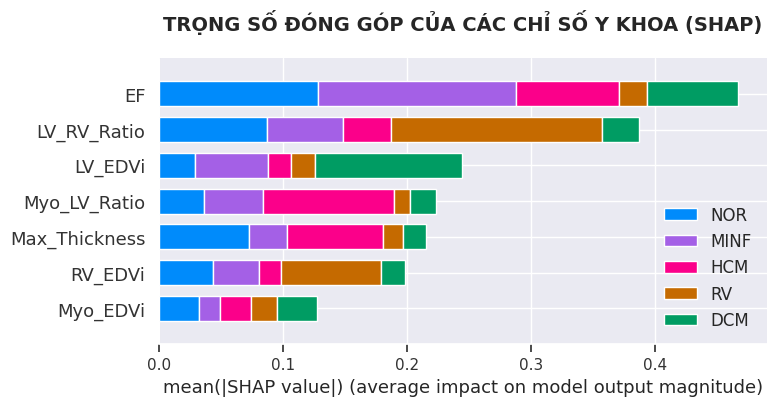


🔬 Đang vẽ biểu đồ bầy ong cho bệnh: DCM


/tmp/ipykernel_57/2522471491.py:50: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(current_shap, X_test,


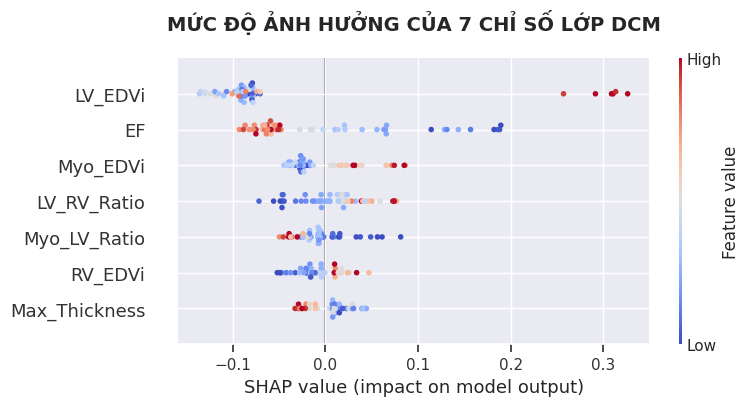


🔬 Đang vẽ biểu đồ bầy ong cho bệnh: HCM


/tmp/ipykernel_57/2522471491.py:50: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(current_shap, X_test,


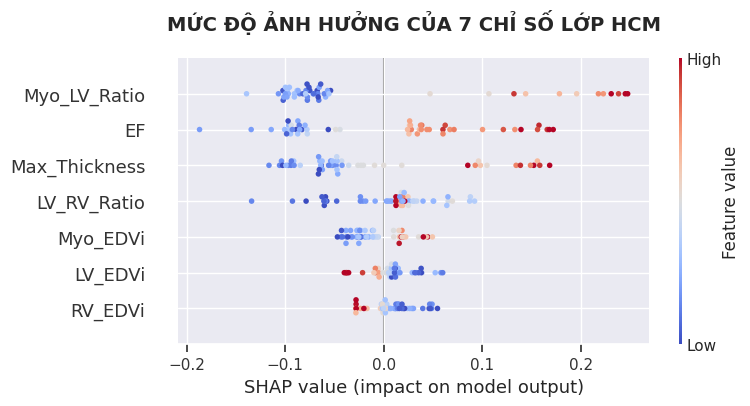


🔬 Đang vẽ biểu đồ bầy ong cho bệnh: MINF


/tmp/ipykernel_57/2522471491.py:50: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(current_shap, X_test,


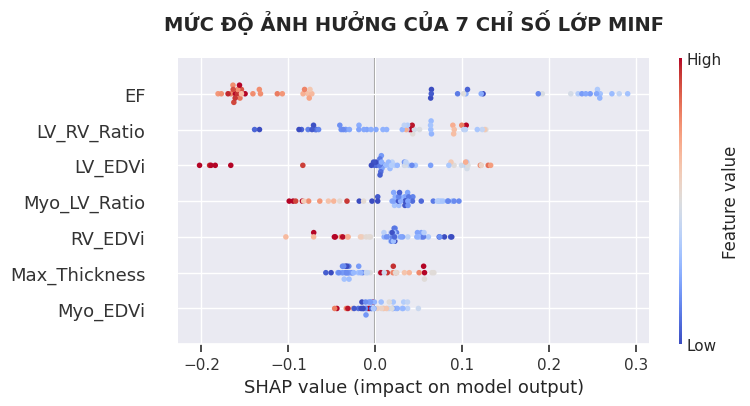


🔬 Đang vẽ biểu đồ bầy ong cho bệnh: NOR


/tmp/ipykernel_57/2522471491.py:50: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(current_shap, X_test,


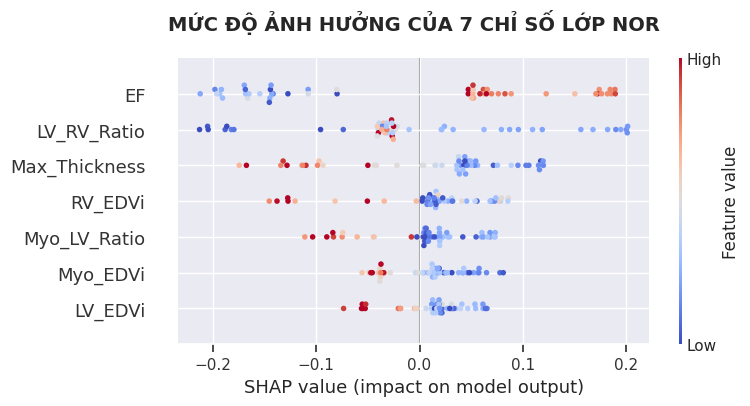


🔬 Đang vẽ biểu đồ bầy ong cho bệnh: RV


/tmp/ipykernel_57/2522471491.py:50: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(current_shap, X_test,


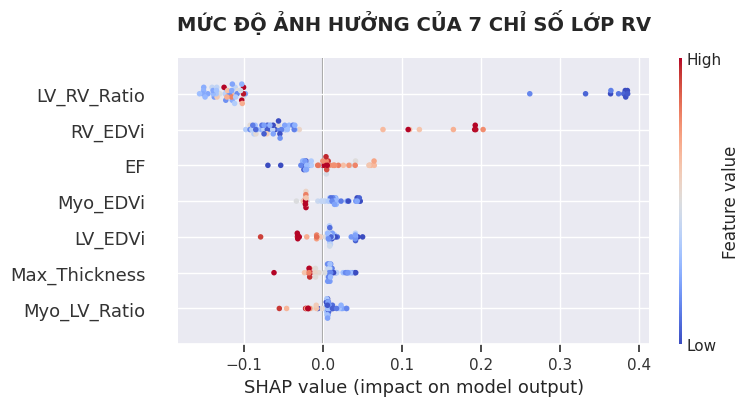

In [10]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Cấu hình lại để SHAP không bị mất chữ
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

print("\n🧠 Đang phân tích mức độ đóng góp của từng chỉ số y khoa bằng SHAP...")

# 1. Khởi tạo lại explainer
explainer = shap.TreeExplainer(ensemble_models[0])
shap_values = explainer.shap_values(X_test)

# 2. Xử lý cấu trúc dữ liệu cho bài toán đa lớp (tránh lỗi Index)
# Nếu shap_values là list (đối với Classifier đa lớp), ta dùng mảng tương ứng
if isinstance(shap_values, list):
    # Tổng hợp tất cả các class để vẽ summary plot chung
    shap_vals_summary = np.array(shap_values).transpose(1, 2, 0)
else:
    shap_vals_summary = shap_values

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: TỔNG QUAN BAR PLOT
# ----------------------------------------------------------------------
plt.figure(figsize=(10, 6))
# Sử dụng summary_plot với plot_type="bar"
shap.summary_plot(shap_values, X_test, 
                  feature_names=feature_names, 
                  class_names=label_encoder.classes_, 
                  plot_type="bar", 
                  show=False)

plt.title('TRỌNG SỐ ĐÓNG GÓP CỦA CÁC CHỈ SỐ Y KHOA (SHAP)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: BEESWARM PLOT CHO TỪNG BỆNH (ĐÃ FIX MÀU)
# ----------------------------------------------------------------------
for i, class_name in enumerate(label_encoder.classes_):
    print(f"\n🔬 Đang vẽ biểu đồ bầy ong cho bệnh: {class_name}")
    
    # Lấy Shap values riêng cho lớp này
    current_shap = shap_values[i] if isinstance(shap_values, list) else shap_values[:, :, i]
    
    plt.figure(figsize=(10, 6))
    
    # Vẽ Beeswarm với màu sắc chuẩn mực
    shap.summary_plot(current_shap, X_test, 
                      feature_names=feature_names, 
                      show=False,
                      cmap=plt.get_cmap("coolwarm")) # Dùng coolwarm để phân biệt âm dương
    
    plt.title(f"MỨC ĐỘ ẢNH HƯỞNG CỦA 7 CHỈ SỐ LỚP {class_name.upper()}", 
              fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

# svm

In [11]:
import os, random, math
import numpy as np
import pandas as pd
import nibabel as nib
import scipy.ndimage as ndi
import torch
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from monai.networks.nets import BasicUNetPlusPlus
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ======================================================================
# 0. CẤU HÌNH & LOAD MODEL (ĐẢM BẢO KIẾN TRÚC KHỚP VỚI FILE .PTH)
# ======================================================================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_SIZE = (128, 128, 16)
SEED = 42

# Khởi tạo kiến trúc UNet++ (Nếu lỗi Missing Key, hãy kiểm tra lại kiến trúc khi train)
model = BasicUNetPlusPlus(
    spatial_dims=3, in_channels=1, out_channels=4,
    features=(16, 32, 64, 128, 256, 16), dropout=0.2
).to(DEVICE)

# ĐƯỜNG DẪN MÔ HÌNH (Thay bằng đường dẫn file .pth chuẩn của bạn)
model_path = "/kaggle/input/models/chaumaituanlam/unet-/pytorch/default/1/best_model (6).pth"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=DEVICE), strict=True)
    print("✅ Load model thành công!")
else:
    print(f"❌ Không thấy model tại {model_path}")

# ======================================================================
# 1. HÀM TRÍCH XUẤT ĐẶC TRƯNG
# ======================================================================
def get_clinical_features(patient_list, model, device, label_encoder):
    all_features = []
    model.eval()
    for pid in tqdm(patient_list, desc="Extracting Features"):
        data = patient_data[pid]
        scans = data['scans']
        
        # Đọc info
        p_dir = Path(scans[0][0]).parent
        info_file = p_dir / "Info.cfg"
        height, weight, ed_f, es_f = 170.0, 70.0, 1, 1
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if "Height:" in line: height = float(line.split(":")[1])
                    elif "Weight:" in line: weight = float(line.split(":")[1])
                    elif "ED:" in line: ed_f = int(line.split(":")[1])
                    elif "ES:" in line: es_f = int(line.split(":")[1])
        
        bsa = math.sqrt((height * weight) / 3600.0)
        vols = {}
        for phase, f_idx in [("ED", ed_f), ("ES", es_f)]:
            img_path = next((s[0] for s in scans if f"frame{f_idx:02d}" in s[0]), scans[0][0])
            img_data = nib.load(img_path).get_fdata().astype(np.float32)
            dx, dy, dz = nib.load(img_path).header.get_zooms()
            voxel_vol = (dx * dy * dz) / 1000.0
            
            img_in = ndi.zoom(img_data, (TARGET_SIZE[0]/img_data.shape[0], TARGET_SIZE[1]/img_data.shape[1], TARGET_SIZE[2]/img_data.shape[2]), order=1)
            img_in = (img_in - img_in.mean()) / (img_in.std() + 1e-6)
            
            with torch.no_grad():
                out = model(torch.from_numpy(img_in[None, None]).float().to(device))
                if isinstance(out, (list, tuple)): out = out[0]
                pred = torch.argmax(out, 1).squeeze().cpu().numpy()
            
            mask = ndi.zoom(pred, (img_data.shape[0]/TARGET_SIZE[0], img_data.shape[1]/TARGET_SIZE[1], img_data.shape[2]/TARGET_SIZE[2]), order=0)
            vols[phase] = {'RV': np.sum(mask == 1)*voxel_vol, 'Myo': np.sum(mask == 2)*voxel_vol, 'LV': np.sum(mask == 3)*voxel_vol, 'mask': mask, 'zooms': [dx, dy, dz]}

        lv_edv = vols['ED']['LV']
        lv_esv = vols['ES']['LV']
        ef = ((lv_edv - lv_esv) / (lv_edv + 1e-6)) * 100
        lv_dist = ndi.distance_transform_edt(~(vols['ED']['mask'] == 3), sampling=vols['ED']['zooms'])
        max_thick = np.max(lv_dist * (vols['ED']['mask'] == 2)) if np.sum(vols['ED']['mask'] == 2) > 0 else 0

        all_features.append({
            'LV_EDVi': lv_edv / bsa, 'RV_EDVi': vols['ED']['RV'] / bsa, 'Myo_EDVi': vols['ED']['Myo'] / bsa,
            'EF': ef, 'LV_RV_Ratio': lv_edv / (vols['ED']['RV'] + 1e-6), 'Myo_LV_Ratio': vols['ED']['Myo'] / (lv_edv + 1e-6),
            'Max_Thickness': max_thick, 'Label': label_encoder.transform([data['disease']])[0]
        })
    return pd.DataFrame(all_features)

# ======================================================================
# 2. XỬ LÝ DỮ LIỆU & HUẤN LUYỆN SVM HỘI ĐỒNG
# ======================================================================
label_encoder = LabelEncoder().fit([patient_data[pid]['disease'] for pid in patient_data])

df_train = get_clinical_features(train_ids, model, DEVICE, label_encoder)
df_val   = get_clinical_features(val_ids, model, DEVICE, label_encoder)
df_test  = get_clinical_features(test_ids, model, DEVICE, label_encoder)

X_train_full = pd.concat([df_train, df_val]).drop('Label', axis=1).values
y_train_full = pd.concat([df_train, df_val])['Label'].values
X_test = df_test.drop('Label', axis=1).values
y_test = df_test['Label'].values

scaler = StandardScaler()
X_train_full_scaled = scaler.fit_transform(X_train_full)
X_test_scaled = scaler.transform(X_test)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ensemble_models = []
test_probs = np.zeros((len(X_test_scaled), len(label_encoder.classes_)))

print("\n🤖 Huấn luyện SVM Hội Đồng...")
for tr_idx, _ in skf.split(X_train_full_scaled, y_train_full):
    m = SVC(kernel='rbf', C=1.5, probability=True, class_weight='balanced', random_state=SEED)
    m.fit(X_train_full_scaled[tr_idx], y_train_full[tr_idx])
    ensemble_models.append(m)
    test_probs += m.predict_proba(X_test_scaled)

final_preds = np.argmax(test_probs, axis=1)
acc = (final_preds == y_test).mean()
print(f"🎯 ĐỘ CHÍNH XÁC TEST: {acc*100:.2f}%")

#

BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).
✅ Load model thành công!


Extracting Features:   0%|          | 0/80 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/20 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/50 [00:00<?, ?it/s]


🤖 Huấn luyện SVM Hội Đồng...
🎯 ĐỘ CHÍNH XÁC TEST: 86.00%


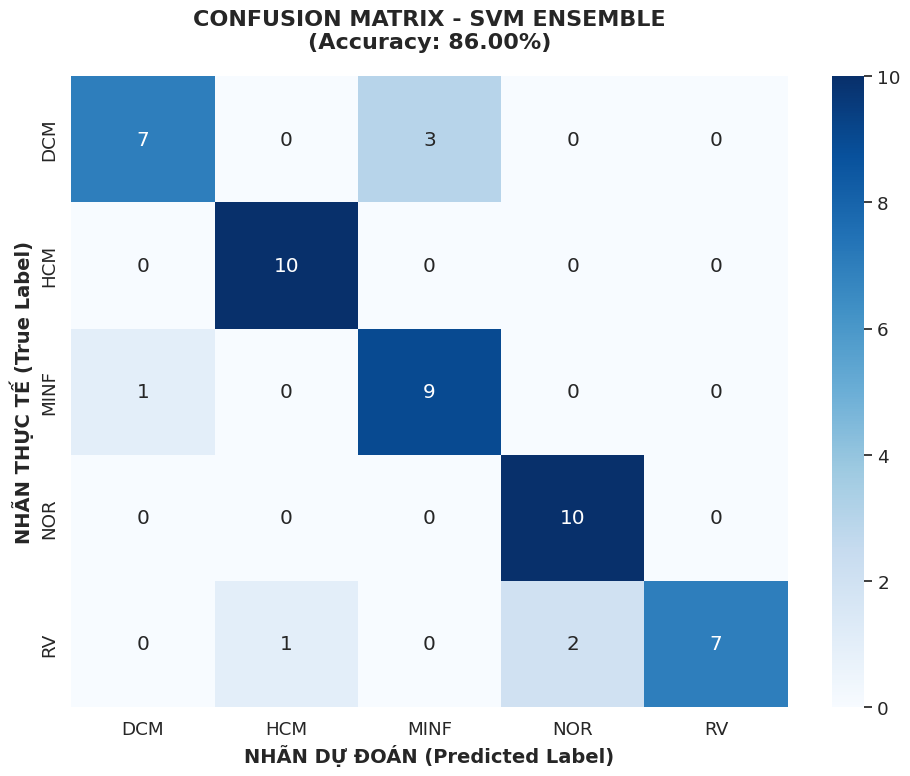


          CHI TIẾT CHỈ SỐ PHÂN LOẠI (SVM ENSEMBLE)          
              precision    recall  f1-score   support

         DCM       0.88      0.70      0.78        10
         HCM       0.91      1.00      0.95        10
        MINF       0.75      0.90      0.82        10
         NOR       0.83      1.00      0.91        10
          RV       1.00      0.70      0.82        10

    accuracy                           0.86        50
   macro avg       0.87      0.86      0.86        50
weighted avg       0.87      0.86      0.86        50



In [12]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lấy tên các lớp bệnh từ label_encoder để hiển thị lên trục tọa độ
class_names = label_encoder.classes_

# 2. Tính toán ma trận nhầm lẫn
# final_preds: Dự đoán cuối cùng từ hội đồng SVM (Soft Voting)
# y_test: Nhãn thật của bệnh nhân tập Test
cm = confusion_matrix(y_test, final_preds)

# 3. Vẽ biểu đồ bằng Seaborn
plt.figure(figsize=(10, 8))
sns.set_theme(font_scale=1.2) # Chỉnh kích thước chữ cho dễ đọc
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

# Đổi tiêu đề cho chuẩn với thuật toán SVM Hội Đồng
plt.title(f'CONFUSION MATRIX - SVM ENSEMBLE\n(Accuracy: {acc*100:.2f}%)', 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('NHÃN THỰC TẾ (True Label)', fontsize=14, fontweight='bold')
plt.xlabel('NHÃN DỰ ĐOÁN (Predicted Label)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. In thêm bảng báo cáo chi tiết (Precision, Recall, F1-Score)
print("\n" + "="*60)
print(f"{'CHI TIẾT CHỈ SỐ PHÂN LOẠI (SVM ENSEMBLE)':^60}")
print("="*60)
print(classification_report(y_test, final_preds, target_names=class_names))
print("="*60)


📊 Đang tính toán mức độ quan trọng bằng Permutation Importance cho SVM...


/tmp/ipykernel_57/61926783.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sorted_importances, y=sorted_features, palette='magma')


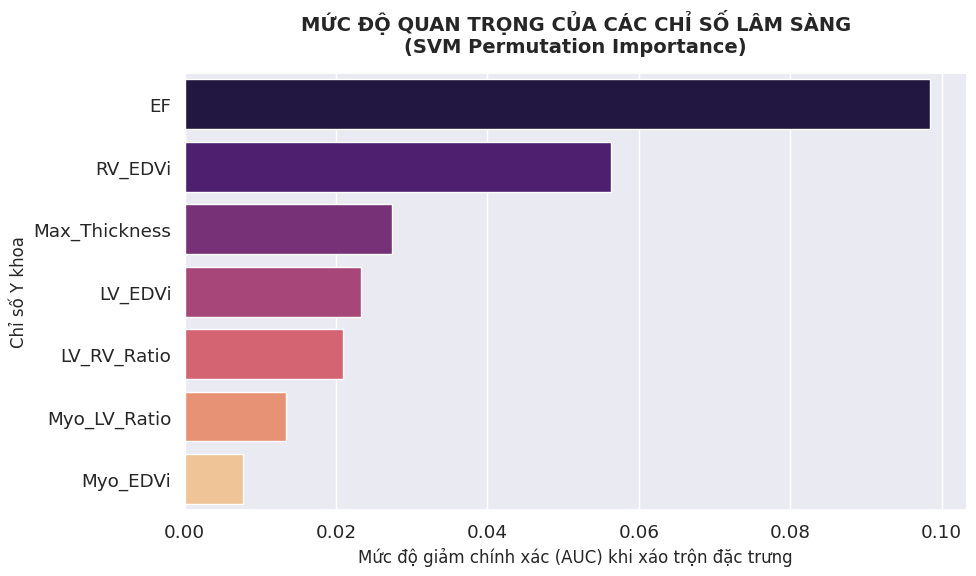


📈 Đang vẽ đường cong ROC (One-vs-Rest) cho 5 lớp bệnh lý...


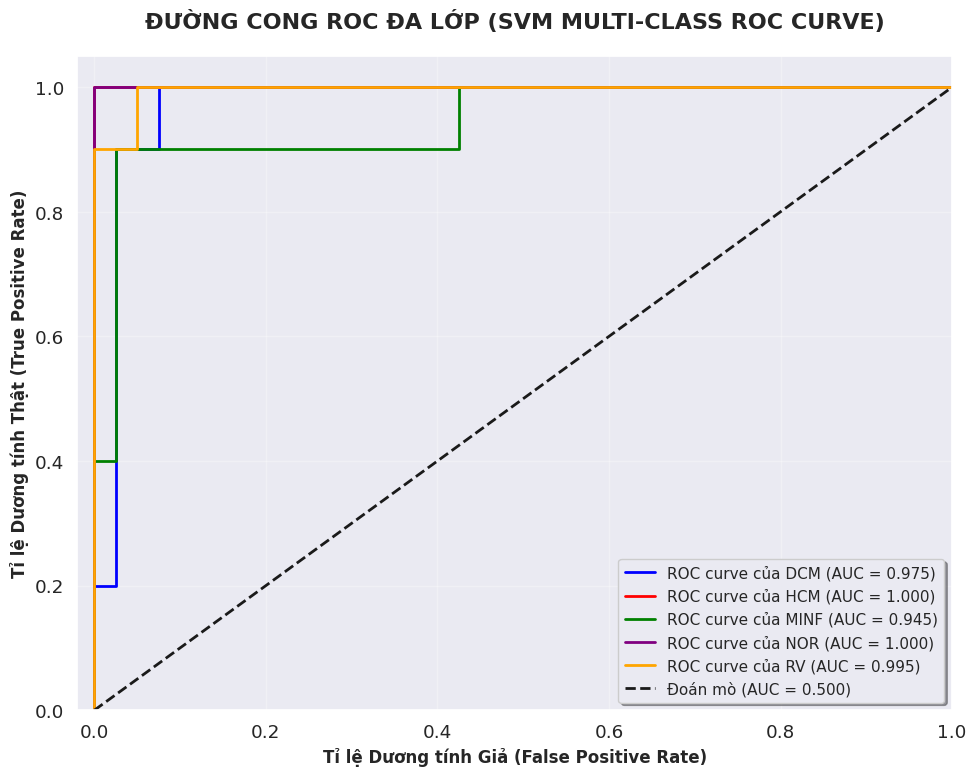

In [13]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.inspection import permutation_importance
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ======================================================================
# 8. ĐÁNH GIÁ SÂU: FEATURE IMPORTANCE VÀ ĐƯỜNG CONG ROC (SVM ENSEMBLE)
# ======================================================================

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: MỨC ĐỘ QUAN TRỌNG CỦA ĐẶC TRƯNG (PERMUTATION IMPORTANCE)
# ----------------------------------------------------------------------
print("\n📊 Đang tính toán mức độ quan trọng bằng Permutation Importance cho SVM...")

# Lấy tên các đặc trưng lâm sàng (giữ đúng thứ tự 7 chỉ số)
feature_names = df_test.drop('Label', axis=1).columns

# Dùng con mô hình SVM đầu tiên trong hội đồng để đánh giá đại diện
best_svm_model = ensemble_models[0]

# Truyền X_test_scaled vào vì SVM đã được train trên tập chuẩn hóa Z-score
result = permutation_importance(
    best_svm_model, X_test_scaled, y_test, 
    n_repeats=15, random_state=SEED, n_jobs=-1,
    scoring='roc_auc_ovo' # Dùng thước đo AUC để nhạy bén hơn với thay đổi xác suất đa lớp
)

# Lấy điểm trung bình và sắp xếp từ cao xuống thấp
importances = result.importances_mean
indices = np.argsort(importances)[::-1]
sorted_features = [feature_names[i] for i in indices]
sorted_importances = importances[indices]

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances, y=sorted_features, palette='magma')
plt.title('MỨC ĐỘ QUAN TRỌNG CỦA CÁC CHỈ SỐ LÂM SÀNG\n(SVM Permutation Importance)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức độ giảm chính xác (AUC) khi xáo trộn đặc trưng', fontsize=12)
plt.ylabel('Chỉ số Y khoa', fontsize=12)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: ĐƯỜNG CONG ROC VÀ CHỈ SỐ AUC (MULTI-CLASS)
# ----------------------------------------------------------------------
print("\n📈 Đang vẽ đường cong ROC (One-vs-Rest) cho 5 lớp bệnh lý...")

# Chuyển đổi nhãn thật y_test sang dạng One-Hot Encoding để tính ROC cho từng lớp
n_classes = len(label_encoder.classes_)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

# Tính toán Tỉ lệ dương tính giả (FPR), Tỉ lệ dương tính thật (TPR) và AUC cho từng lớp
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    # test_probs là biến đã có sẵn từ phần đánh giá (xác suất biểu quyết Soft Voting của 5 Folds)
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Bắt đầu vẽ ROC
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'purple', 'orange']

for i, color in zip(range(n_classes), colors):
    class_name = label_encoder.classes_[i]
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve của {class_name} (AUC = {roc_auc[i]:.3f})')

# Vẽ đường chéo ngẫu nhiên (Baseline)
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Đoán mò (AUC = 0.500)')

# Trang trí biểu đồ
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỉ lệ Dương tính Giả (False Positive Rate)', fontsize=12, fontweight='bold')
plt.ylabel('Tỉ lệ Dương tính Thật (True Positive Rate)', fontsize=12, fontweight='bold')
plt.title('ĐƯỜNG CONG ROC ĐA LỚP (SVM MULTI-CLASS ROC CURVE)', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

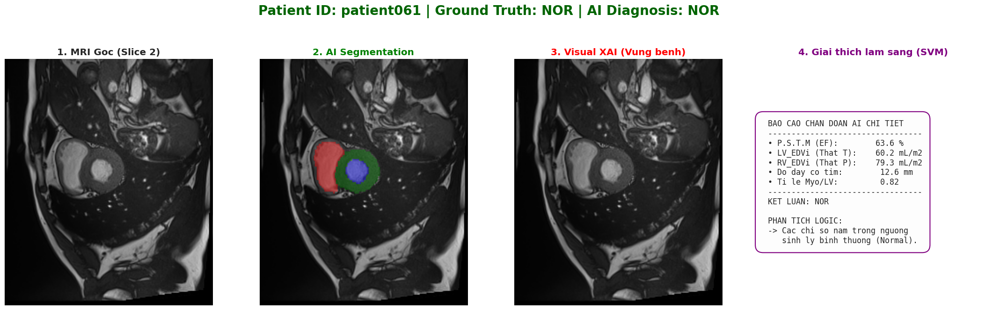

In [14]:
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy.ndimage as ndi
from matplotlib import rcParams
import nibabel as nib
import torch

# ======================================================================
# 7. HỆ THỐNG TRỰC QUAN HÓA XAI TOÀN DIỆN (SVM ENSEMBLE)
# ======================================================================

# Cấu hình phông chữ an toàn tránh lỗi ô vuông
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['DejaVu Sans']

def generate_detailed_report(metrics, pred_disease):
    """ Tạo nội dung giải thích lâm sàng chi tiết không dấu """
    ef = metrics['EF']
    lv_edvi = metrics['LV_EDVi']
    rv_edvi = metrics['RV_EDVi']
    m_thick = metrics['Max_Thickness']
    ratio = metrics['Myo_LV_Ratio']

    text =  " BAO CAO CHAN DOAN AI CHI TIET\n"
    text += " ---------------------------------\n"
    text += f" • P.S.T.M (EF):      {ef:>6.1f} %\n"
    text += f" • LV_EDVi (That T):  {lv_edvi:>6.1f} mL/m2\n"
    text += f" • RV_EDVi (That P):  {rv_edvi:>6.1f} mL/m2\n"
    text += f" • Do day co tim:      {m_thick:>6.1f} mm\n"
    text += f" • Ti le Myo/LV:       {ratio:>6.2f}\n"
    text += " ---------------------------------\n"
    text += f" KET LUAN: {pred_disease}\n\n"

    text += " PHAN TICH LOGIC:\n"
    if pred_disease == "DCM":
        text += f" -> EF thap ({ef:.1f}% < 40%) kem\n"
        text += f"    buong That trai gian rat to\n"
        text += f"    ({lv_edvi:.1f} > 100 mL/m2)."
    elif pred_disease == "HCM":
        text += f" -> Co tim phi dai bat thuong.\n"
        text += f"    Do day max ({m_thick:.1f}mm > 12mm)."
    elif pred_disease == "MINF":
        text += f" -> Co dau hieu seo co tim.\n"
        text += f"    EF giam ({ef:.1f}%) nhung buong\n"
        text += f"    That trai chua gian to."
    elif pred_disease in ["RV", "ARV"]: # Bao gồm cả RV hoặc ARV
        text += f" -> That phai gian to bat thuong\n"
        text += f"    ({rv_edvi:.1f} > 100 mL/m2).\n"
        text += f"    Nghi ngo tang ap luc phoi."
    else:
        text += " -> Cac chi so nam trong nguong\n"
        text += "    sinh ly binh thuong (Normal)."
    return text

def generate_abnormal_heatmap(mask, disease):
    """ Tự động tạo bản đồ nhiệt tập trung vào vùng nghi ngờ bệnh lý """
    heatmap = np.zeros_like(mask, dtype=np.float32)
    # Class 1: RV, Class 2: Myo, Class 3: LV
    if disease == "DCM":
        heatmap[mask == 3] = 1.0  # Bôi đỏ Tâm thất trái (LV)
    elif disease in ["HCM", "MINF"]:
        heatmap[mask == 2] = 1.0  # Bôi đỏ Cơ tim (Myo)
    elif disease in ["RV", "ARV"]:
        heatmap[mask == 1] = 1.0  # Bôi đỏ Tâm thất phải (RV)
    return heatmap

# 1. Chọn ngẫu nhiên 1 bệnh nhân từ tập Test
random_pid = random.choice(test_ids)
# Dùng index để lấy đúng số thứ tự của bệnh nhân trong mảng
patient_idx = test_ids.index(random_pid)
patient_metrics = df_test.iloc[patient_idx].to_dict()

# 2. Lấy dữ liệu ảnh gốc
data = patient_data[random_pid]
img_path = data['scans'][0][0] 
nib_img = nib.load(img_path)
img_np = nib_img.get_fdata().astype(np.float32)
dx, dy, dz = nib_img.header.get_zooms()

# 3. Chạy qua Mắt thần (Segmentation Model) để lấy Mask
zoom_in = (TARGET_SIZE[0]/img_np.shape[0], TARGET_SIZE[1]/img_np.shape[1], TARGET_SIZE[2]/img_np.shape[2])
img_resized = ndi.zoom(img_np, zoom_in, order=1)
img_input = torch.from_numpy((img_resized - img_resized.mean())/(img_resized.std()+1e-6))[None, None].to(DEVICE)

model.eval()
with torch.no_grad():
    out = model(img_input)
    # Xử lý nếu model là dạng tuple (giống DynUNet)
    if isinstance(out, (list, tuple)): out = out[0]
    pred_small = torch.argmax(out, dim=1).squeeze().cpu().numpy()

# Zoom mask về lại kích thước gốc để vẽ cho đẹp
inv_zoom = (img_np.shape[0]/TARGET_SIZE[0], img_np.shape[1]/TARGET_SIZE[1], img_np.shape[2]/TARGET_SIZE[2])
mask_full = ndi.zoom(pred_small, inv_zoom, order=0)

# 4. Đối chiếu kết quả
true_label_idx = y_test[patient_idx]
pred_label_idx = final_preds[patient_idx] # final_preds từ SVM Hội Đồng

true_disease = label_encoder.inverse_transform([true_label_idx])[0]
predicted_disease = label_encoder.inverse_transform([pred_label_idx])[0]

color_title = 'darkgreen' if predicted_disease == true_disease else 'darkred'

# 5. Tạo văn bản báo cáo & Bản đồ nhiệt
clinical_text = generate_detailed_report(patient_metrics, predicted_disease)
abnormal_heatmap = generate_abnormal_heatmap(mask_full, predicted_disease)

# 6. Vẽ Dashboard 4 khung
# Tìm lát cắt (slice) ở giữa tim có nhiều thông tin nhất
best_z = np.argmax(np.sum(mask_full > 0, axis=(0, 1))) 

plt.figure(figsize=(22, 7))
plt.suptitle(f"Patient ID: {random_pid} | Ground Truth: {true_disease} | AI Diagnosis: {predicted_disease} ", 
             fontsize=20, fontweight='bold', color=color_title)

# Khung 1: MRI Gốc
plt.subplot(1, 4, 1)
plt.title(f"1. MRI Goc (Slice {best_z})", fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
plt.axis('off')

# Khung 2: AI Segmentation
plt.subplot(1, 4, 2)
plt.title("2. AI Segmentation", color='green', fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
# Đỏ: RV, Xanh lá: Myo, Xanh dương: LV
cmap_seg = mcolors.ListedColormap(['none', 'red', 'green', 'blue'])
plt.imshow(np.rot90(mask_full[:, :, best_z]), cmap=cmap_seg, alpha=0.4, vmin=0, vmax=3)
plt.axis('off')

# Khung 3: Visual XAI (Chỉ bôi màu vùng bị bệnh)
plt.subplot(1, 4, 3)
plt.title("3. Visual XAI (Vung benh)", color='red', fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
h_slice = np.rot90(abnormal_heatmap[:, :, best_z])
h_slice = ndi.gaussian_filter(h_slice, sigma=1.5) # Làm mờ (blur)
if np.max(h_slice) > 0:
    plt.imshow(h_slice, cmap="jet", alpha=0.5)
plt.axis('off')

# Khung 4: Textual XAI (Báo cáo lập luận)
ax = plt.subplot(1, 4, 4)
plt.title("4. Giai thich lam sang (SVM)", color='purple', fontweight='bold')
ax.axis('off')
ax.text(0.05, 0.5, clinical_text, fontsize=12, family='monospace',
        verticalalignment='center', horizontalalignment='left',
        bbox=dict(boxstyle="round,pad=1", facecolor='#fdfdfd', edgecolor='purple', linewidth=1.5))

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


🧠 Đang phân tích mức độ đóng góp của từng chỉ số y khoa bằng SHAP (cho SVM)...
⏳ Lưu ý: SVM dùng KernelExplainer tính toán ma trận rất nặng nên sẽ hơi lâu một chút, má pha ly cà phê đợi xíu nha!


  0%|          | 0/50 [00:00<?, ?it/s]

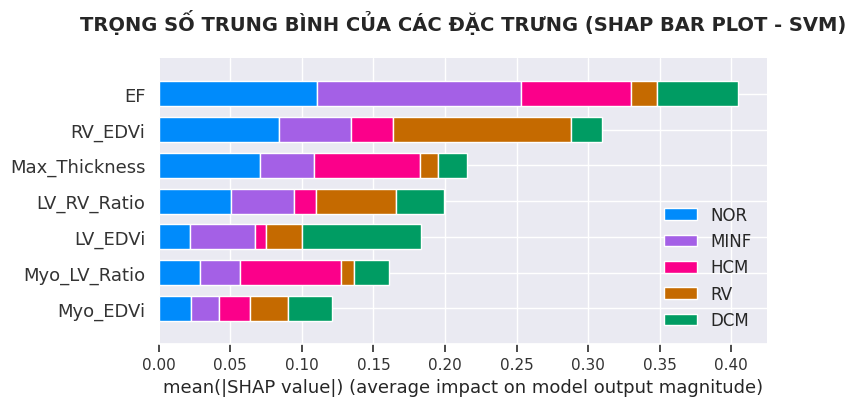


🔬 Đang trích xuất biểu đồ bầy ong chi tiết cho TOÀN BỘ 5 BỆNH...


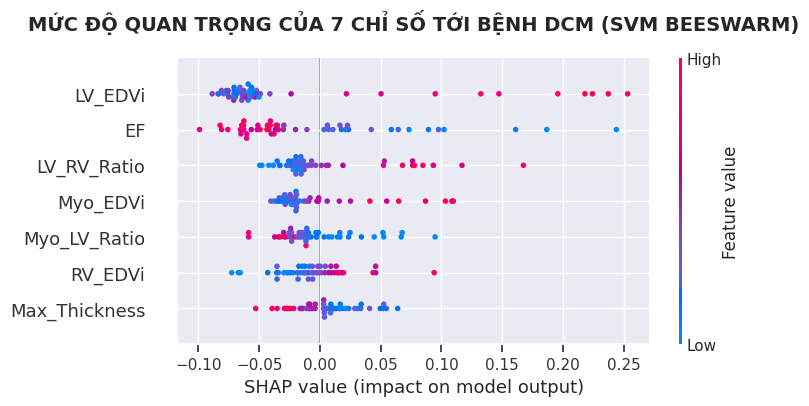

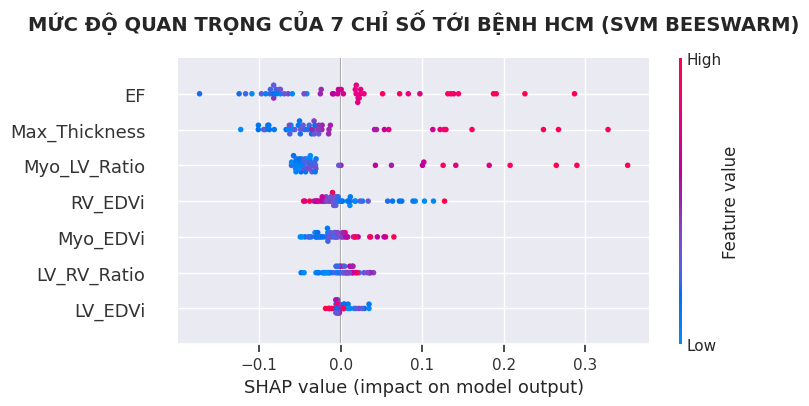

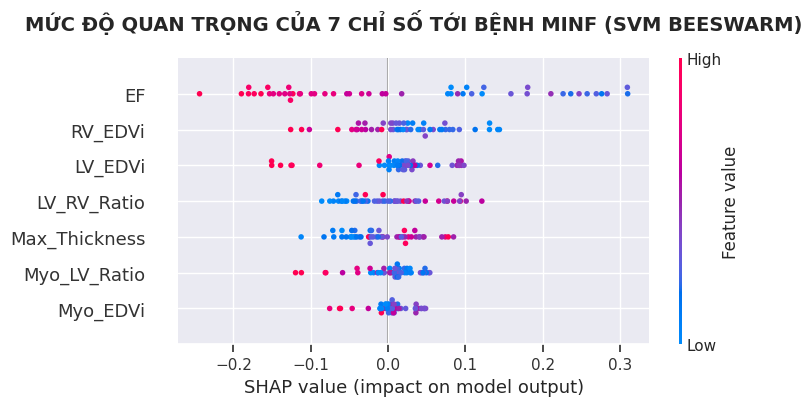

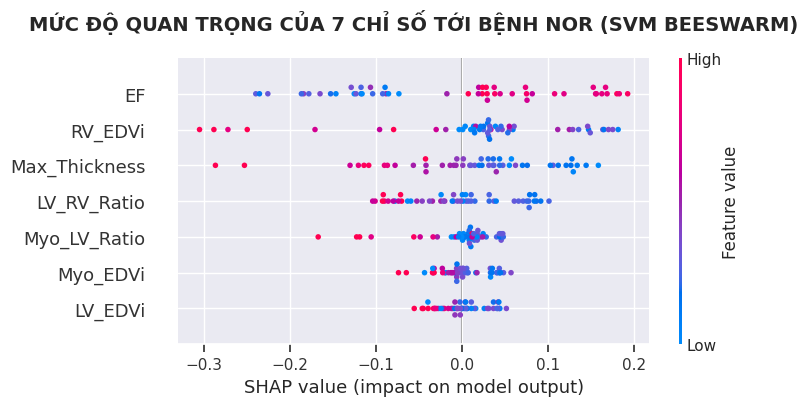

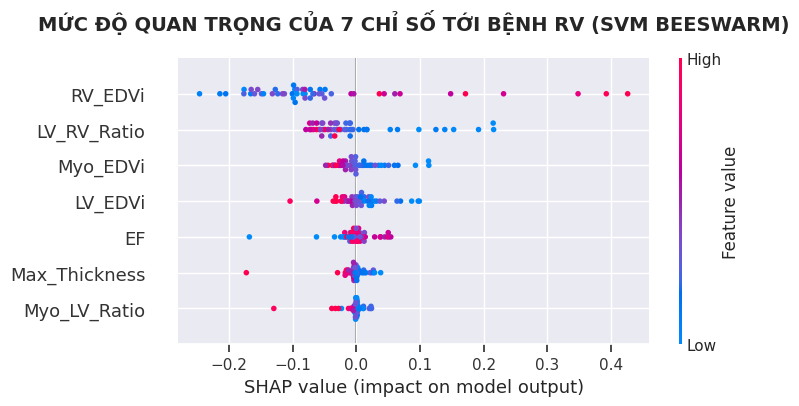

In [15]:
import warnings
# Ra lệnh cho Python nhắm mắt làm ngơ mấy cái cảnh báo tương lai
warnings.filterwarnings("ignore", category=FutureWarning) 

# ======================================================================
# 8. GIẢI THÍCH MÔ HÌNH VỚI SHAP (XAI CHO SVM)
# ======================================================================
import shap
import matplotlib.pyplot as plt
import numpy as np

print("\n🧠 Đang phân tích mức độ đóng góp của từng chỉ số y khoa bằng SHAP (cho SVM)...")
print("⏳ Lưu ý: SVM dùng KernelExplainer tính toán ma trận rất nặng nên sẽ hơi lâu một chút, má pha ly cà phê đợi xíu nha!")

# Lấy mô hình SVM đầu tiên từ hội đồng ra để phân tích đại diện
best_svm_model = ensemble_models[0]

# Khai báo lại tên 7 chỉ số lâm sàng y chang lúc má trích xuất
feature_names = ['LV_EDVi', 'RV_EDVi', 'Myo_EDVi', 'EF', 'LV_RV_Ratio', 'Myo_LV_Ratio', 'Max_Thickness']

# Cấu hình phông chữ an toàn
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# 1. Tạo bộ giải thích SHAP (Dùng KernelExplainer cho SVM)
# 🔥 SỬA CHỖ NÀY: Dùng dữ liệu ĐÃ CHUẨN HÓA (X_train_full_scaled) làm nền
background_data = shap.kmeans(X_train_full_scaled, 20)
explainer = shap.KernelExplainer(best_svm_model.predict_proba, background_data)

# 2. Tính toán SHAP values trên 50 bệnh nhân tập Test
# 🔥 SỬA CHỖ NÀY: Bắt buộc phải tính trên X_test_scaled
# Sẽ có thanh tiến trình (progress bar) hiện ra, má kiên nhẫn đợi nó chạy đủ 100% nha
shap_values = explainer.shap_values(X_test_scaled)

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: TỔNG QUAN 5 LỚP (BAR PLOT CỘT CHỒNG)
# ----------------------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.title("TRỌNG SỐ TRUNG BÌNH CỦA CÁC ĐẶC TRƯNG (SHAP BAR PLOT - SVM)", 
          fontsize=14, fontweight='bold', pad=20)

# 💡 MẸO HAY: Lúc vẽ vẫn giữ nguyên X_test (dữ liệu thô) để nhãn số hiển thị đẹp
shap.summary_plot(shap_values, X_test, 
                  feature_names=feature_names, 
                  class_names=label_encoder.classes_, 
                  plot_type="bar", 
                  show=False) 

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: SOI CHI TIẾT BẦY ONG (BEESWARM) CHO TOÀN BỘ 5 LỚP
# ----------------------------------------------------------------------
print("\n🔬 Đang trích xuất biểu đồ bầy ong chi tiết cho TOÀN BỘ 5 BỆNH...")

# Chạy vòng lặp qua từng tên bệnh trong Label Encoder (NOR, MINF, DCM, HCM, RV)
for i, class_name in enumerate(label_encoder.classes_):
    
    # Trích xuất SHAP values của riêng bệnh hiện tại (vị trí thứ i)
    if isinstance(shap_values, list):
        shap_class = shap_values[i]
    else:
        shap_class = shap_values[:, :, i]

    # Khởi tạo khung vẽ cho từng bệnh
    plt.figure(figsize=(10, 6))
    plt.title(f"MỨC ĐỘ QUAN TRỌNG CỦA 7 CHỈ SỐ TỚI BỆNH {class_name.upper()} (SVM BEESWARM)", 
              fontsize=14, fontweight='bold', pad=20)

    # 💡 MẸO HAY: Tương tự, truyền X_test để thanh màu bên phải là con số y khoa thật
    shap.summary_plot(shap_class, X_test, 
                      feature_names=feature_names, 
                      show=False)

    plt.tight_layout()
    plt.show()

# mlp

In [17]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
import pandas as pd
import numpy as np

# Đảm bảo các biến này đã tồn tại từ các bước trước
# (X_train_full_scaled, y_train_full, skf, SEED)

print("\n🤖 Đang huấn luyện MLP Hội Đồng với kiến trúc tinh chỉnh...")

# Khởi tạo list chứa các model
ensemble_models = []

# Vòng lặp huấn luyện
for tr_idx, val_idx in skf.split(X_train_full_scaled, y_train_full):
    # MLPClassifier hội tụ cực nhanh với lbfgs trên dữ liệu y tế
    m = MLPClassifier(
        hidden_layer_sizes=(32, 16), # Tăng độ phức tạp để học đặc trưng ẩn
        activation='relu',
        solver='lbfgs',             # Solver mạnh nhất cho data nhỏ
        alpha=0.5,                  # Tăng L2 regularization để tránh Overfit
        max_iter=5000,              # Tăng số vòng lặp tối đa
        random_state=SEED,
        learning_rate_init=0.001
    )
    m.fit(X_train_full_scaled[tr_idx], y_train_full[tr_idx])
    ensemble_models.append(m)

# Đánh giá trên tập Test
test_probs = np.zeros((len(X_test_scaled), len(label_encoder.classes_)))
for m in ensemble_models:
    test_probs += m.predict_proba(X_test_scaled)

final_preds = np.argmax(test_probs, axis=1)
acc = (final_preds == y_test).mean()

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC PHÂN LOẠI MLP HỘI ĐỒNG: {acc*100:.2f}%")
print("★" * 60)


🤖 Đang huấn luyện MLP Hội Đồng với kiến trúc tinh chỉnh...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC PHÂN LOẠI MLP HỘI ĐỒNG: 84.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


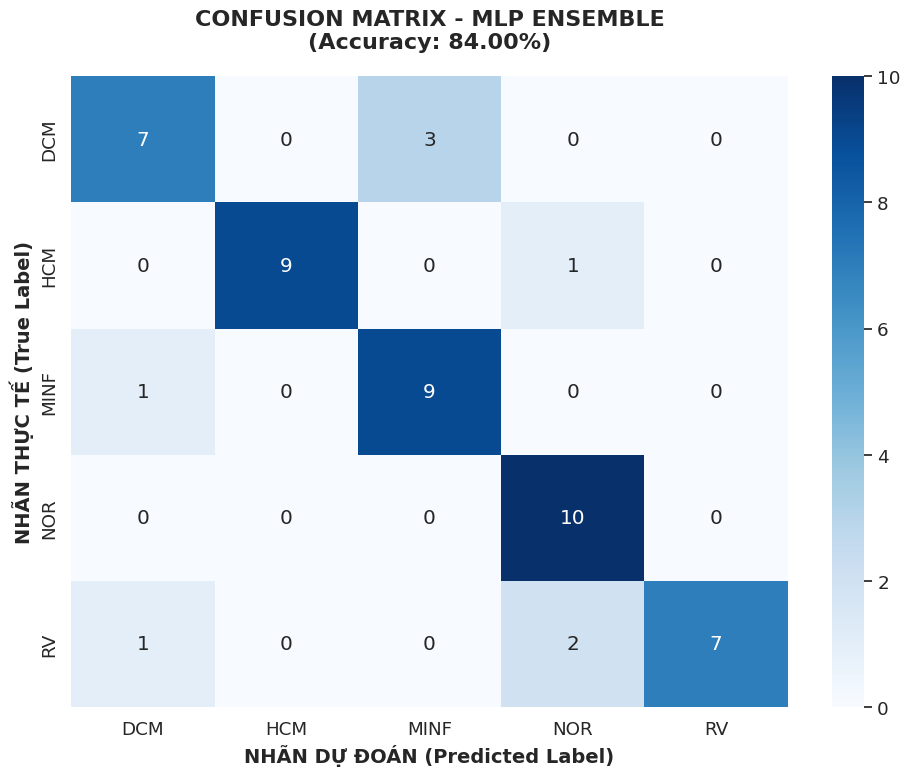


          CHI TIẾT CHỈ SỐ PHÂN LOẠI (MLP ENSEMBLE)          
              precision    recall  f1-score   support

         DCM       0.78      0.70      0.74        10
         HCM       1.00      0.90      0.95        10
        MINF       0.75      0.90      0.82        10
         NOR       0.77      1.00      0.87        10
          RV       1.00      0.70      0.82        10

    accuracy                           0.84        50
   macro avg       0.86      0.84      0.84        50
weighted avg       0.86      0.84      0.84        50



In [18]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lấy tên các lớp bệnh từ label_encoder để hiển thị lên trục tọa độ
class_names = label_encoder.classes_

# 2. Tính toán ma trận nhầm lẫn
# final_preds: Dự đoán cuối cùng từ hội đồng MLP (Soft Voting)
# y_test: Nhãn thật của bệnh nhân tập Test
cm = confusion_matrix(y_test, final_preds)

# 3. Vẽ biểu đồ bằng Seaborn
plt.figure(figsize=(10, 8))
sns.set_theme(font_scale=1.2) # Chỉnh kích thước chữ cho dễ đọc
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

# Đổi tiêu đề cho chuẩn với thuật toán MLP Hội Đồng
plt.title(f'CONFUSION MATRIX - MLP ENSEMBLE\n(Accuracy: {acc*100:.2f}%)', 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel('NHÃN THỰC TẾ (True Label)', fontsize=14, fontweight='bold')
plt.xlabel('NHÃN DỰ ĐOÁN (Predicted Label)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. In thêm bảng báo cáo chi tiết (Precision, Recall, F1-Score)
print("\n" + "="*60)
print(f"{'CHI TIẾT CHỈ SỐ PHÂN LOẠI (MLP ENSEMBLE)':^60}")
print("="*60)
print(classification_report(y_test, final_preds, target_names=class_names))
print("="*60)


📊 Đang tính toán mức độ quan trọng bằng Permutation Importance cho MLP...


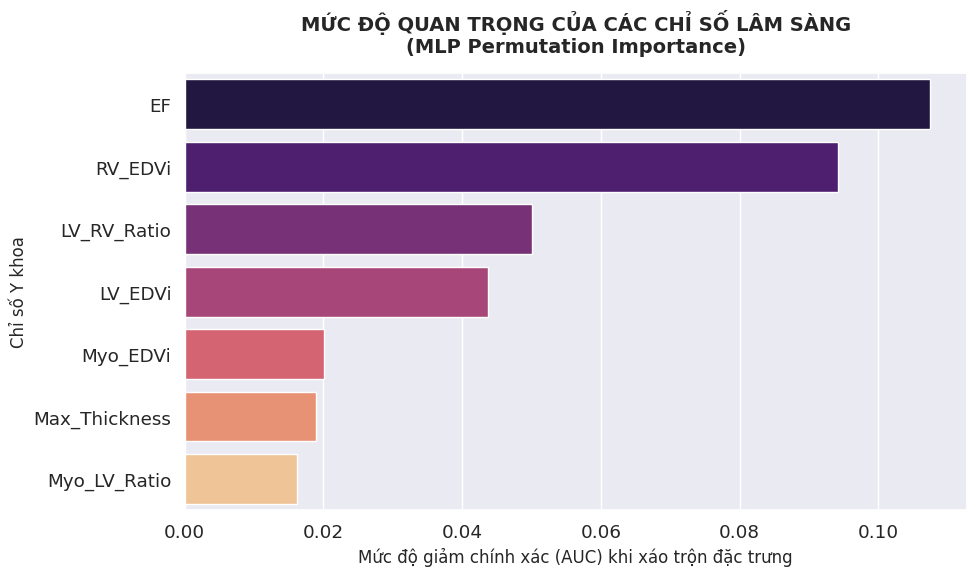


📈 Đang vẽ đường cong ROC (One-vs-Rest) cho 5 lớp bệnh lý...


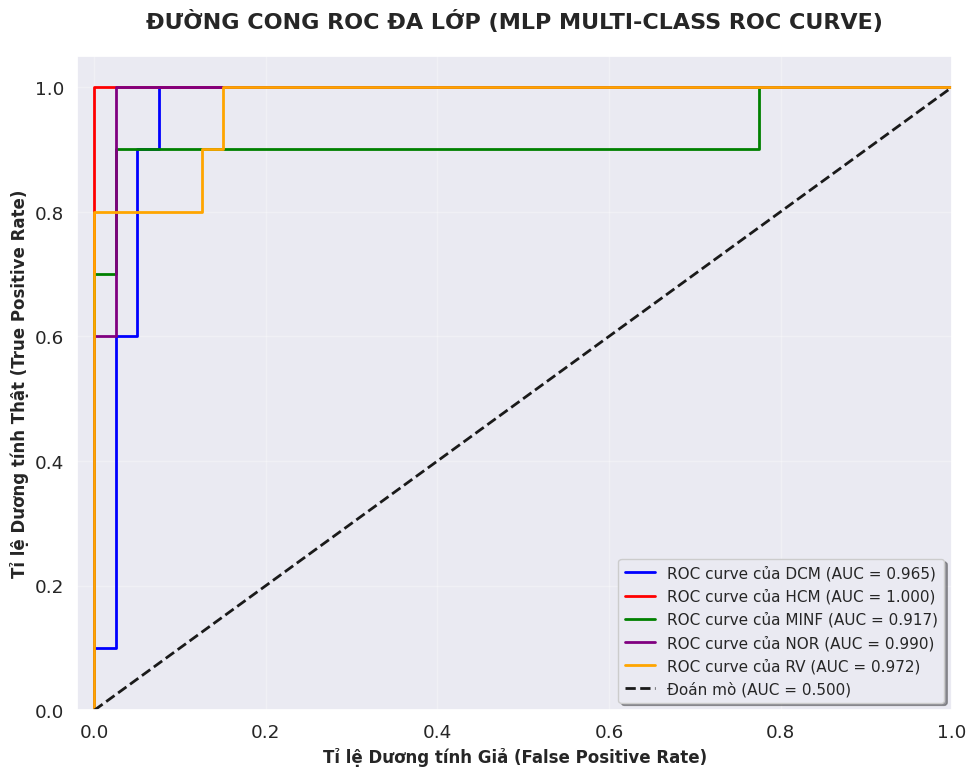

In [19]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.inspection import permutation_importance
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ======================================================================
# 8. ĐÁNH GIÁ SÂU: FEATURE IMPORTANCE VÀ ĐƯỜNG CONG ROC (MLP ENSEMBLE)
# ======================================================================

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: MỨC ĐỘ QUAN TRỌNG CỦA ĐẶC TRƯNG (PERMUTATION IMPORTANCE)
# ----------------------------------------------------------------------
print("\n📊 Đang tính toán mức độ quan trọng bằng Permutation Importance cho MLP...")

# Lấy tên các đặc trưng lâm sàng (giữ đúng thứ tự 7 chỉ số)
feature_names = df_test.drop('Label', axis=1).columns

# Dùng con mô hình MLP đầu tiên trong hội đồng để đánh giá đại diện
best_mlp_model = ensemble_models[0]

# Truyền X_test_scaled vào vì MLP đã được train trên tập chuẩn hóa Z-score
result = permutation_importance(
    best_mlp_model, X_test_scaled, y_test, 
    n_repeats=15, random_state=SEED, n_jobs=-1,
    scoring='roc_auc_ovo' # Dùng thước đo AUC để nhạy bén hơn với thay đổi xác suất đa lớp
)

# Lấy điểm trung bình và sắp xếp từ cao xuống thấp
importances = result.importances_mean
indices = np.argsort(importances)[::-1]
sorted_features = [feature_names[i] for i in indices]
sorted_importances = importances[indices]

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances, y=sorted_features, palette='magma')
plt.title('MỨC ĐỘ QUAN TRỌNG CỦA CÁC CHỈ SỐ LÂM SÀNG\n(MLP Permutation Importance)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức độ giảm chính xác (AUC) khi xáo trộn đặc trưng', fontsize=12)
plt.ylabel('Chỉ số Y khoa', fontsize=12)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: ĐƯỜNG CONG ROC VÀ CHỈ SỐ AUC (MULTI-CLASS)
# ----------------------------------------------------------------------
print("\n📈 Đang vẽ đường cong ROC (One-vs-Rest) cho 5 lớp bệnh lý...")

# Chuyển đổi nhãn thật y_test sang dạng One-Hot Encoding để tính ROC cho từng lớp
n_classes = len(label_encoder.classes_)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

# Tính toán Tỉ lệ dương tính giả (FPR), Tỉ lệ dương tính thật (TPR) và AUC cho từng lớp
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    # test_probs là biến đã có sẵn từ phần đánh giá (xác suất biểu quyết Soft Voting của 5 Folds)
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Bắt đầu vẽ ROC
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'purple', 'orange']

for i, color in zip(range(n_classes), colors):
    class_name = label_encoder.classes_[i]
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve của {class_name} (AUC = {roc_auc[i]:.3f})')

# Vẽ đường chéo ngẫu nhiên (Baseline)
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Đoán mò (AUC = 0.500)')

# Trang trí biểu đồ
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỉ lệ Dương tính Giả (False Positive Rate)', fontsize=12, fontweight='bold')
plt.ylabel('Tỉ lệ Dương tính Thật (True Positive Rate)', fontsize=12, fontweight='bold')
plt.title('ĐƯỜNG CONG ROC ĐA LỚP (MLP MULTI-CLASS ROC CURVE)', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

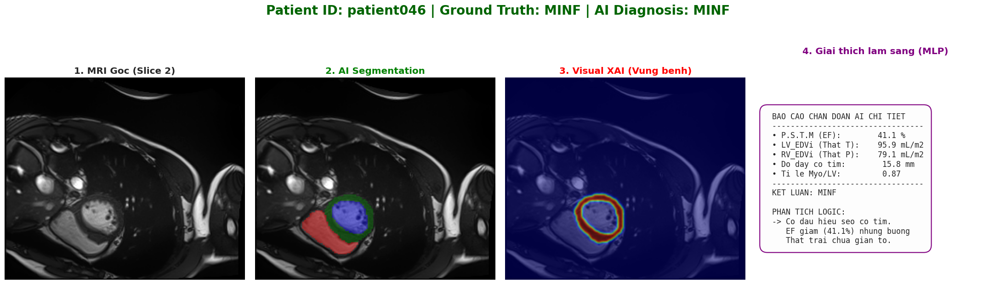

In [20]:
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy.ndimage as ndi
from matplotlib import rcParams
import nibabel as nib
import torch

# ======================================================================
# 7. HỆ THỐNG TRỰC QUAN HÓA XAI TOÀN DIỆN (MLP ENSEMBLE)
# ======================================================================

# Cấu hình phông chữ an toàn tránh lỗi ô vuông
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['DejaVu Sans']

def generate_detailed_report(metrics, pred_disease):
    """ Tạo nội dung giải thích lâm sàng chi tiết không dấu """
    ef = metrics['EF']
    lv_edvi = metrics['LV_EDVi']
    rv_edvi = metrics['RV_EDVi']
    m_thick = metrics['Max_Thickness']
    ratio = metrics['Myo_LV_Ratio']

    text =  " BAO CAO CHAN DOAN AI CHI TIET\n"
    text += " ---------------------------------\n"
    text += f" • P.S.T.M (EF):      {ef:>6.1f} %\n"
    text += f" • LV_EDVi (That T):  {lv_edvi:>6.1f} mL/m2\n"
    text += f" • RV_EDVi (That P):  {rv_edvi:>6.1f} mL/m2\n"
    text += f" • Do day co tim:      {m_thick:>6.1f} mm\n"
    text += f" • Ti le Myo/LV:       {ratio:>6.2f}\n"
    text += " ---------------------------------\n"
    text += f" KET LUAN: {pred_disease}\n\n"

    text += " PHAN TICH LOGIC:\n"
    if pred_disease == "DCM":
        text += f" -> EF thap ({ef:.1f}% < 40%) kem\n"
        text += f"    buong That trai gian rat to\n"
        text += f"    ({lv_edvi:.1f} > 100 mL/m2)."
    elif pred_disease == "HCM":
        text += f" -> Co tim phi dai bat thuong.\n"
        text += f"    Do day max ({m_thick:.1f}mm > 12mm)."
    elif pred_disease == "MINF":
        text += f" -> Co dau hieu seo co tim.\n"
        text += f"    EF giam ({ef:.1f}%) nhung buong\n"
        text += f"    That trai chua gian to."
    elif pred_disease in ["RV", "ARV"]: # Bao gồm cả RV hoặc ARV
        text += f" -> That phai gian to bat thuong\n"
        text += f"    ({rv_edvi:.1f} > 100 mL/m2).\n"
        text += f"    Nghi ngo tang ap luc phoi."
    else:
        text += " -> Cac chi so nam trong nguong\n"
        text += "    sinh ly binh thuong (Normal)."
    return text

def generate_abnormal_heatmap(mask, disease):
    """ Tự động tạo bản đồ nhiệt tập trung vào vùng nghi ngờ bệnh lý """
    heatmap = np.zeros_like(mask, dtype=np.float32)
    # Class 1: RV, Class 2: Myo, Class 3: LV
    if disease == "DCM":
        heatmap[mask == 3] = 1.0  # Bôi đỏ Tâm thất trái (LV)
    elif disease in ["HCM", "MINF"]:
        heatmap[mask == 2] = 1.0  # Bôi đỏ Cơ tim (Myo)
    elif disease in ["RV", "ARV"]:
        heatmap[mask == 1] = 1.0  # Bôi đỏ Tâm thất phải (RV)
    return heatmap

# 1. Chọn ngẫu nhiên 1 bệnh nhân từ tập Test
random_pid = random.choice(test_ids)
# Dùng index để lấy đúng số thứ tự của bệnh nhân trong mảng
patient_idx = test_ids.index(random_pid)
patient_metrics = df_test.iloc[patient_idx].to_dict()

# 2. Lấy dữ liệu ảnh gốc
data = patient_data[random_pid]
img_path = data['scans'][0][0] 
nib_img = nib.load(img_path)
img_np = nib_img.get_fdata().astype(np.float32)
dx, dy, dz = nib_img.header.get_zooms()

# 3. Chạy qua Mắt thần (Segmentation Model) để lấy Mask
zoom_in = (TARGET_SIZE[0]/img_np.shape[0], TARGET_SIZE[1]/img_np.shape[1], TARGET_SIZE[2]/img_np.shape[2])
img_resized = ndi.zoom(img_np, zoom_in, order=1)
img_input = torch.from_numpy((img_resized - img_resized.mean())/(img_resized.std()+1e-6))[None, None].to(DEVICE)

model.eval()
with torch.no_grad():
    out = model(img_input)
    # Xử lý nếu model là dạng tuple (giống DynUNet)
    if isinstance(out, (list, tuple)): out = out[0]
    pred_small = torch.argmax(out, dim=1).squeeze().cpu().numpy()

# Zoom mask về lại kích thước gốc để vẽ cho đẹp
inv_zoom = (img_np.shape[0]/TARGET_SIZE[0], img_np.shape[1]/TARGET_SIZE[1], img_np.shape[2]/TARGET_SIZE[2])
mask_full = ndi.zoom(pred_small, inv_zoom, order=0)

# 4. Đối chiếu kết quả
true_label_idx = y_test[patient_idx]
pred_label_idx = final_preds[patient_idx] # final_preds từ MLP Hội Đồng

true_disease = label_encoder.inverse_transform([true_label_idx])[0]
predicted_disease = label_encoder.inverse_transform([pred_label_idx])[0]

color_title = 'darkgreen' if predicted_disease == true_disease else 'darkred'

# 5. Tạo văn bản báo cáo & Bản đồ nhiệt
clinical_text = generate_detailed_report(patient_metrics, predicted_disease)
abnormal_heatmap = generate_abnormal_heatmap(mask_full, predicted_disease)

# 6. Vẽ Dashboard 4 khung
# Tìm lát cắt (slice) ở giữa tim có nhiều thông tin nhất
best_z = np.argmax(np.sum(mask_full > 0, axis=(0, 1))) 

plt.figure(figsize=(22, 7))
plt.suptitle(f"Patient ID: {random_pid} | Ground Truth: {true_disease} | AI Diagnosis: {predicted_disease} ", 
             fontsize=20, fontweight='bold', color=color_title)

# Khung 1: MRI Gốc
plt.subplot(1, 4, 1)
plt.title(f"1. MRI Goc (Slice {best_z})", fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
plt.axis('off')

# Khung 2: AI Segmentation
plt.subplot(1, 4, 2)
plt.title("2. AI Segmentation", color='green', fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
# Đỏ: RV, Xanh lá: Myo, Xanh dương: LV
cmap_seg = mcolors.ListedColormap(['none', 'red', 'green', 'blue'])
plt.imshow(np.rot90(mask_full[:, :, best_z]), cmap=cmap_seg, alpha=0.4, vmin=0, vmax=3)
plt.axis('off')

# Khung 3: Visual XAI (Chỉ bôi màu vùng bị bệnh)
plt.subplot(1, 4, 3)
plt.title("3. Visual XAI (Vung benh)", color='red', fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
h_slice = np.rot90(abnormal_heatmap[:, :, best_z])
h_slice = ndi.gaussian_filter(h_slice, sigma=1.5) # Làm mờ (blur)
if np.max(h_slice) > 0:
    plt.imshow(h_slice, cmap="jet", alpha=0.5)
plt.axis('off')

# Khung 4: Textual XAI (Báo cáo lập luận)
ax = plt.subplot(1, 4, 4)
plt.title("4. Giai thich lam sang (MLP)", color='purple', fontweight='bold')
ax.axis('off')
ax.text(0.05, 0.5, clinical_text, fontsize=12, family='monospace',
        verticalalignment='center', horizontalalignment='left',
        bbox=dict(boxstyle="round,pad=1", facecolor='#fdfdfd', edgecolor='purple', linewidth=1.5))

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


🧠 Đang phân tích mức độ đóng góp của từng chỉ số y khoa bằng SHAP (cho MLP)...
⏳ Lưu ý: MLP cũng là một mạng 'hộp đen' nên KernelExplainer tính toán sẽ hơi lâu một chút, má pha ly cà phê đợi xíu nha!


  0%|          | 0/50 [00:00<?, ?it/s]

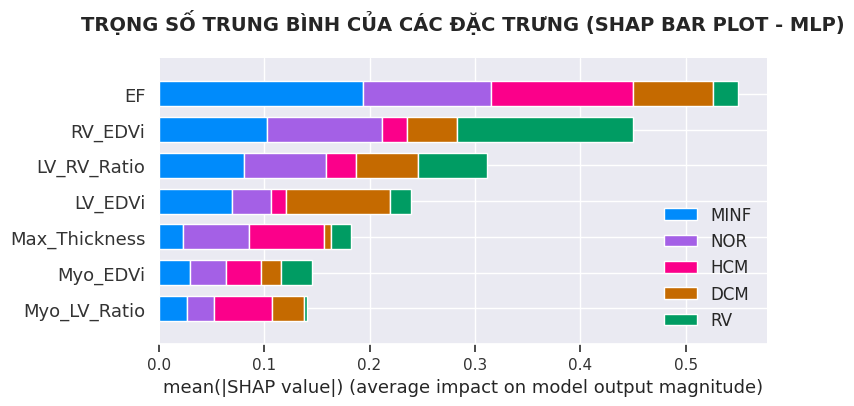


🔬 Đang trích xuất biểu đồ bầy ong chi tiết cho TOÀN BỘ 5 BỆNH...


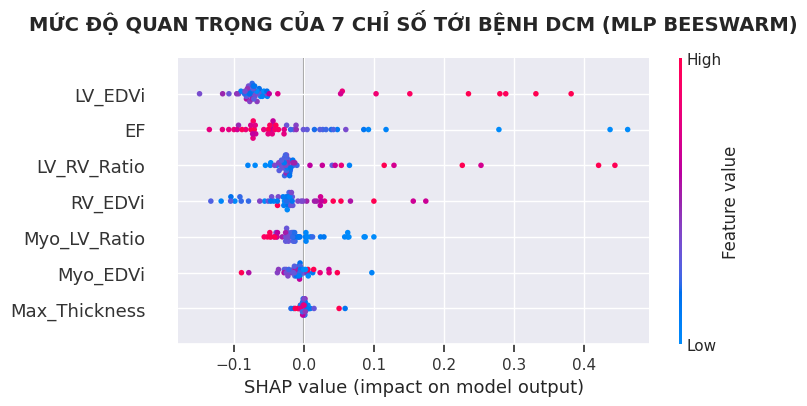

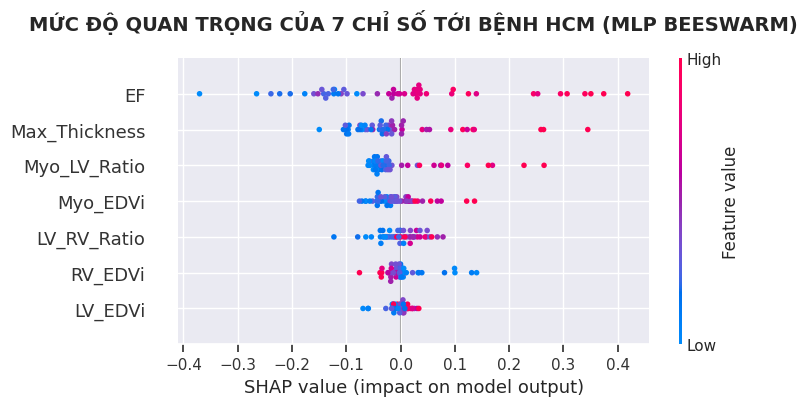

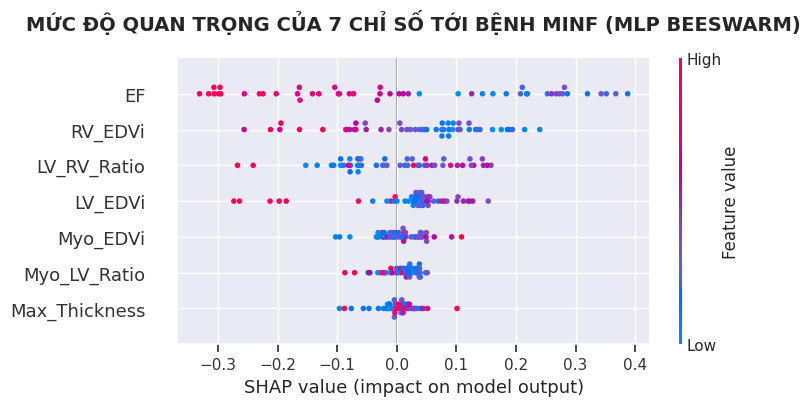

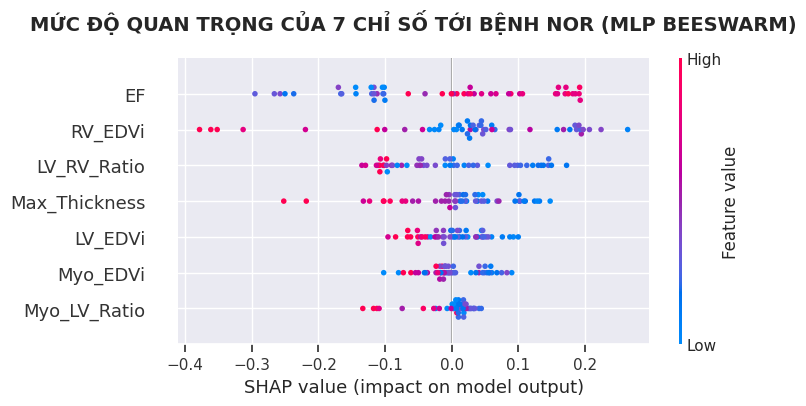

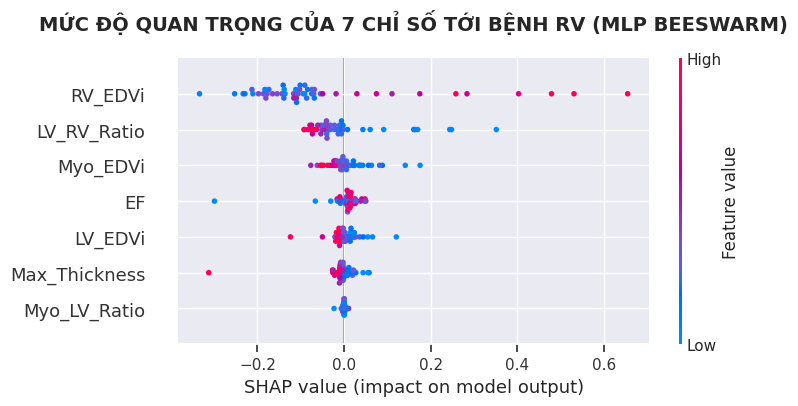

In [21]:
import warnings
# Ra lệnh cho Python nhắm mắt làm ngơ mấy cái cảnh báo tương lai
warnings.filterwarnings("ignore", category=FutureWarning) 

# ======================================================================
# 8. GIẢI THÍCH MÔ HÌNH VỚI SHAP (XAI CHO MLP)
# ======================================================================
import shap
import matplotlib.pyplot as plt
import numpy as np

print("\n🧠 Đang phân tích mức độ đóng góp của từng chỉ số y khoa bằng SHAP (cho MLP)...")
print("⏳ Lưu ý: MLP cũng là một mạng 'hộp đen' nên KernelExplainer tính toán sẽ hơi lâu một chút, má pha ly cà phê đợi xíu nha!")

# Lấy mô hình MLP đầu tiên từ hội đồng ra để phân tích đại diện
best_mlp_model = ensemble_models[0]

# Khai báo lại tên 7 chỉ số lâm sàng y chang lúc má trích xuất
feature_names = ['LV_EDVi', 'RV_EDVi', 'Myo_EDVi', 'EF', 'LV_RV_Ratio', 'Myo_LV_Ratio', 'Max_Thickness']

# Cấu hình phông chữ an toàn
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# 1. Tạo bộ giải thích SHAP (Dùng KernelExplainer cho mạng Nơ-ron)
# Dùng dữ liệu ĐÃ CHUẨN HÓA (X_train_full_scaled) làm nền
background_data = shap.kmeans(X_train_full_scaled, 20)
explainer = shap.KernelExplainer(best_mlp_model.predict_proba, background_data)

# 2. Tính toán SHAP values trên 50 bệnh nhân tập Test
# Bắt buộc phải tính trên X_test_scaled để mạng nơ-ron nhận diện đúng
# Sẽ có thanh tiến trình (progress bar) hiện ra, má kiên nhẫn đợi nha
shap_values = explainer.shap_values(X_test_scaled)

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: TỔNG QUAN 5 LỚP (BAR PLOT CỘT CHỒNG)
# ----------------------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.title("TRỌNG SỐ TRUNG BÌNH CỦA CÁC ĐẶC TRƯNG (SHAP BAR PLOT - MLP)", 
          fontsize=14, fontweight='bold', pad=20)

# MẸO HAY: Lúc vẽ vẫn giữ nguyên X_test (dữ liệu thô) để nhãn số hiển thị đẹp
shap.summary_plot(shap_values, X_test, 
                  feature_names=feature_names, 
                  class_names=label_encoder.classes_, 
                  plot_type="bar", 
                  show=False) 

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: SOI CHI TIẾT BẦY ONG (BEESWARM) CHO TOÀN BỘ 5 LỚP
# ----------------------------------------------------------------------
print("\n🔬 Đang trích xuất biểu đồ bầy ong chi tiết cho TOÀN BỘ 5 BỆNH...")

# Chạy vòng lặp qua từng tên bệnh trong Label Encoder (NOR, MINF, DCM, HCM, RV)
for i, class_name in enumerate(label_encoder.classes_):
    
    # Trích xuất SHAP values của riêng bệnh hiện tại (vị trí thứ i)
    if isinstance(shap_values, list):
        shap_class = shap_values[i]
    else:
        shap_class = shap_values[:, :, i]

    # Khởi tạo khung vẽ cho từng bệnh
    plt.figure(figsize=(10, 6))
    plt.title(f"MỨC ĐỘ QUAN TRỌNG CỦA 7 CHỈ SỐ TỚI BỆNH {class_name.upper()} (MLP BEESWARM)", 
              fontsize=14, fontweight='bold', pad=20)

    # MẸO HAY: Tương tự, truyền X_test để thanh màu bên phải là con số y khoa thật
    shap.summary_plot(shap_class, X_test, 
                      feature_names=feature_names, 
                      show=False)

    plt.tight_layout()
    plt.show()

# ensemble

In [22]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
import numpy as np
import pandas as pd

print("\n🤖 Đang huấn luyện SIÊU HỘI ĐỒNG (Soft Voting Ensemble)...")

# Chuẩn bị dữ liệu (Đảm bảo đã chạy các cell trước đó)
X_train_full = pd.concat([df_train, df_val]).drop('Label', axis=1).values
y_train_full = pd.concat([df_train, df_val])['Label'].values
X_test = df_test.drop('Label', axis=1).values
y_test = df_test['Label'].values

scaler = StandardScaler()
X_train_full_scaled = scaler.fit_transform(X_train_full)
X_test_scaled = scaler.transform(X_test)

# Huấn luyện hội đồng
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ensemble_models = []

for tr_idx, _ in skf.split(X_train_full_scaled, y_train_full):
    # Khởi tạo mô hình
    rf = RandomForestClassifier(n_estimators=250, max_depth=6, class_weight='balanced', random_state=SEED)
    svm = SVC(kernel='rbf', C=1.2, gamma='scale', probability=True, random_state=SEED)
    mlp = MLPClassifier(hidden_layer_sizes=(32, 16), solver='lbfgs', alpha=0.5, max_iter=5000, random_state=SEED)
    
    # Voting Classifier
    vclf = VotingClassifier(
        estimators=[('rf', rf), ('svm', svm), ('mlp', mlp)],
        voting='soft',
        weights=[2, 1, 2] 
    )
    
    vclf.fit(X_train_full_scaled[tr_idx], y_train_full[tr_idx])
    ensemble_models.append(vclf)

# Đánh giá
all_probs = np.array([m.predict_proba(X_test_scaled) for m in ensemble_models])
test_probs = np.mean(all_probs, axis=0)
final_preds = np.argmax(test_probs, axis=1)
acc = (final_preds == y_test).mean()

print("\n" + "★" * 60)
print(f"🎯 ĐỘ CHÍNH XÁC SIÊU HỘI ĐỒNG (RF+SVM+MLP): {acc*100:.2f}%")
print("★" * 60)



🤖 Đang huấn luyện SIÊU HỘI ĐỒNG (Soft Voting Ensemble)...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
🎯 ĐỘ CHÍNH XÁC SIÊU HỘI ĐỒNG (RF+SVM+MLP): 86.00%
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★


BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).


Extracting Features:   0%|          | 0/80 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/20 [00:00<?, ?it/s]

Extracting Features:   0%|          | 0/50 [00:00<?, ?it/s]

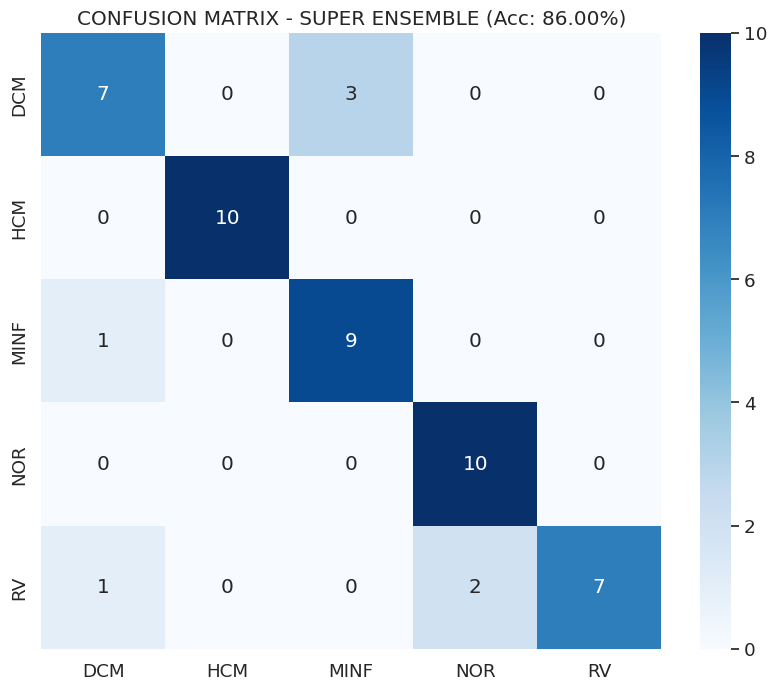

              precision    recall  f1-score   support

         DCM       0.78      0.70      0.74        10
         HCM       1.00      1.00      1.00        10
        MINF       0.75      0.90      0.82        10
         NOR       0.83      1.00      0.91        10
          RV       1.00      0.70      0.82        10

    accuracy                           0.86        50
   macro avg       0.87      0.86      0.86        50
weighted avg       0.87      0.86      0.86        50



In [23]:
import math, os
import numpy as np
import pandas as pd
import nibabel as nib
import scipy.ndimage as ndi
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from monai.networks.nets import BasicUNetPlusPlus

# ======================================================================
# 1. CẤU HÌNH & LOAD MODEL
# ======================================================================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_SIZE = (128, 128, 16)
SEED = 42

# Khởi tạo mô hình (Đảm bảo kiến trúc khớp với file .pth đã train)
model = BasicUNetPlusPlus(spatial_dims=3, in_channels=1, out_channels=4, features=(16, 32, 64, 128, 256, 16)).to(DEVICE)
model_path = "/kaggle/input/models/chaumaituanlam/unet-/pytorch/default/1/best_model (6).pth"
model.load_state_dict(torch.load(model_path, map_location=DEVICE), strict=True)
model.eval()

# ======================================================================
# 2. HÀM TRÍCH XUẤT ĐẶC TRƯNG LÂM SÀNG
# ======================================================================
def get_clinical_features(patient_list, model, device, label_encoder):
    all_features = []
    for pid in tqdm(patient_list, desc="Extracting Features"):
        data = patient_data[pid]
        p_dir = Path(data['scans'][0][0]).parent
        info_file = p_dir / "Info.cfg"
        height, weight, ed_f, es_f = 170.0, 70.0, 1, 1
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if "Height:" in line: height = float(line.split(":")[1])
                    elif "Weight:" in line: weight = float(line.split(":")[1])
                    elif "ED:" in line: ed_f = int(line.split(":")[1])
                    elif "ES:" in line: es_f = int(line.split(":")[1])
        
        bsa = math.sqrt((height * weight) / 3600.0)
        vols = {}
        for phase, f_idx in [("ED", ed_f), ("ES", es_f)]:
            img_path = next((s[0] for s in data['scans'] if f"frame{f_idx:02d}" in s[0]), data['scans'][0][0])
            img_data = nib.load(img_path).get_fdata().astype(np.float32)
            dx, dy, dz = nib.load(img_path).header.get_zooms()
            voxel_vol = (dx * dy * dz) / 1000.0
            
            img_in = ndi.zoom(img_data, (TARGET_SIZE[0]/img_data.shape[0], TARGET_SIZE[1]/img_data.shape[1], TARGET_SIZE[2]/img_data.shape[2]), order=1)
            img_in = (img_in - img_in.mean()) / (img_in.std() + 1e-6)
            
            with torch.no_grad():
                out = model(torch.from_numpy(img_in[None, None]).float().to(device))
                if isinstance(out, (list, tuple)): out = out[0]
                pred = torch.argmax(out, 1).squeeze().cpu().numpy()
            
            mask = ndi.zoom(pred, (img_data.shape[0]/TARGET_SIZE[0], img_data.shape[1]/TARGET_SIZE[1], img_data.shape[2]/TARGET_SIZE[2]), order=0)
            vols[phase] = {'RV': np.sum(mask == 1)*voxel_vol, 'Myo': np.sum(mask == 2)*voxel_vol, 'LV': np.sum(mask == 3)*voxel_vol, 'mask': mask, 'zooms': [dx, dy, dz]}

        lv_edv, lv_esv = vols['ED']['LV'], vols['ES']['LV']
        ef = ((lv_edv - lv_esv) / (lv_edv + 1e-6)) * 100
        lv_dist = ndi.distance_transform_edt(~(vols['ED']['mask'] == 3), sampling=vols['ED']['zooms'])
        max_thick = np.max(lv_dist * (vols['ED']['mask'] == 2)) if np.sum(vols['ED']['mask'] == 2) > 0 else 0

        all_features.append({
            'LV_EDVi': lv_edv/bsa, 'RV_EDVi': vols['ED']['RV']/bsa, 'Myo_EDVi': vols['ED']['Myo']/bsa,
            'EF': ef, 'LV_RV_Ratio': lv_edv/(vols['ED']['RV']+1e-6), 'Myo_LV_Ratio': vols['ED']['Myo']/(lv_edv+1e-6),
            'Max_Thickness': max_thick, 'Label': label_encoder.transform([data['disease']])[0]
        })
    return pd.DataFrame(all_features)

# ======================================================================
# 3. HUẤN LUYỆN & ĐÁNH GIÁ
# ======================================================================
label_encoder = LabelEncoder().fit([patient_data[pid]['disease'] for pid in patient_data])
df_train, df_val, df_test = get_clinical_features(train_ids, model, DEVICE, label_encoder), get_clinical_features(val_ids, model, DEVICE, label_encoder), get_clinical_features(test_ids, model, DEVICE, label_encoder)

X_train_full = pd.concat([df_train, df_val]).drop('Label', axis=1).values
y_train_full = pd.concat([df_train, df_val])['Label'].values
X_test, y_test = df_test.drop('Label', axis=1).values, df_test['Label'].values

scaler = StandardScaler().fit(X_train_full)
X_train_full_scaled, X_test_scaled = scaler.transform(X_train_full), scaler.transform(X_test)

ensemble_models = []
for tr_idx, _ in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train_full_scaled, y_train_full):
    vclf = VotingClassifier(estimators=[
        ('rf', RandomForestClassifier(n_estimators=250, max_depth=6, class_weight='balanced', random_state=SEED)),
        ('svm', SVC(kernel='rbf', C=1.2, probability=True, random_state=SEED)),
        ('mlp', MLPClassifier(hidden_layer_sizes=(32, 16), solver='lbfgs', alpha=0.5, max_iter=5000, random_state=SEED))
    ], voting='soft', weights=[2, 1, 2]).fit(X_train_full_scaled[tr_idx], y_train_full[tr_idx])
    ensemble_models.append(vclf)

test_probs = np.mean([m.predict_proba(X_test_scaled) for m in ensemble_models], axis=0)
final_preds = np.argmax(test_probs, axis=1)

# 
# Vẽ ma trận nhầm lẫn
cm = confusion_matrix(y_test, final_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f'CONFUSION MATRIX - SUPER ENSEMBLE (Acc: {accuracy_score(y_test, final_preds)*100:.2f}%)')
plt.show()

print(classification_report(y_test, final_preds, target_names=label_encoder.classes_))


📊 Đang tính toán mức độ quan trọng bằng Permutation Importance cho SIÊU HỘI ĐỒNG...


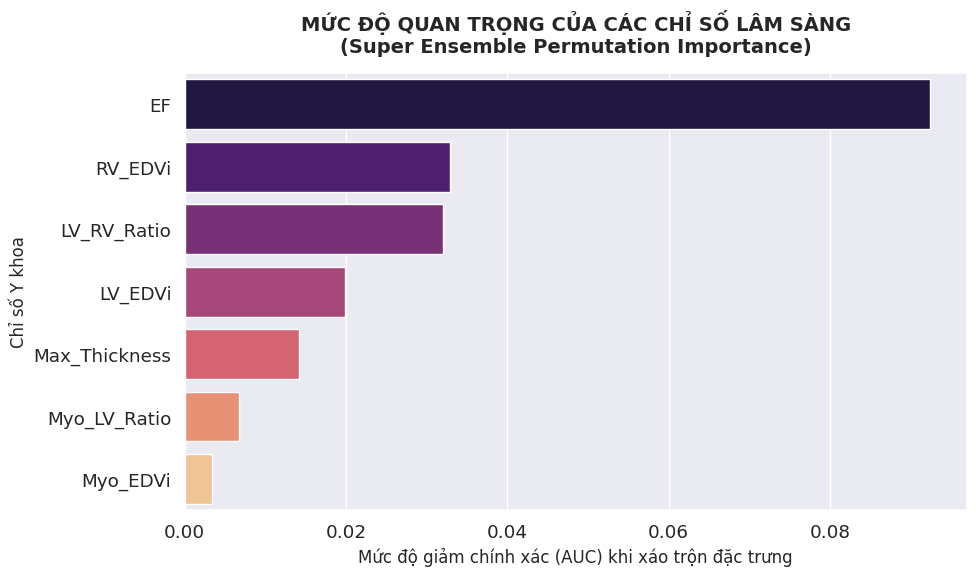


📈 Đang vẽ đường cong ROC (One-vs-Rest) cho 5 lớp bệnh lý...


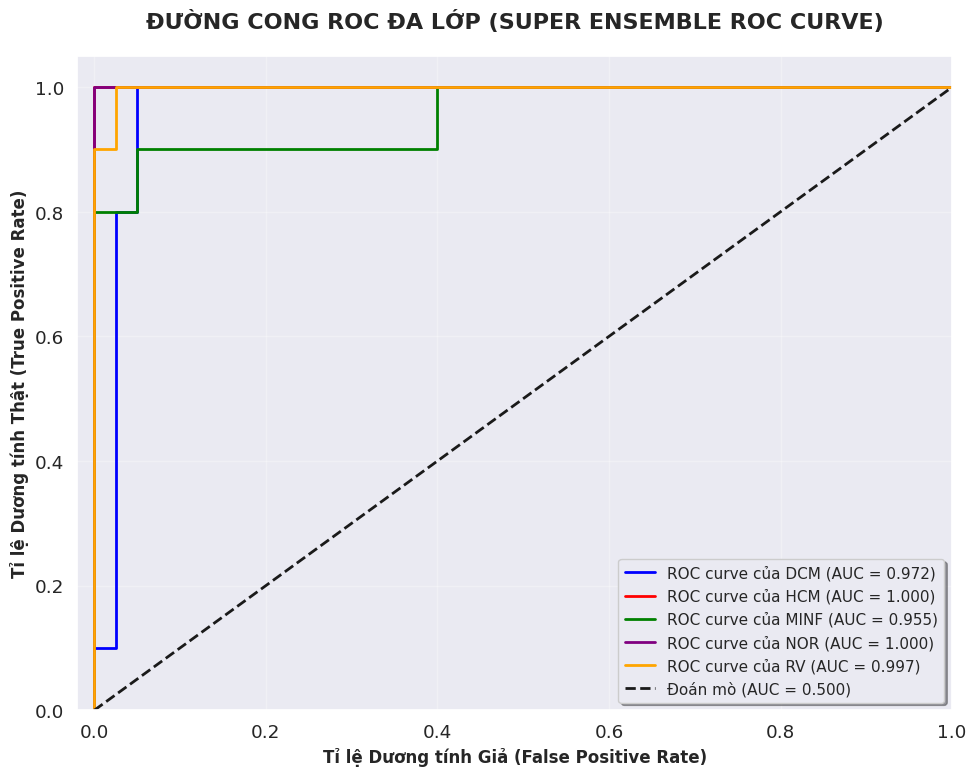

In [24]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.inspection import permutation_importance
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ======================================================================
# 8. ĐÁNH GIÁ SÂU: FEATURE IMPORTANCE VÀ ĐƯỜNG CONG ROC (SUPER ENSEMBLE)
# ======================================================================

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: MỨC ĐỘ QUAN TRỌNG CỦA ĐẶC TRƯNG (PERMUTATION IMPORTANCE)
# ----------------------------------------------------------------------
print("\n📊 Đang tính toán mức độ quan trọng bằng Permutation Importance cho SIÊU HỘI ĐỒNG...")

# Lấy tên các đặc trưng lâm sàng
feature_names = df_test.drop('Label', axis=1).columns

# Lấy cái Siêu Hội Đồng (VotingClassifier) đầu tiên ra làm đại diện
best_super_model = ensemble_models[0]

# Truyền X_test_scaled vào vì SVM và MLP bên trong rất cần dữ liệu đã chuẩn hóa
result = permutation_importance(
    best_super_model, X_test_scaled, y_test, 
    n_repeats=15, random_state=SEED, n_jobs=-1,
    scoring='roc_auc_ovo' # Thước đo tối ưu nhất cho đa lớp
)

# Lấy điểm trung bình và sắp xếp
importances = result.importances_mean
indices = np.argsort(importances)[::-1]
sorted_features = [feature_names[i] for i in indices]
sorted_importances = importances[indices]

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances, y=sorted_features, palette='magma')
plt.title('MỨC ĐỘ QUAN TRỌNG CỦA CÁC CHỈ SỐ LÂM SÀNG\n(Super Ensemble Permutation Importance)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức độ giảm chính xác (AUC) khi xáo trộn đặc trưng', fontsize=12)
plt.ylabel('Chỉ số Y khoa', fontsize=12)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: ĐƯỜNG CONG ROC VÀ CHỈ SỐ AUC (MULTI-CLASS)
# ----------------------------------------------------------------------
print("\n📈 Đang vẽ đường cong ROC (One-vs-Rest) cho 5 lớp bệnh lý...")

n_classes = len(label_encoder.classes_)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    # test_probs là xác suất Soft Voting của cả 3 thuật toán gộp lại (từ phần 8.5)
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green', 'purple', 'orange']

for i, color in zip(range(n_classes), colors):
    class_name = label_encoder.classes_[i]
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve của {class_name} (AUC = {roc_auc[i]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Đoán mò (AUC = 0.500)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỉ lệ Dương tính Giả (False Positive Rate)', fontsize=12, fontweight='bold')
plt.ylabel('Tỉ lệ Dương tính Thật (True Positive Rate)', fontsize=12, fontweight='bold')
plt.title('ĐƯỜNG CONG ROC ĐA LỚP (SUPER ENSEMBLE ROC CURVE)', fontsize=16, fontweight='bold', pad=20)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

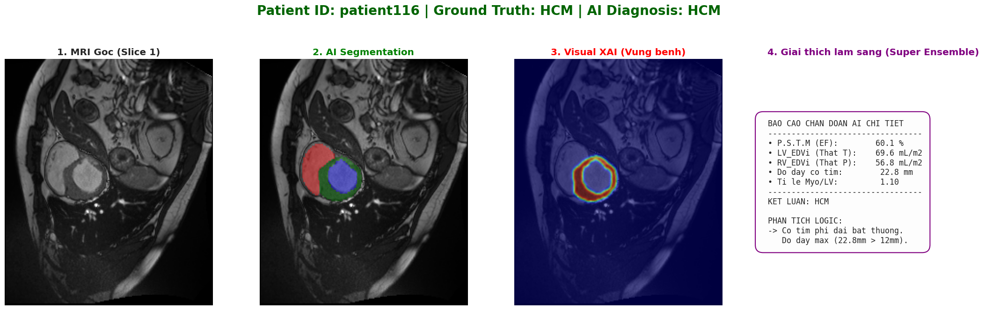

In [25]:
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scipy.ndimage as ndi
from matplotlib import rcParams
import nibabel as nib
import torch

# ======================================================================
# 7. HỆ THỐNG TRỰC QUAN HÓA XAI TOÀN DIỆN (SUPER ENSEMBLE)
# ======================================================================

rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['DejaVu Sans']

# ... (Giữ nguyên hàm generate_detailed_report và generate_abnormal_heatmap) ...
def generate_detailed_report(metrics, pred_disease):
    ef = metrics['EF']
    lv_edvi = metrics['LV_EDVi']
    rv_edvi = metrics['RV_EDVi']
    m_thick = metrics['Max_Thickness']
    ratio = metrics['Myo_LV_Ratio']

    text =  " BAO CAO CHAN DOAN AI CHI TIET\n"
    text += " ---------------------------------\n"
    text += f" • P.S.T.M (EF):      {ef:>6.1f} %\n"
    text += f" • LV_EDVi (That T):  {lv_edvi:>6.1f} mL/m2\n"
    text += f" • RV_EDVi (That P):  {rv_edvi:>6.1f} mL/m2\n"
    text += f" • Do day co tim:      {m_thick:>6.1f} mm\n"
    text += f" • Ti le Myo/LV:       {ratio:>6.2f}\n"
    text += " ---------------------------------\n"
    text += f" KET LUAN: {pred_disease}\n\n"
    text += " PHAN TICH LOGIC:\n"
    if pred_disease == "DCM":
        text += f" -> EF thap ({ef:.1f}% < 40%) kem\n"
        text += f"    buong That trai gian rat to\n"
        text += f"    ({lv_edvi:.1f} > 100 mL/m2)."
    elif pred_disease == "HCM":
        text += f" -> Co tim phi dai bat thuong.\n"
        text += f"    Do day max ({m_thick:.1f}mm > 12mm)."
    elif pred_disease == "MINF":
        text += f" -> Co dau hieu seo co tim.\n"
        text += f"    EF giam ({ef:.1f}%) nhung buong\n"
        text += f"    That trai chua gian to."
    elif pred_disease in ["RV", "ARV"]:
        text += f" -> That phai gian to bat thuong\n"
        text += f"    ({rv_edvi:.1f} > 100 mL/m2).\n"
        text += f"    Nghi ngo tang ap luc phoi."
    else:
        text += " -> Cac chi so nam trong nguong\n"
        text += "    sinh ly binh thuong (Normal)."
    return text

def generate_abnormal_heatmap(mask, disease):
    heatmap = np.zeros_like(mask, dtype=np.float32)
    if disease == "DCM":
        heatmap[mask == 3] = 1.0 
    elif disease in ["HCM", "MINF"]:
        heatmap[mask == 2] = 1.0 
    elif disease in ["RV", "ARV"]:
        heatmap[mask == 1] = 1.0 
    return heatmap

# Chọn ngẫu nhiên bệnh nhân
random_pid = random.choice(test_ids)
patient_idx = test_ids.index(random_pid)
patient_metrics = df_test.iloc[patient_idx].to_dict()

# Load ảnh và lấy Mask
data = patient_data[random_pid]
img_path = data['scans'][0][0] 
nib_img = nib.load(img_path)
img_np = nib_img.get_fdata().astype(np.float32)
dx, dy, dz = nib_img.header.get_zooms()

zoom_in = (TARGET_SIZE[0]/img_np.shape[0], TARGET_SIZE[1]/img_np.shape[1], TARGET_SIZE[2]/img_np.shape[2])
img_resized = ndi.zoom(img_np, zoom_in, order=1)
img_input = torch.from_numpy((img_resized - img_resized.mean())/(img_resized.std()+1e-6))[None, None].to(DEVICE)

model.eval()
with torch.no_grad():
    out = model(img_input)
    if isinstance(out, (list, tuple)): out = out[0]
    pred_small = torch.argmax(out, dim=1).squeeze().cpu().numpy()

inv_zoom = (img_np.shape[0]/TARGET_SIZE[0], img_np.shape[1]/TARGET_SIZE[1], img_np.shape[2]/TARGET_SIZE[2])
mask_full = ndi.zoom(pred_small, inv_zoom, order=0)

# Đối chiếu kết quả (Dùng final_preds của Super Ensemble)
true_label_idx = y_test[patient_idx]
pred_label_idx = final_preds[patient_idx] 

true_disease = label_encoder.inverse_transform([true_label_idx])[0]
predicted_disease = label_encoder.inverse_transform([pred_label_idx])[0]

color_title = 'darkgreen' if predicted_disease == true_disease else 'darkred'

clinical_text = generate_detailed_report(patient_metrics, predicted_disease)
abnormal_heatmap = generate_abnormal_heatmap(mask_full, predicted_disease)

best_z = np.argmax(np.sum(mask_full > 0, axis=(0, 1))) 

plt.figure(figsize=(22, 7))
plt.suptitle(f"Patient ID: {random_pid} | Ground Truth: {true_disease} | AI Diagnosis: {predicted_disease} ", 
             fontsize=20, fontweight='bold', color=color_title)

# Vẽ Dashboard
plt.subplot(1, 4, 1)
plt.title(f"1. MRI Goc (Slice {best_z})", fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title("2. AI Segmentation", color='green', fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
cmap_seg = mcolors.ListedColormap(['none', 'red', 'green', 'blue'])
plt.imshow(np.rot90(mask_full[:, :, best_z]), cmap=cmap_seg, alpha=0.4, vmin=0, vmax=3)
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title("3. Visual XAI (Vung benh)", color='red', fontweight='bold')
plt.imshow(np.rot90(img_np[:, :, best_z]), cmap="gray")
h_slice = np.rot90(abnormal_heatmap[:, :, best_z])
h_slice = ndi.gaussian_filter(h_slice, sigma=1.5)
if np.max(h_slice) > 0:
    plt.imshow(h_slice, cmap="jet", alpha=0.5)
plt.axis('off')

ax = plt.subplot(1, 4, 4)
# 🔥 Đổi tên báo cáo
plt.title("4. Giai thich lam sang (Super Ensemble)", color='purple', fontweight='bold')
ax.axis('off')
ax.text(0.05, 0.5, clinical_text, fontsize=12, family='monospace',
        verticalalignment='center', horizontalalignment='left',
        bbox=dict(boxstyle="round,pad=1", facecolor='#fdfdfd', edgecolor='purple', linewidth=1.5))

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


🧠 Đang phân tích mức độ đóng góp bằng SHAP (cho SUPER ENSEMBLE)...
🚨 CẢNH BÁO: Vì cấu trúc của Siêu Hội Đồng rất đồ sộ (RF+SVM+MLP) nên SHAP sẽ chạy RẤT LÂU.
🚨 Máy đang vắt kiệt sức lực để tính toán, má vui lòng kiên nhẫn đợi thanh tiến trình chạy xong nhé!


  0%|          | 0/50 [00:00<?, ?it/s]

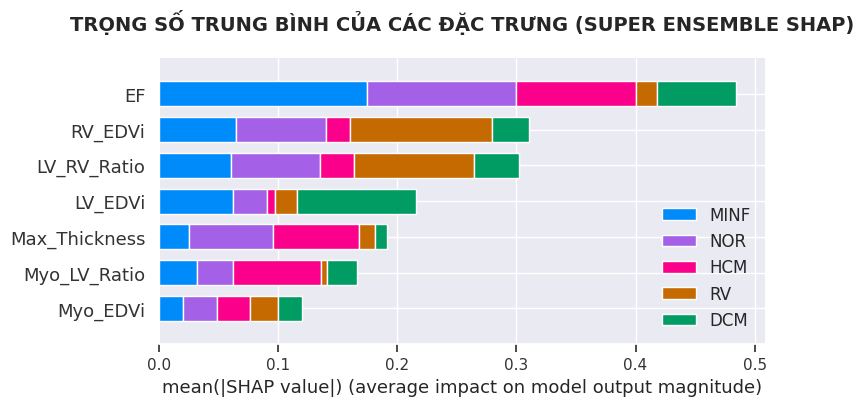


🔬 Đang trích xuất biểu đồ bầy ong chi tiết cho TOÀN BỘ 5 BỆNH...


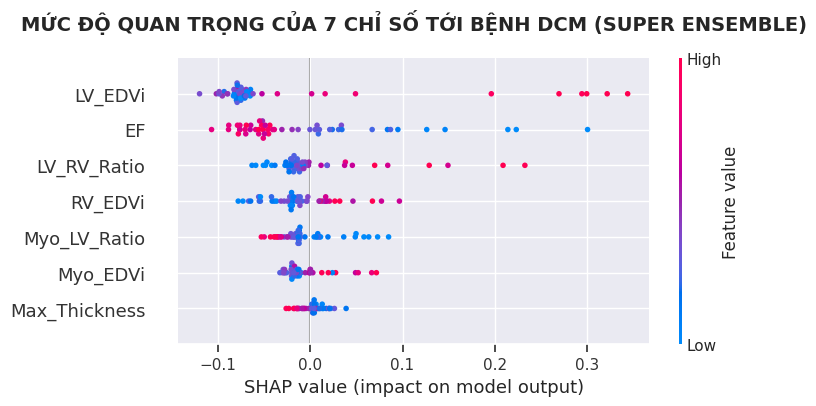

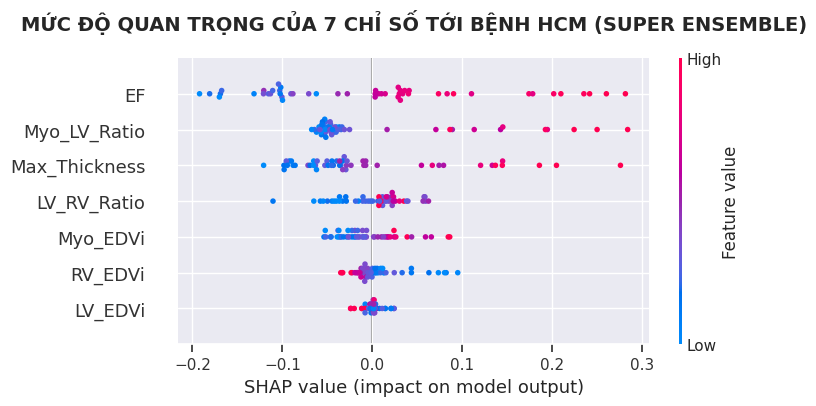

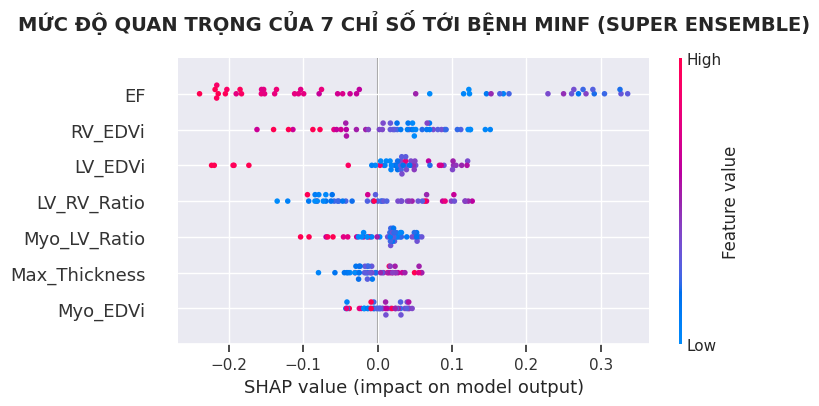

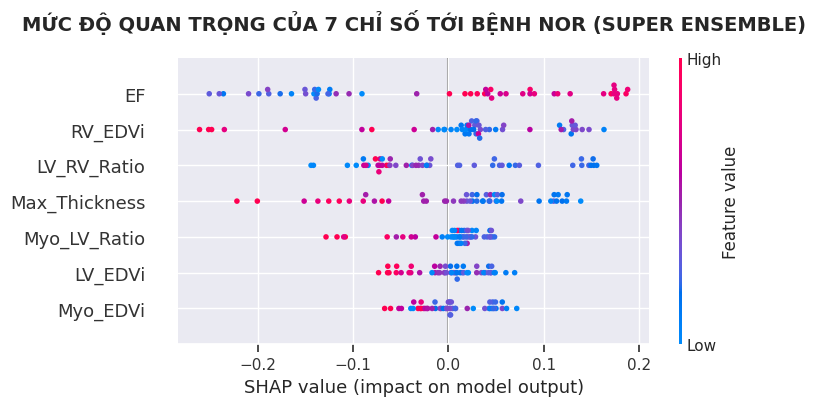

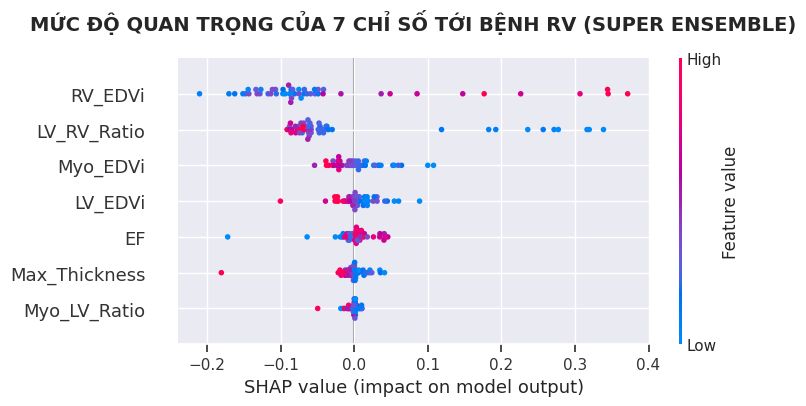

In [26]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning) 

# ======================================================================
# 9. GIẢI THÍCH MÔ HÌNH VỚI SHAP (XAI CHO SUPER ENSEMBLE)
# ======================================================================
import shap
import matplotlib.pyplot as plt
import numpy as np

print("\n🧠 Đang phân tích mức độ đóng góp bằng SHAP (cho SUPER ENSEMBLE)...")
print("🚨 CẢNH BÁO: Vì cấu trúc của Siêu Hội Đồng rất đồ sộ (RF+SVM+MLP) nên SHAP sẽ chạy RẤT LÂU.")
print("🚨 Máy đang vắt kiệt sức lực để tính toán, má vui lòng kiên nhẫn đợi thanh tiến trình chạy xong nhé!")

# Lấy Siêu Hội Đồng ra làm đại diện
best_super_model = ensemble_models[0]

feature_names = ['LV_EDVi', 'RV_EDVi', 'Myo_EDVi', 'EF', 'LV_RV_Ratio', 'Myo_LV_Ratio', 'Max_Thickness']

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# Dùng dữ liệu ĐÃ CHUẨN HÓA làm nền tảng
background_data = shap.kmeans(X_train_full_scaled, 20)
explainer = shap.KernelExplainer(best_super_model.predict_proba, background_data)

# ĐÚT X_test_scaled ĐỂ TÍNH TOÁN
shap_values = explainer.shap_values(X_test_scaled)

# ----------------------------------------------------------------------
# BIỂU ĐỒ 1: TỔNG QUAN 5 LỚP (BAR PLOT CỘT CHỒNG)
# ----------------------------------------------------------------------
plt.figure(figsize=(10, 6))
plt.title("TRỌNG SỐ TRUNG BÌNH CỦA CÁC ĐẶC TRƯNG (SUPER ENSEMBLE SHAP)", 
          fontsize=14, fontweight='bold', pad=20)

# MẸO: Lúc vẽ lại truyền dữ liệu X_test (THÔ) để số liệu y khoa hiển thị đẹp
shap.summary_plot(shap_values, X_test, 
                  feature_names=feature_names, 
                  class_names=label_encoder.classes_, 
                  plot_type="bar", 
                  show=False) 

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# BIỂU ĐỒ 2: SOI CHI TIẾT BẦY ONG (BEESWARM) CHO TOÀN BỘ 5 LỚP
# ----------------------------------------------------------------------
print("\n🔬 Đang trích xuất biểu đồ bầy ong chi tiết cho TOÀN BỘ 5 BỆNH...")

for i, class_name in enumerate(label_encoder.classes_):
    
    if isinstance(shap_values, list):
        shap_class = shap_values[i]
    else:
        shap_class = shap_values[:, :, i]

    plt.figure(figsize=(10, 6))
    plt.title(f"MỨC ĐỘ QUAN TRỌNG CỦA 7 CHỈ SỐ TỚI BỆNH {class_name.upper()} (SUPER ENSEMBLE)", 
              fontsize=14, fontweight='bold', pad=20)

    shap.summary_plot(shap_class, X_test, 
                      feature_names=feature_names, 
                      show=False)

    plt.tight_layout()
    plt.show()

In [3]:
import os, random, csv, time
from pathlib import Path
import numpy as np
import nibabel as nib
import scipy.ndimage as ndi
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from medpy.metric.binary import dc, jc, hd95
# [SỬA IMPORT] Load BasicUNetPlusPlus (U-Net++) từ MONAI
from monai.networks.nets import BasicUNetPlusPlus

# ---------------- 0. CONFIGURATION ----------------
BASE_DIR = Path("/kaggle/input/datasets/samdazel/automated-cardiac-diagnosis-challenge-miccai17/database")
TRAIN_DIR = BASE_DIR / "training"
TEST_DIR = BASE_DIR / "testing"

# Đổi tên thư mục lưu kết quả để không đè lên cái cũ
SAVE_DIR = Path("./unetplusplus3d_acdc_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128, 16)
NUM_CLASSES = 4
BATCH_SIZE = 2
EPOCHS = 100
LR = 1e-4
SEED = 89
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- 1. LOSS FUNCTIONS ----------------
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = F.softmax(pred, dim=1)
        target_oh = F.one_hot(target, NUM_CLASSES).permute(0,4,1,2,3).float()
        dims = (0,2,3,4)
        inter = torch.sum(pred[:,1:] * target_oh[:,1:], dims)
        union = torch.sum(pred[:,1:] + target_oh[:,1:], dims)
        return 1 - ((2*inter + self.smooth) / (union + self.smooth)).mean()

# ---------------- 2. DATASET ----------------
class VolumeDataset(Dataset):
    def __init__(self, items, augment=False):
        self.items = items
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_p, gt_p = self.items[idx]
        img = nib.load(img_p).get_fdata().astype(np.float32)
        gt  = nib.load(gt_p).get_fdata().astype(np.int64)

        zoom = (
            TARGET_SIZE[0] / img.shape[0],
            TARGET_SIZE[1] / img.shape[1],
            TARGET_SIZE[2] / img.shape[2]
        )
        img = ndi.zoom(img, zoom, order=1)
        gt  = ndi.zoom(gt,  zoom, order=0)

        if self.augment:
            if random.random() > 0.5:
                ax = random.randint(0,2)
                img = np.flip(img, ax).copy()
                gt  = np.flip(gt, ax).copy()

        img = (img - img.mean()) / (img.std() + 1e-6)

        return {
            "image": torch.from_numpy(img[None]).float(),
            "label": torch.from_numpy(gt).long()
        }

# ---------------- 3. METRICS ----------------
def get_metrics(p, g):
    res = {}
    for cl, name in zip([1,2,3], ['RV','MYO','LV']):
        pc, gc = (p==cl).astype(np.uint8), (g==cl).astype(np.uint8)
        if gc.sum() == 0:
            res[name] = (0.0, 0.0, 50.0)
            continue
        res[name] = (
            dc(pc, gc),
            jc(pc, gc),
            hd95(pc, gc) if pc.sum()>0 else 50.0
        )
    return res

# ---------------- 4. GỘP DATA & CHIA TẦNG ----------------
patient_data = {}
for folder_dir in [TRAIN_DIR, TEST_DIR]:
    if not folder_dir.exists(): continue
    for p in sorted(folder_dir.iterdir()):
        if not p.is_dir() or not p.name.startswith("patient"): continue
        
        pid = p.name
        info_file = p / "Info.cfg"
        disease = "NOR" 
        
        if info_file.exists():
            with open(info_file, 'r') as f:
                for line in f:
                    if line.startswith("Group:"): 
                        disease = line.split(":")[1].strip()
        
        gt_nodes = list(p.glob("*_frame*_gt.nii*"))
        scans = []
        for gt_node in gt_nodes:
            img_node = gt_node.parent / gt_node.name.replace("_gt", "")
            if img_node.exists():
                scans.append((str(img_node), str(gt_node)))
                
        if scans:
            patient_data[pid] = {'disease': disease, 'scans': scans}

p_ids = list(patient_data.keys())
p_labels = [patient_data[pid]['disease'] for pid in p_ids]

train_ids, temp_ids, train_labels, temp_labels = train_test_split(
    p_ids, p_labels, test_size=70, random_state=SEED, stratify=p_labels
)
val_ids, test_ids, val_labels, test_labels = train_test_split(
    temp_ids, temp_labels, test_size=50, random_state=SEED, stratify=temp_labels
)

tr_items = [scan for pid in train_ids for scan in patient_data[pid]['scans']]
va_items = [scan for pid in val_ids for scan in patient_data[pid]['scans']]
te_items = [scan for pid in test_ids for scan in patient_data[pid]['scans']]

print(f"✅ Đã chia tầng xong: Train {len(train_ids)} BN | Val {len(val_ids)} BN | Test {len(test_ids)} BN")
print(f"Tỉ lệ bệnh tập Test: {pd.Series(test_labels).value_counts().to_dict()}")

loaders = {
    "train": DataLoader(VolumeDataset(tr_items, True), BATCH_SIZE, shuffle=True),
    "val":   DataLoader(VolumeDataset(va_items), 1)
}

print("-"*170)

# ---------------- 5. MODEL ----------------
# [SỬA TẠI ĐÂY] Khởi tạo mô hình UNet++ (BasicUNetPlusPlus)
model = BasicUNetPlusPlus(
    spatial_dims=3,
    in_channels=1,
    out_channels=NUM_CLASSES,
    features=(16, 32, 64, 128, 256, 16), # Cấu hình số kênh (5 tầng encoder + 1 tầng upsample cuối)
    dropout=0.2
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, "max", patience=10, factor=0.5)

ce_criterion = nn.CrossEntropyLoss()
dice_criterion = DiceLoss()
scaler = torch.amp.GradScaler("cuda")

best_dice = 0.0

# ---------------- 6. CSV LOG ----------------
CSV_PATH = SAVE_DIR / "training_log.csv"
with open(CSV_PATH, "w", newline="") as f:
    csv.writer(f).writerow([
        "epoch","tr_loss","va_loss","tr_dice",
        "va_dice","va_iou","va_hd95",
        "rv_d","myo_d","lv_d","time" 
    ])

# ---------------- 7. TRAINING LOOP ----------------
for ep in range(1, EPOCHS+1):
    t0 = time.time()
    model.train()
    tr_l, tr_d = [], []

    for b in tqdm(loaders["train"], desc=f"Epoch {ep:02d}", leave=False):
        img = b["image"].to(DEVICE)
        lab = b["label"].to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            out = model(img)
            
            # [BẢO MẬT TYPE] UNet++ có thể trả về tuple/list nếu bật deep supervision.
            # Lấy tensor cuối cùng để đồng bộ với cấu trúc Loss cũ.
            if isinstance(out, (list, tuple)):
                out = out[0] if len(out) == 1 else out[-1]
                
            loss = ce_criterion(out, lab) + dice_criterion(out, lab)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        tr_l.append(loss.item())
        tr_d.append(dc((out.argmax(1)>0).cpu().numpy(), (lab>0).cpu().numpy()))

    # ---------------- VALIDATION ----------------
    model.eval()
    va_l, acc = [], {"RV":[], "MYO":[], "LV":[]}

    with torch.no_grad():
        for b in loaders["val"]:
            img = b["image"].to(DEVICE)
            lab = b["label"].to(DEVICE)

            with torch.amp.autocast("cuda"):
                out = model(img)
                if isinstance(out, (list, tuple)):
                    out = out[0] if len(out) == 1 else out[-1]
                    
                loss = ce_criterion(out, lab) + dice_criterion(out, lab)
            
            va_l.append(loss.item())

            p = out.argmax(1).cpu().numpy()[0]
            g = lab.cpu().numpy()[0]
            m = get_metrics(p, g)
            for k in acc: acc[k].append(m[k])

    tr_loss = np.mean(tr_l)
    va_loss = np.mean(va_l)
    tr_dice = np.mean(tr_d)

    stats = {k: np.mean(acc[k],0) for k in acc}
    va_dice = np.mean([stats[k][0] for k in stats])
    va_iou  = np.mean([stats[k][1] for k in stats])
    va_hd95 = np.mean([stats[k][2] for k in stats])

    scheduler.step(va_dice)
    t_total = time.time() - t0

    print(
        f"Ep {ep:02d} | {t_total:5.1f}s | "
        f"Tr.Loss {tr_loss:.4f} | Va.Loss {va_loss:.4f} | "
        f"Tr.Dice {tr_dice:.4f} | Va.Dice {va_dice:.4f} | "
        f"IoU {va_iou:.4f} | HD95 {va_hd95:.2f}"
    )

    with open(CSV_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            ep, tr_loss, va_loss, tr_dice,
            va_dice, va_iou, va_hd95,
            stats["RV"][0], stats["MYO"][0], stats["LV"][0], t_total
        ])

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), SAVE_DIR/"best_model.pth")
        print(f"New Best Model Saved | Dice {best_dice:.4f}")

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
2026-06-08 07:47:07.491488: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780904827.734054      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780904827.800263      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780904828.333302      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780904828.333343      57 computation_placer.cc:1

✅ Đã chia tầng xong: Train 80 BN | Val 20 BN | Test 50 BN
Tỉ lệ bệnh tập Test: {'DCM': 10, 'HCM': 10, 'NOR': 10, 'MINF': 10, 'RV': 10}
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------
BasicUNetPlusPlus features: (16, 32, 64, 128, 256, 16).


Ep 01 |  38.9s | Tr.Loss 2.2558 | Va.Loss 2.1258 | Tr.Dice 0.1065 | Va.Dice 0.1876 | IoU 0.1263 | HD95 52.23
New Best Model Saved | Dice 0.1876


Ep 02 |  29.7s | Tr.Loss 2.1051 | Va.Loss 2.0340 | Tr.Dice 0.1295 | Va.Dice 0.2825 | IoU 0.2009 | HD95 31.48
New Best Model Saved | Dice 0.2825


Ep 03 |  30.5s | Tr.Loss 2.0207 | Va.Loss 1.9501 | Tr.Dice 0.1498 | Va.Dice 0.4387 | IoU 0.3332 | HD95 28.34
New Best Model Saved | Dice 0.4387


Ep 04 |  29.8s | Tr.Loss 1.9399 | Va.Loss 1.8668 | Tr.Dice 0.2484 | Va.Dice 0.5399 | IoU 0.4015 | HD95 24.36
New Best Model Saved | Dice 0.5399


... (92 outputs left out)

Ep 97 |  31.2s | Tr.Loss 0.1653 | Va.Loss 0.1719 | Tr.Dice 0.9399 | Va.Dice 0.8660 | IoU 0.7722 | HD95 1.72
New Best Model Saved | Dice 0.8660


Ep 98 |  31.2s | Tr.Loss 0.1685 | Va.Loss 0.1774 | Tr.Dice 0.9384 | Va.Dice 0.8620 | IoU 0.7656 | HD95 1.71


Ep 99 |  31.2s | Tr.Loss 0.1676 | Va.Loss 0.1716 | Tr.Dice 0.9393 | Va.Dice 0.8660 | IoU 0.7721 | HD95 1.80


Ep 100 |  31.5s | Tr.Loss 0.1633 | Va.Loss 0.1704 | Tr.Dice 0.9415 | Va.Dice 0.8671 | IoU 0.7738 | HD95 1.97
New Best Model Saved | Dice 0.8671
